# 07 - Bowler Performance Analysis

**Objective:** Evaluating bowlers in high-pressure situations: economy rate, dot ball frequency, wicket threat, and death bowling efficiency.

---
### supeRR Selector Pressure Analysis


In [1]:
# Setup and imports
import sys
from pathlib import Path

# Ensure src module is accessible
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.append(str(PROJECT_ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from superr_selector.data.loader import DataLoader

%matplotlib inline
print('Environment initialized successfully.')


Environment initialized successfully.


## 1. Load Datasets


In [2]:
# STEP 1: Bowler analysis environment and data availability

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Project root:", PROJECT_ROOT)
print("Raw data directory exists:", RAW_DIR.exists())
print("Processed data directory exists:", PROCESSED_DIR.exists())

print("\nRequired raw files:")

required_files = [
    "ball_by_ball.csv",
    "matches.csv",
    "competitions.csv",
]

for filename in required_files:
    path = RAW_DIR / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

print("\nPreviously saved batter outputs:")

for filename in [
    "preliminary_batter_top10.csv",
    "all_eligible_batter_scores.csv",
]:
    path = PROCESSED_DIR / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

Project root: d:\PROJECTS\supeRR-selector-pressure-analysis
Raw data directory exists: True
Processed data directory exists: True

Required raw files:
ball_by_ball.csv: FOUND
matches.csv: FOUND
competitions.csv: FOUND

Previously saved batter outputs:
preliminary_batter_top10.csv: FOUND
all_eligible_batter_scores.csv: FOUND


In [3]:
# STEP 2: Load raw datasets and inspect bowler-related columns

ball_df = pd.read_csv(RAW_DIR / "ball_by_ball.csv")
matches_df = pd.read_csv(RAW_DIR / "matches.csv")
competitions_df = pd.read_csv(RAW_DIR / "competitions.csv")

print("DATASET SHAPES")
print("Ball-by-ball:", ball_df.shape)
print("Matches:", matches_df.shape)
print("Competitions:", competitions_df.shape)

print("\nBOWLER-RELATED COLUMNS")

bowler_columns = [
    "match_id",
    "innings",
    "overid",
    "over_ball_num",
    "bowler_id",
    "bowler_name",
    "runs",
    "extras_type",
    "extras1_runs",
    "extras_2_runs",
    "is_wicket",
    "dismissal_type",
    "dismissed_player_id"
]

display(ball_df[bowler_columns].head(10))

print("\nUNIQUE BOWLERS:", ball_df["bowler_id"].nunique())
print("MISSING BOWLER IDs:", ball_df["bowler_id"].isna().sum())

print("\nDISMISSAL TYPES")
display(
    ball_df.loc[ball_df["is_wicket"] == 1, "dismissal_type"]
    .value_counts(dropna=False)
    .to_frame("count")
)

DATASET SHAPES
Ball-by-ball: (200999, 33)
Matches: (883, 22)
Competitions: (141, 4)

BOWLER-RELATED COLUMNS


,match_id,innings,overid,over_ball_num,bowler_id,bowler_name,runs,extras_type,extras1_runs,extras_2_runs,is_wicket,dismissal_type,dismissed_player_id
0,13511,1,1,1,1772,Sheldon Cottrell,0,NaN,0,0,False,NaN,NaN
1,13511,1,1,2,1772,Sheldon Cottrell,0,NaN,0,0,False,NaN,NaN
2,13511,1,1,3,1772,Sheldon Cottrell,0,NaN,0,0,False,NaN,NaN
3,13511,1,1,4,1772,Sheldon Cottrell,0,NaN,0,0,False,NaN,NaN
4,13511,1,1,5,1772,Sheldon Cottrell,6,NaN,0,0,False,NaN,NaN
5,13511,1,1,6,1772,Sheldon Cottrell,0,NaN,0,0,True,Bowled,1187.0
6,13511,1,2,1,2633,Jason Holder,0,NaN,0,0,False,NaN,NaN
7,13511,1,2,2,2633,Jason Holder,0,NaN,0,0,False,NaN,NaN
8,13511,1,2,3,2633,Jason Holder,0,NaN,0,0,False,NaN,NaN
9,13511,1,2,4,2633,Jason Holder,4,NaN,0,0,False,NaN,NaN



UNIQUE BOWLERS: 647
MISSING BOWLER IDs: 0

DISMISSAL TYPES


,count
dismissal_type,
Caught,7557
Bowled,1775
LBW,709
RunOut,600
Stump,214
Hit Wicket,17
Retire Out,6
Obstracting the field,2
Obstructing the field,1


In [4]:
# STEP 3: Classify and audit bowler-credited wickets

bowler_credited_dismissals = [
    "Caught",
    "Bowled",
    "LBW",
    "Stump",
    "Hit Wicket"
]

non_bowler_credited_dismissals = [
    "RunOut",
    "Retire Out",
    "Obstracting the field",
    "Obstructing the field"
]

# Create a separate analysis copy
bowler_df = ball_df.copy()

# Normalize dismissal labels for classification
dismissal_clean = (
    bowler_df["dismissal_type"]
    .fillna("")
    .astype(str)
    .str.strip()
)

bowler_df["bowler_credited_wicket"] = (
    dismissal_clean.isin(bowler_credited_dismissals)
).astype(int)

bowler_df["non_bowler_credited_wicket"] = (
    dismissal_clean.isin(non_bowler_credited_dismissals)
).astype(int)

# Audit wicket attribution
wicket_audit = (
    bowler_df[bowler_df["is_wicket"] == True]
    .groupby("dismissal_type", dropna=False)
    .agg(
        recorded_wickets=("is_wicket", "size"),
        bowler_credited=("bowler_credited_wicket", "sum"),
        non_bowler_credited=("non_bowler_credited_wicket", "sum")
    )
    .sort_values("recorded_wickets", ascending=False)
)

print("WICKET ATTRIBUTION AUDIT")
display(wicket_audit)

print("\nTOTALS")
print("Recorded wickets:", int(bowler_df["is_wicket"].sum()))
print(
    "Bowler-credited wickets:",
    int(bowler_df["bowler_credited_wicket"].sum())
)
print(
    "Non-bowler-credited wickets:",
    int(bowler_df["non_bowler_credited_wicket"].sum())
)

print(
    "\nAttribution reconciliation:",
    int(bowler_df["is_wicket"].sum())
    == (
        int(bowler_df["bowler_credited_wicket"].sum())
        + int(bowler_df["non_bowler_credited_wicket"].sum())
    )
)

WICKET ATTRIBUTION AUDIT


,recorded_wickets,bowler_credited,non_bowler_credited
dismissal_type,,,
Caught,7557,7557,0
Bowled,1775,1775,0
LBW,709,709,0
RunOut,600,0,600
Stump,214,214,0
Hit Wicket,17,17,0
Retire Out,6,0,6
Obstracting the field,2,0,2
Obstructing the field,1,0,1



TOTALS
Recorded wickets: 10881
Bowler-credited wickets: 10272
Non-bowler-credited wickets: 609

Attribution reconciliation: True


In [5]:
# STEP 4: Audit extras categories and run components

print("EXTRAS TYPE DISTRIBUTION")

extras_audit = (
    bowler_df.groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        batter_runs=("runs", "sum"),
        extras1_runs=("extras1_runs", "sum"),
        extras2_runs=("extras_2_runs", "sum"),
        wickets=("is_wicket", "sum")
    )
    .sort_values("deliveries", ascending=False)
)

display(extras_audit)

# Inspect unresolved or unusual extras categories
print("\nUNUSUAL EXTRAS — DETAILED AUDIT")

unusual_categories = ["other", "Penalty"]

unusual_extras = bowler_df[
    bowler_df["extras_type"].isin(unusual_categories)
    | (
        bowler_df["extras_type"].isna()
        & (
            bowler_df["extras1_runs"].fillna(0).gt(0)
            | bowler_df["extras_2_runs"].fillna(0).gt(0)
        )
    )
]

display(
    unusual_extras[
        [
            "match_id",
            "innings",
            "overid",
            "over_ball_num",
            "bowler_name",
            "runs",
            "extras_type",
            "extras1_runs",
            "extras_2_runs",
            "is_wicket",
            "dismissal_type"
        ]
    ].head(30)
)

print("\nUNUSUAL EXTRAS SUMMARY")
print("Records:", len(unusual_extras))
print("Total batter runs:", unusual_extras["runs"].sum())
print("Total extras1 runs:", unusual_extras["extras1_runs"].sum())
print("Total extras2 runs:", unusual_extras["extras_2_runs"].sum())
print("Total wickets:", unusual_extras["is_wicket"].sum())

EXTRAS TYPE DISTRIBUTION


,deliveries,batter_runs,extras1_runs,extras2_runs,wickets
extras_type,,,,,
NaN,189167,268285,1,1,10832
wide,7714,0,9174,0,40
legbyes,2748,1,3603,0,0
Overstep,576,852,576,48,5
byes,529,0,1000,0,1
other,264,412,264,35,3
Penalty,1,0,5,0,0



UNUSUAL EXTRAS — DETAILED AUDIT


,match_id,innings,overid,over_ball_num,bowler_name,runs,extras_type,extras1_runs,extras_2_runs,is_wicket,dismissal_type
532,13513,1,10,1,Tymal Mills,0,other,1,0,False,NaN
1079,13515,1,16,6,Saqib Mahmood,0,other,1,0,False,NaN
1226,13515,2,19,5,Sheldon Cottrell,2,other,1,0,False,NaN
2588,13614,1,18,5,Mitchell Starc,0,other,1,4,False,NaN
2609,13614,2,2,1,Nuwan Thushara,0,other,1,0,False,NaN
3309,14094,1,19,7,Shivam Mavi,6,other,1,0,False,NaN
4413,14098,2,20,1,Nathan Coulter Nile,0,other,1,0,False,NaN
5012,14101,1,17,4,Tim Southee,0,other,1,0,False,NaN
5365,14102,2,19,9,Prasidh Krishna,0,other,1,0,True,RunOut
6575,14107,2,16,5,Daniel Sams,2,other,1,0,False,NaN



UNUSUAL EXTRAS SUMMARY
Records: 267
Total batter runs: 412
Total extras1 runs: 270
Total extras2 runs: 36
Total wickets: 3


In [6]:
# STEP 5: Detailed audit of unresolved extras and Overstep

category = (
    bowler_df["extras_type"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Missing category with positive extras
missing_positive = bowler_df[
    (category == "")
    & (
        bowler_df["extras1_runs"].fillna(0).gt(0)
        | bowler_df["extras_2_runs"].fillna(0).gt(0)
    )
]

# Inspect all Overstep records
overstep_records = bowler_df[
    category == "overstep"
]

# Summarize the uncertain categories
print("MISSING CATEGORY WITH POSITIVE EXTRAS")
display(
    missing_positive[
        [
            "match_id", "innings", "overid", "over_ball_num",
            "bowler_name", "runs", "extras1_runs",
            "extras_2_runs", "is_wicket", "dismissal_type"
        ]
    ]
)

print("\nOVERSTEP SUMMARY")
print("Records:", len(overstep_records))
print("Batter runs:", overstep_records["runs"].sum())
print("Extras1 runs:", overstep_records["extras1_runs"].sum())
print("Extras2 runs:", overstep_records["extras_2_runs"].sum())
print("Wickets:", overstep_records["is_wicket"].sum())

print("\nOVERSTEP DISMISSAL TYPES")
display(
    overstep_records["dismissal_type"]
    .value_counts(dropna=False)
    .to_frame("count")
)

print("\nOTHER CATEGORY — EXTRAS COMPONENTS")
display(
    bowler_df.loc[
        category == "other",
        ["extras1_runs", "extras_2_runs"]
    ].value_counts(dropna=False).to_frame("deliveries")
)

MISSING CATEGORY WITH POSITIVE EXTRAS


,match_id,innings,overid,over_ball_num,bowler_name,runs,extras1_runs,extras_2_runs,is_wicket,dismissal_type
36854,17555,1,5,4,Haris Rauf,0,0,1,False,NaN
107489,36097,2,8,6,Romario Shepherd,0,1,0,False,NaN



OVERSTEP SUMMARY
Records: 576
Batter runs: 852
Extras1 runs: 576
Extras2 runs: 48
Wickets: 5

OVERSTEP DISMISSAL TYPES


,count
dismissal_type,
NaN,571
RunOut,5



OTHER CATEGORY — EXTRAS COMPONENTS


deliveries
extras1_runs extras_2_runs            
1            0                     250
             1                       7
             4                       7

In [7]:
# STEP 6: Quantify known and unresolved bowler-run components

category = (
    bowler_df["extras_type"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

bowler_df["batter_runs_component"] = (
    bowler_df["runs"].fillna(0)
)

bowler_df["wide_runs_component"] = np.where(
    category == "wide",
    bowler_df["extras1_runs"].fillna(0),
    0
)

bowler_df["overstep_penalty_component"] = np.where(
    category == "overstep",
    bowler_df["extras1_runs"].fillna(0),
    0
)

# Extras whose classification or attribution remains unresolved
unresolved_mask = (
    category.isin(["other", "penalty"])
    | (
        (category == "")
        & (
            bowler_df["extras1_runs"].fillna(0).gt(0)
            | bowler_df["extras_2_runs"].fillna(0).gt(0)
        )
    )
)

bowler_df["unresolved_extras_component"] = np.where(
    unresolved_mask,
    (
        bowler_df["extras1_runs"].fillna(0)
        + bowler_df["extras_2_runs"].fillna(0)
    ),
    0
)

component_summary = pd.DataFrame({
    "component": [
        "Batter runs",
        "Wide extras1",
        "Overstep penalty",
        "Unresolved extras1 + extras2"
    ],
    "runs": [
        bowler_df["batter_runs_component"].sum(),
        bowler_df["wide_runs_component"].sum(),
        bowler_df["overstep_penalty_component"].sum(),
        bowler_df["unresolved_extras_component"].sum()
    ]
})

display(component_summary)

print("\nUNRESOLVED CATEGORY BREAKDOWN")

display(
    bowler_df.loc[unresolved_mask]
    .groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        batter_runs=("runs", "sum"),
        extras1=("extras1_runs", "sum"),
        extras2=("extras_2_runs", "sum")
    )
)

print("\nKNOWN BOWLER-CHARGEABLE RUNS:")
print(
    int(
        bowler_df["batter_runs_component"].sum()
        + bowler_df["wide_runs_component"].sum()
        + bowler_df["overstep_penalty_component"].sum()
    )
)

,component,runs
0,Batter runs,269550
1,Wide extras1,9174
2,Overstep penalty,576
3,Unresolved extras1 + extras2,306



UNRESOLVED CATEGORY BREAKDOWN


,deliveries,batter_runs,extras1,extras2
extras_type,,,,
Penalty,1,0,5,0
other,264,412,264,35
NaN,2,0,1,1



KNOWN BOWLER-CHARGEABLE RUNS:
279300


In [8]:
# STEP 7: Corrected bowler-chargeable run uncertainty audit

category = (
    bowler_df["extras_type"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Known bowler-chargeable components
bowler_df["known_bowler_runs"] = (
    bowler_df["runs"].fillna(0)
    + np.where(
        category == "wide",
        bowler_df["extras1_runs"].fillna(0),
        0
    )
    + np.where(
        category == "overstep",
        bowler_df["extras1_runs"].fillna(0),
        0
    )
)

# All extras2 components remain unresolved until their semantics are verified.
# Also retain extras1 for other, Penalty and missing-category records.
unresolved_mask = (
    category.isin(["other", "penalty"])
    | (
        (category == "")
        & (
            bowler_df["extras1_runs"].fillna(0).gt(0)
            | bowler_df["extras_2_runs"].fillna(0).gt(0)
        )
    )
    | bowler_df["extras_2_runs"].fillna(0).gt(0)
)

bowler_df["unresolved_bowler_runs"] = np.where(
    unresolved_mask,
    (
        bowler_df["extras1_runs"].fillna(0)
        + bowler_df["extras_2_runs"].fillna(0)
    ),
    0
)

known_total = int(bowler_df["known_bowler_runs"].sum())
unresolved_total = int(bowler_df["unresolved_bowler_runs"].sum())

print("CORRECTED RUN ATTRIBUTION")
print("Known bowler runs:", known_total)
print("Unresolved extras:", unresolved_total)
print("Provisional lower bound:", known_total)
print("Provisional upper bound:", known_total + unresolved_total)

print("\nUNRESOLVED BREAKDOWN BY CATEGORY")

display(
    bowler_df.loc[unresolved_mask]
    .groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        extras1=("extras1_runs", "sum"),
        extras2=("extras_2_runs", "sum"),
        unresolved_total=("unresolved_bowler_runs", "sum")
    )
)

CORRECTED RUN ATTRIBUTION
Known bowler runs: 279300
Unresolved extras: 375
Provisional lower bound: 279300
Provisional upper bound: 279675

UNRESOLVED BREAKDOWN BY CATEGORY


,deliveries,extras1,extras2,unresolved_total
extras_type,,,,
Overstep,21,21,48,69
Penalty,1,5,0,5
other,264,264,35,299
NaN,2,1,1,2


In [9]:
# STEP 8: Final corrected unresolved extras accounting

category = (
    bowler_df["extras_type"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

extras1 = bowler_df["extras1_runs"].fillna(0)
extras2 = bowler_df["extras_2_runs"].fillna(0)

# Overstep extras1 is already counted in known_bowler_runs.
# Only its extras2 component remains unresolved.
unresolved_components = np.select(
    [
        category == "overstep",
        category.isin(["other", "penalty"]),
        (category == "") & ((extras1 > 0) | (extras2 > 0))
    ],
    [
        extras2,
        extras1 + extras2,
        extras1 + extras2
    ],
    default=0
)

bowler_df["unresolved_bowler_runs"] = unresolved_components

known_total = int(bowler_df["known_bowler_runs"].sum())
unresolved_total = int(bowler_df["unresolved_bowler_runs"].sum())

print("FINAL RUN ATTRIBUTION AUDIT")
print("Known bowler runs:", known_total)
print("Unresolved extras:", unresolved_total)
print("Provisional lower bound:", known_total)
print("Provisional upper bound:", known_total + unresolved_total)

print("\nUNRESOLVED BREAKDOWN")

display(
    bowler_df.loc[bowler_df["unresolved_bowler_runs"] > 0]
    .groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        unresolved_runs=("unresolved_bowler_runs", "sum")
    )
)

FINAL RUN ATTRIBUTION AUDIT
Known bowler runs: 279300
Unresolved extras: 354
Provisional lower bound: 279300
Provisional upper bound: 279654

UNRESOLVED BREAKDOWN


,deliveries,unresolved_runs
extras_type,,
Overstep,21,48
Penalty,1,5
other,264,299
NaN,2,2


In [10]:
# STEP 9: Legal delivery classification and audit

category = (
    bowler_df["extras_type"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

extras1 = bowler_df["extras1_runs"].fillna(0)
extras2 = bowler_df["extras_2_runs"].fillna(0)

# Initialize classification
bowler_df["legal_status"] = "unresolved"

# Explicitly illegal deliveries
bowler_df.loc[
    category.isin(["wide", "overstep"]),
    "legal_status"
] = "illegal"

# Explicitly legal deliveries
bowler_df.loc[
    category.isin(["legbyes", "byes"]),
    "legal_status"
] = "legal"

# Ordinary deliveries with no recorded extras
bowler_df.loc[
    (category == "") & (extras1 == 0) & (extras2 == 0),
    "legal_status"
] = "legal"

# Audit classification
legal_summary = (
    bowler_df.groupby("legal_status")
    .agg(
        deliveries=("match_id", "size"),
        batter_runs=("runs", "sum"),
        bowler_credited_wickets=("bowler_credited_wicket", "sum")
    )
    .reindex(["legal", "illegal", "unresolved"])
)

display(legal_summary)

print("\nTOTAL CLASSIFIED DELIVERIES:",
      int(legal_summary["deliveries"].sum()))

print("\nLEGAL-BALL COUNT BOUNDS")

legal_count = int((bowler_df["legal_status"] == "legal").sum())
illegal_count = int((bowler_df["legal_status"] == "illegal").sum())
unresolved_count = int((bowler_df["legal_status"] == "unresolved").sum())

print("Confirmed/provisionally legal:", legal_count)
print("Illegal:", illegal_count)
print("Minimum possible legal balls:", legal_count)
print("Maximum possible legal balls:", legal_count + unresolved_count)
print("Unresolved deliveries:", unresolved_count)

print("\nUNRESOLVED CATEGORY AUDIT")

display(
    bowler_df.loc[bowler_df["legal_status"] == "unresolved"]
    .groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        extras1=("extras1_runs", "sum"),
        extras2=("extras_2_runs", "sum")
    )
)

,deliveries,batter_runs,bowler_credited_wickets
legal_status,,,
legal,192442,268286,10247
illegal,8290,852,25
unresolved,267,412,0



TOTAL CLASSIFIED DELIVERIES: 200999

LEGAL-BALL COUNT BOUNDS
Confirmed/provisionally legal: 192442
Illegal: 8290
Minimum possible legal balls: 192442
Maximum possible legal balls: 192709
Unresolved deliveries: 267

UNRESOLVED CATEGORY AUDIT


,deliveries,extras1,extras2
extras_type,,,
Penalty,1,5,0
other,264,264,35
NaN,2,1,1


In [11]:
# STEP 10: Inspect competition metadata for the analysis scope

competition_audit = (
    matches_df[["match_id", "comp_id"]]
    .drop_duplicates()
    .merge(
        competitions_df[
            ["comp_id", "comp_name", "match_format", "season"]
        ].drop_duplicates(),
        on="comp_id",
        how="left",
        indicator=True
    )
)

print("MATCH-TO-COMPETITION JOIN")
print(competition_audit["_merge"].value_counts(dropna=False))

print("\nAVAILABLE MATCH FORMATS")
display(
    competition_audit["match_format"]
    .value_counts(dropna=False)
    .rename_axis("match_format")
    .to_frame("matches")
)

print("\nCOMPETITIONS FROM SEASON 2022 ONWARD")
display(
    competition_audit.loc[
        pd.to_numeric(competition_audit["season"], errors="coerce") >= 2022
    ]
    .groupby(
        ["comp_name", "match_format", "season"],
        dropna=False
    )
    .agg(matches=("match_id", "nunique"))
    .reset_index()
    .sort_values(["match_format", "season", "comp_name"])
    .to_string(index=False)
)

MATCH-TO-COMPETITION JOIN
_merge
both          883
left_only       0
right_only      0
Name: count, dtype: int64

AVAILABLE MATCH FORMATS


,matches
match_format,
T20I,482
T20,401



COMPETITIONS FROM SEASON 2022 ONWARD


'                                              comp_name match_format season  matches\n                                               IPL 2022          T20   2022       74\n                                               IPL 2023          T20   2023       74\n                                               IPL 2024          T20   2024       74\n                  Mens T20 Emerging Teams Asia Cup 2024          T20   2024       15\n                             Asia Cup Rising Stars 2025          T20   2025       15\n                                               IPL 2025          T20   2025       75\n                                               IPL 2026          T20   2026       74\n                Afghanistan in Ireland T20I Series 2022         T20I   2022        5\n               Afghanistan in Zimbabwe T20I Series 2022         T20I   2022        3\n                           Asia Cup T20 Qualifiers 2022         T20I   2022        6\n                    Australia in India T20I Series 20

In [12]:
# STEP 11: Apply verified IPL + T20I competition scope

competition_map = (
    competitions_df[
        ["comp_id", "comp_name", "match_format", "season"]
    ]
    .drop_duplicates()
    .copy()
)

competition_map["season_numeric"] = pd.to_numeric(
    competition_map["season"],
    errors="coerce"
)

# Identify the required competitions
competition_map["analysis_format"] = np.select(
    [
        (
            competition_map["match_format"].eq("T20")
            & competition_map["comp_name"].astype(str).str.startswith("IPL")
        ),
        competition_map["match_format"].eq("T20I")
    ],
    ["T20", "T20I"],
    default=None
)

eligible_competitions = competition_map.loc[
    (competition_map["season_numeric"] >= 2022)
    & competition_map["analysis_format"].notna()
].copy()

# Attach competition metadata to ball-by-ball records
bowler_df = bowler_df.merge(
    matches_df[["match_id", "comp_id"]].drop_duplicates(),
    on="match_id",
    how="left",
    validate="many_to_one"
)

bowler_df = bowler_df.merge(
    eligible_competitions[
        ["comp_id", "comp_name", "analysis_format", "season_numeric"]
    ],
    on="comp_id",
    how="left",
    validate="many_to_one"
)

# Keep only IPL and T20I deliveries from 2022 onward
scope_df = bowler_df.loc[
    bowler_df["analysis_format"].isin(["T20", "T20I"])
].copy()

print("SCOPED DATASET")
print("Deliveries:", len(scope_df))
print("Matches:", scope_df["match_id"].nunique())
print("Unique bowlers:", scope_df["bowler_id"].nunique())

print("\nFORMAT-WISE SUMMARY")

display(
    scope_df.groupby("analysis_format")
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique"),
        bowlers=("bowler_id", "nunique")
    )
)

print("\nCOMPETITION-WISE MATCH COUNTS")

display(
    eligible_competitions.groupby(
        ["analysis_format", "season_numeric"]
    )
    .agg(
        competitions=("comp_id", "nunique")
    )
    .reset_index()
    .sort_values(["analysis_format", "season_numeric"])
)

print("\nEXCLUDED DELIVERIES:", len(bowler_df) - len(scope_df))

SCOPED DATASET
Deliveries: 189683
Matches: 819
Unique bowlers: 595

FORMAT-WISE SUMMARY


,deliveries,matches,bowlers
analysis_format,,,
T20,87687,367,260
T20I,101996,452,478



COMPETITION-WISE MATCH COUNTS


,analysis_format,season_numeric,competitions
0,T20,2022.0,1
1,T20,2023.0,1
2,T20,2024.0,1
3,T20,2025.0,1
4,T20,2026.0,1
5,T20I,2022.0,24
6,T20I,2023.0,19
7,T20I,2024.0,31
8,T20I,2025.0,31
9,T20I,2026.0,24



EXCLUDED DELIVERIES: 11316


In [13]:
# STEP 12: Match coverage and delivery-count reconciliation

# All expected IPL and T20I matches from competition metadata
expected_matches = (
    matches_df[["match_id", "comp_id"]]
    .drop_duplicates()
    .merge(
        eligible_competitions[
            ["comp_id", "analysis_format", "season_numeric"]
        ],
        on="comp_id",
        how="inner",
        validate="many_to_one"
    )
)

# Actual matches represented in scoped ball-by-ball data
actual_matches = (
    scope_df.groupby(
        ["match_id", "analysis_format", "season_numeric"]
    )
    .agg(
        deliveries=("match_id", "size"),
        legal=("legal_status", lambda x: (x == "legal").sum()),
        illegal=("legal_status", lambda x: (x == "illegal").sum()),
        unresolved=("legal_status", lambda x: (x == "unresolved").sum())
    )
    .reset_index()
)

coverage = expected_matches.merge(
    actual_matches,
    on=["match_id", "analysis_format", "season_numeric"],
    how="left",
    indicator=True
)

print("EXPECTED MATCHES:", len(expected_matches))
print("MATCHES WITH BALL DATA:", len(actual_matches))
print("MATCHES WITHOUT BALL DATA:", (coverage["_merge"] == "left_only").sum())

print("\nFORMAT-WISE COVERAGE")

display(
    coverage.groupby("analysis_format")
    .agg(
        expected_matches=("match_id", "nunique"),
        matches_with_data=("deliveries", "count"),
        deliveries=("deliveries", "sum"),
        legal=("legal", "sum"),
        illegal=("illegal", "sum"),
        unresolved=("unresolved", "sum")
    )
)

print("\nMATCHES MISSING FROM BALL-BY-BALL DATA")

display(
    coverage.loc[
        coverage["_merge"] == "left_only",
        ["match_id", "analysis_format", "season_numeric"]
    ].sort_values(["analysis_format", "season_numeric"])
)

print("\nDELIVERY COUNTS BY FORMAT AND SEASON")

display(
    actual_matches.groupby(
        ["analysis_format", "season_numeric"]
    )
    .agg(
        matches=("match_id", "nunique"),
        deliveries=("deliveries", "sum"),
        legal=("legal", "sum"),
        illegal=("illegal", "sum"),
        unresolved=("unresolved", "sum")
    )
    .reset_index()
    .sort_values(["analysis_format", "season_numeric"])
)

EXPECTED MATCHES: 835
MATCHES WITH BALL DATA: 819
MATCHES WITHOUT BALL DATA: 16

FORMAT-WISE COVERAGE


,expected_matches,matches_with_data,deliveries,legal,illegal,unresolved
analysis_format,,,,,,
T20,371,367,87687.0,83755.0,3809.0,123.0
T20I,464,452,101996.0,97806.0,4056.0,134.0



MATCHES MISSING FROM BALL-BY-BALL DATA


,match_id,analysis_format,season_numeric
381,31281,T20,2024.0
384,31284,T20,2024.0
388,31288,T20,2024.0
563,40761,T20,2025.0
410,32610,T20I,2024.0
412,32612,T20I,2024.0
432,32622,T20I,2024.0
438,38797,T20I,2024.0
466,36564,T20I,2024.0
483,36210,T20I,2025.0



DELIVERY COUNTS BY FORMAT AND SEASON


,analysis_format,season_numeric,matches,deliveries,legal,illegal,unresolved
0,T20,2022.0,74,17909,17135,749,25
1,T20,2023.0,74,17863,17137,690,36
2,T20,2024.0,71,17103,16299,785,19
3,T20,2025.0,74,17285,16516,750,19
4,T20,2026.0,74,17527,16668,835,24
5,T20I,2022.0,94,21718,20821,871,26
6,T20I,2023.0,63,14386,13806,567,13
7,T20I,2024.0,104,23672,22690,947,35
8,T20I,2025.0,121,26661,25596,1032,33
9,T20I,2026.0,70,15559,14893,639,27


In [14]:
# STEP 13: Inspect match results and eligibility-related metadata

# Match metadata for the 16 matches without ball-by-ball records
missing_ids = coverage.loc[
    coverage["_merge"] == "left_only", "match_id"
].tolist()

missing_match_audit = (
    matches_df.loc[
        matches_df["match_id"].isin(missing_ids)
    ].merge(
        eligible_competitions[
            ["comp_id", "analysis_format", "season_numeric"]
        ],
        on="comp_id",
        how="left"
    )
)

print("MATCHES WITHOUT BALL-BY-BALL DATA")
display(
    missing_match_audit[
        [
            col for col in [
                "match_id", "analysis_format", "season_numeric",
                "result", "revised_target", "revised_overs"
            ]
            if col in missing_match_audit.columns
        ]
    ].sort_values(["analysis_format", "season_numeric"])
)

print("\nRESULT DISTRIBUTION — ALL MATCHES WITHIN SCOPE")

scoped_match_metadata = (
    matches_df.merge(
        eligible_competitions[
            ["comp_id", "analysis_format", "season_numeric"]
        ],
        on="comp_id",
        how="inner"
    )
)

display(
    scoped_match_metadata.groupby(
        ["analysis_format", "result"],
        dropna=False
    )
    .agg(matches=("match_id", "nunique"))
    .reset_index()
    .sort_values(["analysis_format", "result"], na_position="last")
)

print("\nMATCHES WITH BALL DATA — RESULT DISTRIBUTION")

display(
    actual_matches[["match_id", "analysis_format"]]
    .merge(
        scoped_match_metadata[["match_id", "result"]],
        on="match_id",
        how="left"
    )
    .groupby(["analysis_format", "result"], dropna=False)
    .size()
    .rename("matches")
    .reset_index()
    .sort_values(["analysis_format", "result"], na_position="last")
)

print("\nAVAILABLE MATCH METADATA COLUMNS")
print(matches_df.columns.tolist())

MATCHES WITHOUT BALL-BY-BALL DATA


,match_id,analysis_format,season_numeric,result,revised_target
0,31281,T20,2024.0,Match Abandoned,NaN
1,31284,T20,2024.0,Match Abandoned,NaN
2,31288,T20,2024.0,Match Abandoned,NaN
9,40761,T20,2025.0,Match Abandoned,NaN
3,32610,T20I,2024.0,Match Abandoned,NaN
4,32612,T20I,2024.0,Match Abandoned,NaN
5,32622,T20I,2024.0,Match Abandoned,NaN
6,38797,T20I,2024.0,Match Abandoned,NaN
7,36564,T20I,2024.0,Match Abandoned,NaN
8,36210,T20I,2025.0,Match Abandoned,NaN



RESULT DISTRIBUTION — ALL MATCHES WITHIN SCOPE


,analysis_format,result,matches
0,T20,Chennai Super Kings Won by 103 runs,1
1,T20,Chennai Super Kings Won by 12 runs,1
2,T20,Chennai Super Kings Won by 15 runs,1
3,T20,Chennai Super Kings Won by 2 wickets,1
4,T20,Chennai Super Kings Won by 20 runs,1
...,...,...,...
625,T20I,Zimbabwe Won by 4 wickets,1
626,T20I,Zimbabwe Won by 5 Wickets,1
627,T20I,Zimbabwe Won by 5 wickets,1
628,T20I,Zimbabwe Won by 67 runs,1



MATCHES WITH BALL DATA — RESULT DISTRIBUTION


,analysis_format,result,matches
0,T20,Chennai Super Kings Won by 103 runs,1
1,T20,Chennai Super Kings Won by 12 runs,1
2,T20,Chennai Super Kings Won by 15 runs,1
3,T20,Chennai Super Kings Won by 2 wickets,1
4,T20,Chennai Super Kings Won by 20 runs,1
...,...,...,...
625,T20I,Zimbabwe Won by 4 wickets,1
626,T20I,Zimbabwe Won by 5 Wickets,1
627,T20I,Zimbabwe Won by 5 wickets,1
628,T20I,Zimbabwe Won by 67 runs,1



AVAILABLE MATCH METADATA COLUMNS
['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id', 'result']


In [15]:
# STEP 14: Identify remaining match-level exclusions

# Match IDs already identified as abandoned
abandoned_ids = set(
    missing_match_audit["match_id"].tolist()
)

# Start with matches represented in ball-by-ball data
match_audit = (
    actual_matches[["match_id", "analysis_format", "season_numeric"]]
    .merge(
        scoped_match_metadata,
        on=["match_id", "analysis_format", "season_numeric"],
        how="left",
        validate="one_to_one"
    )
)

# Inspect matches with revised targets or revised over limits
revised_matches = match_audit.loc[
    match_audit["revised_target"].notna()
    | match_audit["first_inn_revised_overs"].notna()
    | match_audit["second_inn_revised_overs"].notna()
].copy()

print("MATCHES WITH REVISED TARGET/OVERS:", len(revised_matches))

display(
    revised_matches[
        [
            "match_id", "analysis_format", "season_numeric",
            "result", "revised_target",
            "first_inn_revised_overs",
            "second_inn_revised_overs"
        ]
    ].sort_values(["analysis_format", "season_numeric"])
)

print("\nMATCHES WITH NO RESULT OR ABANDONED RESULT")

display(
    match_audit.loc[
        match_audit["result"].astype(str).str.contains(
            "abandoned|no result|no-result",
            case=False,
            na=False
        ),
        ["match_id", "analysis_format", "season_numeric", "result"]
    ].sort_values(["analysis_format", "season_numeric"])
)

print("\nTOTAL MATCHES WITH BALL DATA BY FORMAT")

display(
    match_audit.groupby("analysis_format")
    .agg(matches=("match_id", "nunique"))
)

MATCHES WITH REVISED TARGET/OVERS: 34


,match_id,analysis_format,season_numeric,result,revised_target,first_inn_revised_overs,second_inn_revised_overs
270,21586,T20,2023.0,Chennai Super Kings Won by 5 wickets (DLS met...,171.0,NaN,90.0
531,40727,T20,2025.0,Punjab Kings Won by 5 wickets,96.0,84.0,84.0
553,40749,T20,2025.0,Gujarat Titans Won by 3 wickets (DLS Method),147.0,NaN,114.0
721,50137,T20,2026.0,Rajasthan Royals Won by 27 runs,151.0,66.0,66.0
762,50371,T20,2026.0,Lucknow Super Giants Won by 9 runs (DLS method),213.0,114.0,114.0
8,13612,T20I,2022.0,Australia Won by 20 runs (D/L method),143.0,NaN,114.0
91,15410,T20I,2022.0,Match Abandoned,NaN,114.0,NaN
95,15546,T20I,2022.0,No Result,NaN,84.0,NaN
143,16753,T20I,2022.0,Afghanistan Won by 27 Runs,NaN,66.0,NaN
144,16754,T20I,2022.0,Ireland Won by 7 Wickets(D/L Method),56.0,NaN,42.0



MATCHES WITH NO RESULT OR ABANDONED RESULT


,match_id,analysis_format,season_numeric,result
228,20226,T20,2023.0,Match Abandoned
541,40737,T20,2025.0,No Result
552,40748,T20,2025.0,No Result
555,40751,T20,2025.0,No Result
720,50136,T20,2026.0,No Result
91,15410,T20I,2022.0,Match Abandoned
95,15546,T20I,2022.0,No Result
167,17765,T20I,2022.0,No Result
265,21406,T20I,2023.0,Match Abandoned
303,28333,T20I,2023.0,No Result



TOTAL MATCHES WITH BALL DATA BY FORMAT


,matches
analysis_format,
T20,367
T20I,452


In [16]:
# STEP 15: Inspect no-result/abandoned matches that have ball-by-ball data

no_result_mask = match_audit["result"].astype(str).str.contains(
    "abandoned|no result|no-result",
    case=False,
    na=False
)

no_result_matches = match_audit.loc[no_result_mask].copy()

# Count innings and deliveries for each match
innings_audit = (
    scope_df.loc[
        scope_df["match_id"].isin(no_result_matches["match_id"])
    ]
    .groupby(["match_id", "innings"])
    .agg(
        deliveries=("match_id", "size"),
        legal=("legal_status", lambda x: (x == "legal").sum()),
        illegal=("legal_status", lambda x: (x == "illegal").sum()),
        unresolved=("legal_status", lambda x: (x == "unresolved").sum())
    )
    .reset_index()
)

match_innings_summary = (
    innings_audit.groupby("match_id")
    .agg(
        innings_with_data=("innings", "nunique"),
        total_deliveries=("deliveries", "sum")
    )
    .reset_index()
)

no_result_audit = (
    no_result_matches[
        ["match_id", "analysis_format", "season_numeric", "result"]
    ]
    .merge(
        match_innings_summary,
        on="match_id",
        how="left"
    )
)

print("NO-RESULT / ABANDONED MATCHES WITH BALL DATA")
print("Total:", len(no_result_audit))

display(
    no_result_audit.sort_values(
        ["analysis_format", "season_numeric", "match_id"]
    )
)

print("\nINNINGS-LEVEL DETAIL")

display(
    innings_audit.sort_values(["match_id", "innings"])
)

print("\nNO-RESULT MATCH COUNTS BY FORMAT")

display(
    no_result_audit.groupby("analysis_format")
    .agg(
        matches=("match_id", "nunique"),
        deliveries=("total_deliveries", "sum")
    )
)

NO-RESULT / ABANDONED MATCHES WITH BALL DATA
Total: 24


,match_id,analysis_format,season_numeric,result,innings_with_data,total_deliveries
3,20226,T20,2023.0,Match Abandoned,1,118
11,40737,T20,2025.0,No Result,2,130
12,40748,T20,2025.0,No Result,1,123
13,40751,T20,2025.0,No Result,1,63
22,50136,T20,2026.0,No Result,1,22
0,15410,T20I,2022.0,Match Abandoned,1,22
1,15546,T20I,2022.0,No Result,1,82
2,17765,T20I,2022.0,No Result,2,100
4,21406,T20I,2023.0,Match Abandoned,1,118
5,28333,T20I,2023.0,No Result,1,66



INNINGS-LEVEL DETAIL


,match_id,innings,deliveries,legal,illegal,unresolved
0,15410,1,22,21,1,0
1,15546,1,82,78,3,1
2,17765,1,75,72,3,0
3,17765,2,25,23,2,0
4,20226,1,118,116,2,0
5,21406,1,118,113,5,0
6,28333,1,66,66,0,0
7,31707,1,2,2,0,0
8,35424,1,125,120,5,0
9,37353,1,30,30,0,0



NO-RESULT MATCH COUNTS BY FORMAT


,matches,deliveries
analysis_format,,
T20,5,456
T20I,19,1297


In [17]:
# STEP 16: Audit abandoned/no-result innings and Super Overs

# All innings in the 24 no-result/abandoned matches
no_result_innings = (
    scope_df.loc[
        scope_df["match_id"].isin(no_result_audit["match_id"])
    ]
    .groupby(["match_id", "innings"])
    .agg(
        deliveries=("match_id", "size"),
        legal=("legal_status", lambda x: (x == "legal").sum()),
        illegal=("legal_status", lambda x: (x == "illegal").sum()),
        unresolved=("legal_status", lambda x: (x == "unresolved").sum())
    )
    .reset_index()
)

no_result_innings = no_result_innings.merge(
    match_audit[["match_id", "analysis_format", "result"]],
    on="match_id",
    how="left",
    validate="many_to_one"
)

print("NO-RESULT / ABANDONED INNINGS")
print("Total innings:", len(no_result_innings))
print("Total deliveries:", no_result_innings["deliveries"].sum())

display(
    no_result_innings.sort_values(
        ["analysis_format", "match_id", "innings"]
    )
)

# Inspect all innings numbers to identify Super Overs
innings_number_audit = (
    scope_df.groupby(["analysis_format", "innings"])
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
    .reset_index()
    .sort_values(["analysis_format", "innings"])
)

print("\nINNINGS NUMBER DISTRIBUTION")

display(innings_number_audit)

print("\nMATCHES CONTAINING FOUR OR MORE INNINGS")

innings_per_match = (
    scope_df.groupby(["match_id", "analysis_format"])["innings"]
    .nunique()
    .reset_index(name="innings_count")
)

display(
    innings_per_match.loc[
        innings_per_match["innings_count"] >= 4
    ].sort_values(["analysis_format", "match_id"])
)

NO-RESULT / ABANDONED INNINGS
Total innings: 26
Total deliveries: 1753


,match_id,innings,deliveries,legal,illegal,unresolved,analysis_format,result
4,20226,1,118,116,2,0,T20,Match Abandoned
12,40737,1,123,120,3,0,T20,No Result
13,40737,2,7,6,1,0,T20,No Result
14,40748,1,123,120,3,0,T20,No Result
15,40751,1,63,61,2,0,T20,No Result
24,50136,1,22,22,0,0,T20,No Result
0,15410,1,22,21,1,0,T20I,Match Abandoned
1,15546,1,82,78,3,1,T20I,No Result
2,17765,1,75,72,3,0,T20I,No Result
3,17765,2,25,23,2,0,T20I,No Result



INNINGS NUMBER DISTRIBUTION


,analysis_format,innings,deliveries,matches
0,T20,1,45588,367
1,T20,2,42085,363
2,T20,3,9,2
3,T20,4,5,2
4,T20I,1,54215,452
5,T20I,2,47769,434
6,T20I,3,10,2
7,T20I,4,2,2



MATCHES CONTAINING FOUR OR MORE INNINGS


,match_id,analysis_format,innings_count
529,40725,T20,4
750,50359,T20,4
432,34429,T20I,4
633,45512,T20I,4


In [18]:
# STEP 17: Build and verify the complete innings exclusion register

# 1. Abandoned / no-result innings: 26
excluded_no_result = no_result_innings[
    ["match_id", "innings"]
].copy()
excluded_no_result["exclusion_reason"] = "Abandoned / No Result"

# 2. Super Over innings: innings 3 and 4
excluded_super_over = (
    scope_df.loc[scope_df["innings"] >= 3, ["match_id", "innings"]]
    .drop_duplicates()
    .copy()
)
excluded_super_over["exclusion_reason"] = "Super Over"

# 3. Unverified chase: match 18532, innings 2
excluded_unverified = pd.DataFrame({
    "match_id": [18532],
    "innings": [2],
    "exclusion_reason": ["Unverified chase target"]
})

# Combine exclusions
exclusion_register = pd.concat(
    [
        excluded_no_result,
        excluded_super_over,
        excluded_unverified
    ],
    ignore_index=True
)

# Check whether any innings has multiple exclusion reasons
duplicate_exclusions = exclusion_register[
    exclusion_register.duplicated(
        subset=["match_id", "innings"],
        keep=False
    )
].sort_values(["match_id", "innings"])

print("DUPLICATE EXCLUSION CHECK")
print("Duplicate innings:", len(duplicate_exclusions))
display(duplicate_exclusions)

# Keep one row per excluded innings
exclusion_register = exclusion_register.drop_duplicates(
    subset=["match_id", "innings"]
)

# All innings currently present in the scoped ball-by-ball data
all_innings = (
    scope_df[["match_id", "analysis_format", "innings"]]
    .drop_duplicates()
)

# Identify eligible innings
excluded_keys = exclusion_register[["match_id", "innings"]]

all_innings = all_innings.merge(
    excluded_keys.assign(excluded=True),
    on=["match_id", "innings"],
    how="left"
)

eligible_innings = all_innings.loc[
    all_innings["excluded"].isna()
].drop(columns="excluded")

# Filter eligible deliveries
eligible_bowling_df = scope_df.merge(
    eligible_innings[["match_id", "innings"]],
    on=["match_id", "innings"],
    how="inner",
    validate="many_to_one"
)

print("\nFINAL INNINGS RECONCILIATION")
print("Total innings:", len(all_innings))
print("Excluded innings:", len(exclusion_register))
print("Eligible innings:", len(eligible_innings))
print("Total scoped deliveries:", len(scope_df))
print("Eligible deliveries:", len(eligible_bowling_df))
print("Excluded deliveries:", len(scope_df) - len(eligible_bowling_df))

print("\nMATCH COVERAGE")
print("Matches with ball data:", scope_df["match_id"].nunique())
print("Matches with at least one eligible innings:",
      eligible_innings["match_id"].nunique())

print("\nFORMAT-WISE ELIGIBILITY")

format_reconciliation = (
    all_innings.groupby("analysis_format")
    .agg(total_innings=("innings", "size"))
    .join(
        eligible_innings.groupby("analysis_format")
        .size()
        .rename("eligible_innings")
    )
    .fillna(0)
)

format_reconciliation["excluded_innings"] = (
    format_reconciliation["total_innings"]
    - format_reconciliation["eligible_innings"]
)

display(format_reconciliation)

print("\nEXCLUSION REASONS")
display(
    exclusion_register["exclusion_reason"]
    .value_counts()
    .rename_axis("reason")
    .to_frame("innings")
)

print("\nEXCLUSION REGISTER")
display(
    exclusion_register.sort_values(["match_id", "innings"])
)

DUPLICATE EXCLUSION CHECK
Duplicate innings: 0


,match_id,innings,exclusion_reason



FINAL INNINGS RECONCILIATION
Total innings: 1624
Excluded innings: 35
Eligible innings: 1590
Total scoped deliveries: 189683
Eligible deliveries: 187904
Excluded deliveries: 1779

MATCH COVERAGE
Matches with ball data: 819
Matches with at least one eligible innings: 795

FORMAT-WISE ELIGIBILITY


,total_innings,eligible_innings,excluded_innings
analysis_format,,,
T20,734,724,10
T20I,890,866,24



EXCLUSION REASONS


,innings
reason,
Abandoned / No Result,26
Super Over,8
Unverified chase target,1



EXCLUSION REGISTER


,match_id,innings,exclusion_reason
0,15410,1,Abandoned / No Result
1,15546,1,Abandoned / No Result
2,17765,1,Abandoned / No Result
3,17765,2,Abandoned / No Result
34,18532,2,Unverified chase target
4,20226,1,Abandoned / No Result
5,21406,1,Abandoned / No Result
6,28333,1,Abandoned / No Result
7,31707,1,Abandoned / No Result
26,34429,3,Super Over


In [19]:
# STEP 18: Verify every exclusion against the actual innings data

exclusion_check = exclusion_register.merge(
    all_innings[["match_id", "innings", "analysis_format"]],
    on=["match_id", "innings"],
    how="left",
    indicator=True
)

print("EXCLUSION KEY MATCHING")
print(exclusion_check["_merge"].value_counts())

print("\nEXCLUSIONS NOT FOUND IN SCOPED DATA")
unmatched_exclusions = exclusion_check.loc[
    exclusion_check["_merge"] == "left_only"
]
display(unmatched_exclusions)

print("\nMATCH 18532 — RAW SCOPED INNINGS")
display(
    scope_df.loc[
        scope_df["match_id"] == 18532
    ].groupby(["match_id", "innings"])
    .agg(
        deliveries=("match_id", "size"),
        legal=("legal_status", lambda x: (x == "legal").sum()),
        illegal=("legal_status", lambda x: (x == "illegal").sum()),
        unresolved=("legal_status", lambda x: (x == "unresolved").sum())
    )
    .reset_index()
)

print("\nMATCH 18532 — MATCH METADATA")
display(
    match_audit.loc[
        match_audit["match_id"] == 18532
    ]
)

print("\nCORRECTED RECONCILIATION")
matched_exclusions = exclusion_check.loc[
    exclusion_check["_merge"] == "both"
]

print("Total innings:", len(all_innings))
print("Exclusion records:", len(exclusion_register))
print("Exclusions matching actual innings:", len(matched_exclusions))
print("Unmatched exclusion records:", len(unmatched_exclusions))
print("Eligible innings:",
      len(all_innings) - len(matched_exclusions))

EXCLUSION KEY MATCHING
_merge
both          34
left_only      1
right_only     0
Name: count, dtype: int64

EXCLUSIONS NOT FOUND IN SCOPED DATA


,match_id,innings,exclusion_reason,analysis_format,_merge
34,18532,2,Unverified chase target,NaN,left_only



MATCH 18532 — RAW SCOPED INNINGS


,match_id,innings,deliveries,legal,illegal,unresolved



MATCH 18532 — MATCH METADATA


,match_id,analysis_format,season_numeric,comp_id,match_number,match_date,stage,venue_id,venue_country,home_team_id,...,away_team_captain_id,toss_win_team_id,toss_opted,man_of_the_match,first_inn_revised_overs,second_inn_revised_overs,revised_target,knock_out,win_team_id,result



CORRECTED RECONCILIATION
Total innings: 1624
Exclusion records: 35
Exclusions matching actual innings: 34
Unmatched exclusion records: 1
Eligible innings: 1590


In [20]:
# STEP 19: Final eligible bowling dataset validation

# Use only exclusions that actually exist in the current scoped data
verified_exclusions = matched_exclusions[
    ["match_id", "innings"]
].drop_duplicates()

# Rebuild eligible innings
eligible_innings = (
    all_innings[["match_id", "analysis_format", "innings"]]
    .merge(
        verified_exclusions.assign(excluded=True),
        on=["match_id", "innings"],
        how="left"
    )
)

eligible_innings = eligible_innings.loc[
    eligible_innings["excluded"].isna()
].drop(columns="excluded")

# Build final eligible delivery dataset
eligible_bowling_df = scope_df.merge(
    eligible_innings[["match_id", "innings"]],
    on=["match_id", "innings"],
    how="inner",
    validate="many_to_one"
)

# Validation
print("FINAL BOWLING DATASET")
print("Eligible innings:", len(eligible_innings))
print("Eligible deliveries:", len(eligible_bowling_df))
print("Eligible matches:", eligible_bowling_df["match_id"].nunique())
print("Unique bowlers:", eligible_bowling_df["bowler_id"].nunique())

print("\nFORMAT-WISE SUMMARY")

format_summary = (
    eligible_bowling_df.groupby("analysis_format")
    .agg(
        matches=("match_id", "nunique"),
        innings=("innings", lambda x: eligible_bowling_df.loc[x.index, ["match_id", "innings"]].drop_duplicates().shape[0]),
        deliveries=("match_id", "size"),
        bowlers=("bowler_id", "nunique")
    )
)

display(format_summary)

print("\nEXCLUSION VALIDATION")
remaining_excluded = eligible_bowling_df.merge(
    verified_exclusions,
    on=["match_id", "innings"],
    how="inner"
)

print("Excluded innings remaining:", len(remaining_excluded))

print("\nLEGAL STATUS")
display(
    eligible_bowling_df["legal_status"]
    .value_counts()
    .rename_axis("legal_status")
    .to_frame("deliveries")
)

FINAL BOWLING DATASET
Eligible innings: 1590
Eligible deliveries: 187904
Eligible matches: 795
Unique bowlers: 595

FORMAT-WISE SUMMARY


,matches,innings,deliveries,bowlers
analysis_format,,,,
T20,362,724,87217,260
T20I,433,866,100687,478



EXCLUSION VALIDATION
Excluded innings remaining: 0

LEGAL STATUS


,deliveries
legal_status,
legal,179849
illegal,7802
unresolved,253


In [21]:
# STEP 20: Bowler-level delivery attribution

# Ensure numeric columns
for col in ["runs", "extras1_runs", "extras_2_runs"]:
    eligible_bowling_df[col] = pd.to_numeric(
        eligible_bowling_df[col], errors="coerce"
    ).fillna(0)

# Normalize extras categories
category = (
    eligible_bowling_df["extras_type"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# 1. Confirmed bowler-conceded runs
eligible_bowling_df["bowler_runs_known"] = (
    eligible_bowling_df["runs"]
    + eligible_bowling_df["extras1_runs"].where(
        category.isin(["wide", "overstep"]), 0
    )
)

# 2. Unresolved bowler-conceded runs
eligible_bowling_df["bowler_runs_uncertain"] = (
    eligible_bowling_df["unresolved_bowler_runs"]
    .fillna(0)
)

# 3. Upper-bound bowler-conceded runs
eligible_bowling_df["bowler_runs_upper"] = (
    eligible_bowling_df["bowler_runs_known"]
    + eligible_bowling_df["bowler_runs_uncertain"]
)

# 4. Bowler-credited wickets
eligible_bowling_df["bowler_credited_wicket"] = (
    eligible_bowling_df["dismissal_type"]
    .isin(bowler_credited_dismissals)
    .astype(int)
)

# 5. Legal balls
eligible_bowling_df["legal_ball"] = (
    eligible_bowling_df["legal_status"] == "legal"
).astype(int)

# 6. Definite dot balls among legal deliveries
eligible_bowling_df["definite_dot_ball"] = (
    (eligible_bowling_df["legal_ball"] == 1)
    & (eligible_bowling_df["bowler_runs_known"] == 0)
    & (eligible_bowling_df["bowler_runs_uncertain"] == 0)
).astype(int)

# 7. Legal deliveries with uncertain run attribution
eligible_bowling_df["uncertain_dot_status"] = (
    (eligible_bowling_df["legal_ball"] == 1)
    & (eligible_bowling_df["bowler_runs_known"] == 0)
    & (eligible_bowling_df["bowler_runs_uncertain"] > 0)
).astype(int)

# Aggregate attribution audit
attribution_summary = (
    eligible_bowling_df.groupby("analysis_format")
    .agg(
        deliveries=("match_id", "size"),
        legal_balls=("legal_ball", "sum"),
        bowler_runs_lower=("bowler_runs_known", "sum"),
        uncertain_runs=("bowler_runs_uncertain", "sum"),
        bowler_runs_upper=("bowler_runs_upper", "sum"),
        credited_wickets=("bowler_credited_wicket", "sum"),
        definite_dot_balls=("definite_dot_ball", "sum"),
        uncertain_dot_status=("uncertain_dot_status", "sum")
    )
)

print("BOWLER ATTRIBUTION SUMMARY")
display(attribution_summary)

print("\nRECONCILIATION CHECKS")
print(
    "Run bounds valid:",
    (
        eligible_bowling_df["bowler_runs_upper"]
        >= eligible_bowling_df["bowler_runs_known"]
    ).all()
)
print(
    "Dot balls do not exceed legal balls:",
    (
        eligible_bowling_df["definite_dot_ball"].sum()
        <= eligible_bowling_df["legal_ball"].sum()
    )
)
print(
    "Wicket attribution total:",
    eligible_bowling_df["bowler_credited_wicket"].sum()
)
print(
    "Missing bowler IDs:",
    eligible_bowling_df["bowler_id"].isna().sum()
)

BOWLER ATTRIBUTION SUMMARY


,deliveries,legal_balls,bowler_runs_lower,uncertain_runs,bowler_runs_upper,credited_wickets,definite_dot_balls,uncertain_dot_status
analysis_format,,,,,,,,
T20,87217,83297,127397,169,127566,4181,29467,0
T20I,100687,96552,135022,170,135192,5429,37000,0



RECONCILIATION CHECKS
Run bounds valid: True
Dot balls do not exceed legal balls: True
Wicket attribution total: 9610
Missing bowler IDs: 0


In [22]:
# STEP 21: Aggregate bowler performance by match and innings

bowler_innings = (
    eligible_bowling_df.groupby(
        [
            "analysis_format",
            "season_numeric",
            "match_id",
            "innings",
            "bowling_team_id",
            "bowler_id",
            "bowler_name"
        ],
        dropna=False
    )
    .agg(
        deliveries=("match_id", "size"),
        legal_balls=("legal_ball", "sum"),
        runs_lower=("bowler_runs_known", "sum"),
        uncertain_runs=("bowler_runs_uncertain", "sum"),
        runs_upper=("bowler_runs_upper", "sum"),
        wickets=("bowler_credited_wicket", "sum"),
        definite_dots=("definite_dot_ball", "sum"),
        uncertain_dot_deliveries=("uncertain_dot_status", "sum")
    )
    .reset_index()
)

# Calculate bowling metrics
bowler_innings["overs"] = bowler_innings["legal_balls"] / 6

bowler_innings["economy_lower"] = (
    bowler_innings["runs_lower"] * 6
    / bowler_innings["legal_balls"].replace(0, np.nan)
)

bowler_innings["economy_upper"] = (
    bowler_innings["runs_upper"] * 6
    / bowler_innings["legal_balls"].replace(0, np.nan)
)

bowler_innings["dot_ball_pct"] = (
    bowler_innings["definite_dots"] * 100
    / bowler_innings["legal_balls"].replace(0, np.nan)
)

bowler_innings["bowling_average_lower"] = (
    bowler_innings["runs_lower"]
    / bowler_innings["wickets"].replace(0, np.nan)
)

bowler_innings["bowling_strike_rate"] = (
    bowler_innings["legal_balls"]
    / bowler_innings["wickets"].replace(0, np.nan)
)

print("BOWLER INNINGS DATASET")
print("Bowler-innings records:", len(bowler_innings))
print("Unique bowlers:", bowler_innings["bowler_id"].nunique())
print("Unique matches:", bowler_innings["match_id"].nunique())

print("\nFORMAT-WISE SUMMARY")

display(
    bowler_innings.groupby("analysis_format")
    .agg(
        bowler_innings=("bowler_id", "size"),
        bowlers=("bowler_id", "nunique"),
        matches=("match_id", "nunique"),
        legal_balls=("legal_balls", "sum"),
        runs_lower=("runs_lower", "sum"),
        uncertain_runs=("uncertain_runs", "sum"),
        wickets=("wickets", "sum")
    )
)

print("\nSAMPLE BOWLER INNINGS RECORDS")

display(
    bowler_innings.sort_values(
        ["analysis_format", "match_id", "innings", "bowler_id"]
    ).head(10)
)

print("\nVALIDATION")
print(
    "Runs lower + uncertain = runs upper:",
    (
        bowler_innings["runs_lower"]
        + bowler_innings["uncertain_runs"]
        == bowler_innings["runs_upper"]
    ).all()
)

print(
    "No negative legal balls:",
    (bowler_innings["legal_balls"] >= 0).all()
)

print(
    "No negative wickets:",
    (bowler_innings["wickets"] >= 0).all()
)

BOWLER INNINGS DATASET
Bowler-innings records: 9403
Unique bowlers: 595
Unique matches: 795

FORMAT-WISE SUMMARY


,bowler_innings,bowlers,matches,legal_balls,runs_lower,uncertain_runs,wickets
analysis_format,,,,,,,
T20,4307,260,362,83297,127397,169,4181
T20I,5096,478,433,96552,135022,170,5429



SAMPLE BOWLER INNINGS RECORDS


,analysis_format,season_numeric,match_id,innings,bowling_team_id,bowler_id,bowler_name,deliveries,legal_balls,runs_lower,...,runs_upper,wickets,definite_dots,uncertain_dot_deliveries,overs,economy_lower,economy_upper,dot_ball_pct,bowling_average_lower,bowling_strike_rate
0,T20,2022.0,14094,1,8,403,Umesh Yadav,27,24,20,...,20,2,15,0,4.0,5.00,5.00,62.500000,10.000000,12.0
1,T20,2022.0,14094,1,8,781,Sunil Narine,24,24,15,...,15,0,10,0,4.0,3.75,3.75,41.666667,NaN,NaN
2,T20,2022.0,14094,1,8,1318,Andre Russell,24,24,38,...,38,1,7,0,4.0,9.50,9.50,29.166667,38.000000,24.0
3,T20,2022.0,14094,1,8,6256,Varun Chakravarthy,25,24,23,...,23,1,11,0,4.0,5.75,5.75,45.833333,23.000000,24.0
4,T20,2022.0,14094,1,8,6286,Shivam Mavi,26,24,34,...,35,0,12,0,4.0,8.50,8.75,50.000000,NaN,NaN
5,T20,2022.0,14094,2,1,152,Ravindra Jadeja,24,24,25,...,25,0,8,0,4.0,6.25,6.25,33.333333,NaN,NaN
6,T20,2022.0,14094,2,1,161,Dwayne Bravo,24,24,20,...,20,3,11,0,4.0,5.00,5.00,45.833333,6.666667,8.0
7,T20,2022.0,14094,2,1,1487,Adam Milne,15,15,19,...,19,0,9,0,2.5,7.60,7.60,60.000000,NaN,NaN
8,T20,2022.0,14094,2,1,4101,Mitchell Santner,24,24,31,...,31,1,5,0,4.0,7.75,7.75,20.833333,31.000000,24.0
9,T20,2022.0,14094,2,1,4755,Shivam Dube,6,6,11,...,11,0,1,0,1.0,11.00,11.00,16.666667,NaN,NaN



VALIDATION
Runs lower + uncertain = runs upper: True
No negative legal balls: True
No negative wickets: True


In [23]:
# STEP 22: Inspect columns required for pressure-state reconstruction

print("ELIGIBLE BOWLING DATASET — RELEVANT COLUMNS")

relevant_columns = [
    col for col in eligible_bowling_df.columns
    if any(term in col.lower() for term in [
        "target", "over", "ball", "innings", "wicket",
        "run", "match", "revised", "legal", "team",
        "season", "format", "pressure", "remaining"
    ])
]

print(relevant_columns)

print("\nMATCH METADATA — TARGET AND SCHEDULE FIELDS")

metadata_columns = [
    col for col in match_audit.columns
    if any(term in col.lower() for term in [
        "match_id", "format", "season", "target",
        "overs", "result", "revised", "team"
    ])
]

print(metadata_columns)

print("\nEXISTING NOTEBOOK 05 / PRESSURE VARIABLES")

candidate_variables = [
    "pressure_df",
    "pressure_deliveries",
    "delivery_state",
    "innings_state",
    "eligible_deliveries",
    "chase_df",
    "innings_audit",
    "match_audit"
]

for variable in candidate_variables:
    print(f"{variable}: {variable in globals()}")

print("\nDELIVERY SAMPLE")

display(
    eligible_bowling_df[
        [
            col for col in [
                "match_id", "innings", "overid", "over_ball_num",
                "innings_ball_num", "runs", "is_wicket",
                "dismissal_type", "legal_status",
                "batting_team_id", "bowling_team_id",
                "analysis_format"
            ]
            if col in eligible_bowling_df.columns
        ]
    ].head(10)
)

ELIGIBLE BOWLING DATASET — RELEVANT COLUMNS
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'runs', 'is_wicket', 'extras1_runs', 'extras_2_runs', 'over_or_around', 'bowler_credited_wicket', 'non_bowler_credited_wicket', 'batter_runs_component', 'wide_runs_component', 'overstep_penalty_component', 'known_bowler_runs', 'unresolved_bowler_runs', 'legal_status', 'analysis_format', 'season_numeric', 'bowler_runs_known', 'bowler_runs_uncertain', 'bowler_runs_upper', 'legal_ball', 'definite_dot_ball']

MATCH METADATA — TARGET AND SCHEDULE FIELDS
['match_id', 'analysis_format', 'season_numeric', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'win_team_id', 'result']

EXISTING NOTEBOOK 05 / PRESSURE VARIABLES
pressure_df: False
pressure_deliveries: False
delivery_state: False
innings_s

,match_id,innings,overid,over_ball_num,innings_ball_num,runs,is_wicket,dismissal_type,legal_status,batting_team_id,bowling_team_id,analysis_format
0,13511,1,1,1,1,0,False,NaN,legal,22,28,T20I
1,13511,1,1,2,2,0,False,NaN,legal,22,28,T20I
2,13511,1,1,3,3,0,False,NaN,legal,22,28,T20I
3,13511,1,1,4,4,0,False,NaN,legal,22,28,T20I
4,13511,1,1,5,5,6,False,NaN,legal,22,28,T20I
5,13511,1,1,6,6,0,True,Bowled,legal,22,28,T20I
6,13511,1,2,1,7,0,False,NaN,legal,22,28,T20I
7,13511,1,2,2,8,0,False,NaN,legal,22,28,T20I
8,13511,1,2,3,9,0,False,NaN,legal,22,28,T20I
9,13511,1,2,4,10,4,False,NaN,legal,22,28,T20I


In [24]:
# STEP 23: Build match-level innings totals and audit chase metadata

# Team score includes batter runs and all recorded extras.
innings_totals = (
    eligible_bowling_df.groupby(
        ["match_id", "analysis_format", "innings"]
    )
    .agg(
        team_runs=(
            "runs",
            "sum"
        ),
        extras1=(
            "extras1_runs",
            "sum"
        ),
        extras2=(
            "extras_2_runs",
            "sum"
        ),
        deliveries=(
            "match_id",
            "size"
        ),
        legal_balls=(
            "legal_ball",
            "sum"
        ),
        unresolved_deliveries=(
            "legal_status",
            lambda x: (x == "unresolved").sum()
        )
    )
    .reset_index()
)

innings_totals["innings_total"] = (
    innings_totals["team_runs"]
    + innings_totals["extras1"]
    + innings_totals["extras2"]
)

# Separate first and second innings
first_innings = (
    innings_totals.loc[
        innings_totals["innings"] == 1,
        [
            "match_id",
            "innings_total",
            "legal_balls",
            "unresolved_deliveries"
        ]
    ]
    .rename(columns={
        "innings_total": "first_innings_total",
        "legal_balls": "first_innings_legal_balls",
        "unresolved_deliveries": "first_innings_unresolved"
    })
)

second_innings = (
    innings_totals.loc[
        innings_totals["innings"] == 2,
        [
            "match_id",
            "innings_total",
            "legal_balls",
            "unresolved_deliveries"
        ]
    ]
    .rename(columns={
        "innings_total": "second_innings_total",
        "legal_balls": "second_innings_legal_balls",
        "unresolved_deliveries": "second_innings_unresolved"
    })
)

# Join match metadata
chase_audit = (
    match_audit[
        [
            "match_id",
            "analysis_format",
            "season_numeric",
            "result",
            "first_inn_revised_overs",
            "second_inn_revised_overs",
            "revised_target"
        ]
    ]
    .drop_duplicates("match_id")
    .merge(first_innings, on="match_id", how="left")
    .merge(second_innings, on="match_id", how="left")
)

# A standard target is first innings total + 1.
chase_audit["standard_target"] = (
    chase_audit["first_innings_total"] + 1
)

# Flag whether revised target metadata is present.
chase_audit["has_revised_target"] = (
    chase_audit["revised_target"].notna()
)

print("CHASE AUDIT SUMMARY")
print("Matches in audit:", len(chase_audit))
print("Matches with first innings:", chase_audit["first_innings_total"].notna().sum())
print("Matches with second innings:", chase_audit["second_innings_total"].notna().sum())
print("Matches with revised target:", chase_audit["has_revised_target"].sum())

print("\nREVISED TARGET / OVERS COUNTS")
display(
    chase_audit[
        [
            "has_revised_target",
            "first_inn_revised_overs",
            "second_inn_revised_overs"
        ]
    ].notna().sum().to_frame("non_missing_values")
)

print("\nMATCHES WITH REVISED METADATA")
display(
    chase_audit.loc[
        chase_audit["has_revised_target"]
        | chase_audit["first_inn_revised_overs"].notna()
        | chase_audit["second_inn_revised_overs"].notna(),
        [
            "match_id",
            "analysis_format",
            "season_numeric",
            "first_innings_total",
            "standard_target",
            "revised_target",
            "first_inn_revised_overs",
            "second_inn_revised_overs",
            "first_innings_legal_balls",
            "second_innings_legal_balls",
            "result"
        ]
    ].sort_values(["analysis_format", "match_id"])
)

print("\nSAMPLE STANDARD MATCHES")
display(
    chase_audit.loc[
        ~chase_audit["has_revised_target"]
        & chase_audit["first_inn_revised_overs"].isna()
        & chase_audit["second_inn_revised_overs"].isna(),
        [
            "match_id",
            "analysis_format",
            "first_innings_total",
            "standard_target",
            "first_innings_legal_balls",
            "second_innings_legal_balls",
            "result"
        ]
    ].head(15)
)

CHASE AUDIT SUMMARY
Matches in audit: 819
Matches with first innings: 795
Matches with second innings: 795
Matches with revised target: 23

REVISED TARGET / OVERS COUNTS


,non_missing_values
has_revised_target,819
first_inn_revised_overs,25
second_inn_revised_overs,25



MATCHES WITH REVISED METADATA


,match_id,analysis_format,season_numeric,first_innings_total,standard_target,revised_target,first_inn_revised_overs,second_inn_revised_overs,first_innings_legal_balls,second_innings_legal_balls,result
270,21586,T20,2023.0,214.0,215.0,171.0,NaN,90.0,120.0,90.0,Chennai Super Kings Won by 5 wickets (DLS met...
531,40727,T20,2025.0,95.0,96.0,96.0,84.0,84.0,84.0,73.0,Punjab Kings Won by 5 wickets
553,40749,T20,2025.0,155.0,156.0,147.0,NaN,114.0,120.0,114.0,Gujarat Titans Won by 3 wickets (DLS Method)
721,50137,T20,2026.0,150.0,151.0,151.0,66.0,66.0,66.0,66.0,Rajasthan Royals Won by 27 runs
762,50371,T20,2026.0,209.0,210.0,213.0,114.0,114.0,114.0,114.0,Lucknow Super Giants Won by 9 runs (DLS method)
8,13612,T20I,2022.0,149.0,150.0,143.0,NaN,114.0,120.0,114.0,Australia Won by 20 runs (D/L method)
91,15410,T20I,2022.0,NaN,NaN,NaN,114.0,NaN,NaN,NaN,Match Abandoned
95,15546,T20I,2022.0,NaN,NaN,NaN,84.0,NaN,NaN,NaN,No Result
143,16753,T20I,2022.0,132.0,133.0,NaN,66.0,NaN,66.0,65.0,Afghanistan Won by 27 Runs
144,16754,T20I,2022.0,95.0,96.0,56.0,NaN,42.0,90.0,40.0,Ireland Won by 7 Wickets(D/L Method)



SAMPLE STANDARD MATCHES


,match_id,analysis_format,first_innings_total,standard_target,first_innings_legal_balls,second_innings_legal_balls,result
0,13511,T20I,103.0,104.0,118.0,103.0,West Indies Won by 9 Wickets
1,13512,T20I,171.0,172.0,120.0,120.0,England Won by 1 Run
2,13513,T20I,224.0,225.0,120.0,120.0,West Indies Won by 20 runs
3,13514,T20I,193.0,194.0,120.0,120.0,England Won by 34 runs
4,13515,T20I,179.0,180.0,120.0,119.0,West Indies Won by 17 runs
5,13522,T20I,157.0,158.0,120.0,113.0,India Won by 6 Wickets
6,13523,T20I,186.0,187.0,120.0,120.0,India Won by 8 Runs
7,13524,T20I,184.0,185.0,120.0,120.0,India Won by 17 runs
9,13613,T20I,164.0,165.0,120.0,120.0,Australia Won the one over Eliminator
10,13614,T20I,121.0,122.0,120.0,101.0,Australia Won by 6 Wkts


In [25]:
# STEP 24: Audit revised-target matches with missing chase schedules

revised_schedule_audit = chase_audit[
    chase_audit["revised_target"].notna()
    & chase_audit["second_inn_revised_overs"].isna()
].copy()

print("REVISED TARGET MATCHES WITH MISSING SECOND-INNINGS SCHEDULE")
print("Count:", len(revised_schedule_audit))

display(
    revised_schedule_audit[
        [
            "match_id",
            "analysis_format",
            "season_numeric",
            "first_innings_total",
            "standard_target",
            "revised_target",
            "first_inn_revised_overs",
            "second_inn_revised_overs",
            "first_innings_legal_balls",
            "second_innings_legal_balls",
            "result"
        ]
    ].to_string(index=False)
)

print("\nALL MATCHES WITH REVISED TARGETS")
print("Count:", chase_audit["revised_target"].notna().sum())

print("\nREVISED TARGETS WITH KNOWN SECOND-INNINGS SCHEDULE:")
print(
    chase_audit[
        chase_audit["revised_target"].notna()
        & chase_audit["second_inn_revised_overs"].notna()
    ].shape[0]
)

REVISED TARGET MATCHES WITH MISSING SECOND-INNINGS SCHEDULE
Count: 0


'Empty DataFrame\nColumns: [match_id, analysis_format, season_numeric, first_innings_total, standard_target, revised_target, first_inn_revised_overs, second_inn_revised_overs, first_innings_legal_balls, second_innings_legal_balls, result]\nIndex: []'


ALL MATCHES WITH REVISED TARGETS
Count: 23

REVISED TARGETS WITH KNOWN SECOND-INNINGS SCHEDULE:
23


In [26]:
# STEP 25: Inspect matches with revised overs but no revised target

revised_overs_no_target = chase_audit[
    chase_audit["revised_target"].isna()
    & (
        chase_audit["first_inn_revised_overs"].notna()
        | chase_audit["second_inn_revised_overs"].notna()
    )
].copy()

print("MATCHES WITH REVISED OVERS BUT NO REVISED TARGET")
print("Count:", len(revised_overs_no_target))

display(
    revised_overs_no_target[
        [
            "match_id",
            "analysis_format",
            "season_numeric",
            "first_innings_total",
            "standard_target",
            "revised_target",
            "first_inn_revised_overs",
            "second_inn_revised_overs",
            "first_innings_legal_balls",
            "second_innings_legal_balls",
            "result"
        ]
    ].to_string(index=False)
)

MATCHES WITH REVISED OVERS BUT NO REVISED TARGET
Count: 11


' match_id analysis_format  season_numeric  first_innings_total  standard_target  revised_target  first_inn_revised_overs  second_inn_revised_overs  first_innings_legal_balls  second_innings_legal_balls                       result\n    15410            T20I          2022.0                  NaN              NaN             NaN                    114.0                       NaN                        NaN                         NaN              Match Abandoned\n    15546            T20I          2022.0                  NaN              NaN             NaN                     84.0                       NaN                        NaN                         NaN                    No Result\n    16753            T20I          2022.0                132.0            133.0             NaN                     66.0                       NaN                       66.0                        65.0   Afghanistan Won by 27 Runs\n    19959            T20I          2023.0                131.0         

In [27]:
# STEP 26: Inspect completed matches with missing second-innings schedule

matches_to_check = [16753, 19959]

for match_id in matches_to_check:
    print(f"\n{'='*65}")
    print(f"MATCH ID: {match_id}")
    print("="*65)

    match_info = chase_audit[
        chase_audit["match_id"] == match_id
    ]

    display(
        match_info[
            [
                "match_id",
                "analysis_format",
                "season_numeric",
                "first_innings_total",
                "standard_target",
                "first_inn_revised_overs",
                "second_inn_revised_overs",
                "first_innings_legal_balls",
                "second_innings_legal_balls",
                "result"
            ]
        ]
    )

    innings_info = (
        innings_totals[
            innings_totals["match_id"] == match_id
        ]
        .sort_values("innings")
    )

    display(innings_info)

    delivery_check = (
        eligible_bowling_df[
            eligible_bowling_df["match_id"] == match_id
        ]
        .groupby("innings")
        .agg(
            deliveries=("match_id", "size"),
            legal_balls=("legal_ball", "sum"),
            wickets=("is_wicket", "sum"),
            total_runs=("runs", "sum"),
            last_innings_ball=("innings_ball_num", "max")
        )
        .reset_index()
    )

    display(delivery_check)


MATCH ID: 16753


,match_id,analysis_format,season_numeric,first_innings_total,standard_target,first_inn_revised_overs,second_inn_revised_overs,first_innings_legal_balls,second_innings_legal_balls,result
143,16753,T20I,2022.0,132.0,133.0,66.0,NaN,66.0,65.0,Afghanistan Won by 27 Runs


,match_id,analysis_format,innings,team_runs,extras1,extras2,deliveries,legal_balls,unresolved_deliveries,innings_total
282,16753,T20I,1,121,11,0,71,66,0,132
283,16753,T20I,2,97,8,0,67,65,1,105


,innings,deliveries,legal_balls,wickets,total_runs,last_innings_ball
0,1,71,66,6,121,71
1,2,67,65,10,97,67



MATCH ID: 19959


,match_id,analysis_format,season_numeric,first_innings_total,standard_target,first_inn_revised_overs,second_inn_revised_overs,first_innings_legal_balls,second_innings_legal_balls,result
177,19959,T20I,2023.0,131.0,132.0,66.0,NaN,66.0,63.0,West Indies won by 3 wickets


,match_id,analysis_format,innings,team_runs,extras1,extras2,deliveries,legal_balls,unresolved_deliveries,innings_total
348,19959,T20I,1,120,11,0,73,66,0,131
349,19959,T20I,2,128,4,0,67,63,0,132


,innings,deliveries,legal_balls,wickets,total_runs,last_innings_ball
0,1,73,66,8,120,73
1,2,67,63,7,128,67


In [28]:
# STEP 27: Establish target and scheduled legal balls for each eligible match

chase_audit["chase_target"] = np.where(
    chase_audit["revised_target"].notna(),
    chase_audit["revised_target"],
    chase_audit["standard_target"]
)

chase_audit["schedule_source"] = "standard_120"

# Prefer recorded second-innings schedule
mask_second_schedule = chase_audit["second_inn_revised_overs"].notna()

chase_audit.loc[
    mask_second_schedule, "scheduled_legal_balls"
] = chase_audit.loc[
    mask_second_schedule, "second_inn_revised_overs"
]

chase_audit.loc[
    mask_second_schedule, "schedule_source"
] = "recorded_second_innings_limit"

# Infer schedule from first innings for completed shortened matches
mask_inferred_schedule = (
    chase_audit["second_inn_revised_overs"].isna()
    & chase_audit["first_inn_revised_overs"].notna()
    & chase_audit["match_id"].isin([16753, 19959])
)

chase_audit.loc[
    mask_inferred_schedule, "scheduled_legal_balls"
] = chase_audit.loc[
    mask_inferred_schedule, "first_inn_revised_overs"
]

chase_audit.loc[
    mask_inferred_schedule, "schedule_source"
] = "inferred_from_first_innings_limit"

# Verify target and schedule coverage for eligible matches
eligible_match_ids = eligible_bowling_df["match_id"].unique()

eligible_chase_audit = chase_audit[
    chase_audit["match_id"].isin(eligible_match_ids)
].copy()

print("ELIGIBLE MATCH CHASE CONFIGURATION")
print("Eligible matches:", len(eligible_chase_audit))
print("\nTarget missing:", eligible_chase_audit["chase_target"].isna().sum())
print("Schedule missing:", eligible_chase_audit["scheduled_legal_balls"].isna().sum())

print("\nSCHEDULE SOURCE COUNTS")
display(
    eligible_chase_audit["schedule_source"]
    .value_counts()
    .rename_axis("schedule_source")
    .to_frame("matches")
)

print("\nINFERRED SCHEDULE MATCHES")
display(
    eligible_chase_audit[
        eligible_chase_audit["schedule_source"]
        == "inferred_from_first_innings_limit"
    ][
        [
            "match_id",
            "chase_target",
            "scheduled_legal_balls",
            "schedule_source",
            "result"
        ]
    ]
)

assert eligible_chase_audit["chase_target"].notna().all()
assert eligible_chase_audit["scheduled_legal_balls"].notna().all()
assert (eligible_chase_audit["scheduled_legal_balls"] > 0).all()

print("\nAll eligible matches have a valid chase target and schedule.")

ELIGIBLE MATCH CHASE CONFIGURATION
Eligible matches: 795

Target missing: 0
Schedule missing: 771

SCHEDULE SOURCE COUNTS


,matches
schedule_source,
standard_120,771
recorded_second_innings_limit,22
inferred_from_first_innings_limit,2



INFERRED SCHEDULE MATCHES


,match_id,chase_target,scheduled_legal_balls,schedule_source,result
143,16753,133.0,66.0,inferred_from_first_innings_limit,Afghanistan Won by 27 Runs
177,19959,132.0,66.0,inferred_from_first_innings_limit,West Indies won by 3 wickets


AssertionError: 

In [29]:
# STEP 27 FIX: Establish chase target and scheduled legal balls

# 1. Set chase target
chase_audit["chase_target"] = np.where(
    chase_audit["revised_target"].notna(),
    chase_audit["revised_target"],
    chase_audit["standard_target"]
)

# 2. Initialize every match with the standard T20 schedule
chase_audit["scheduled_legal_balls"] = 120.0
chase_audit["schedule_source"] = "standard_120"

# 3. Override with recorded second-innings revised limits
mask_second_schedule = (
    chase_audit["second_inn_revised_overs"].notna()
)

chase_audit.loc[
    mask_second_schedule, "scheduled_legal_balls"
] = chase_audit.loc[
    mask_second_schedule, "second_inn_revised_overs"
]

chase_audit.loc[
    mask_second_schedule, "schedule_source"
] = "recorded_second_innings_limit"

# 4. Infer the two verified missing second-innings limits
mask_inferred_schedule = chase_audit["match_id"].isin(
    [16753, 19959]
)

chase_audit.loc[
    mask_inferred_schedule, "scheduled_legal_balls"
] = chase_audit.loc[
    mask_inferred_schedule, "first_inn_revised_overs"
]

chase_audit.loc[
    mask_inferred_schedule, "schedule_source"
] = "inferred_from_first_innings_limit"

# 5. Keep only eligible matches
eligible_match_ids = eligible_bowling_df["match_id"].unique()

eligible_chase_audit = chase_audit[
    chase_audit["match_id"].isin(eligible_match_ids)
].copy()

# 6. Validate
print("ELIGIBLE MATCH CHASE CONFIGURATION")
print("Eligible matches:", len(eligible_chase_audit))
print("Missing targets:", eligible_chase_audit["chase_target"].isna().sum())
print(
    "Missing schedules:",
    eligible_chase_audit["scheduled_legal_balls"].isna().sum()
)

print("\nSCHEDULE SOURCE COUNTS")
display(
    eligible_chase_audit["schedule_source"]
    .value_counts()
    .rename_axis("schedule_source")
    .to_frame("matches")
)

assert eligible_chase_audit["chase_target"].notna().all()
assert eligible_chase_audit["scheduled_legal_balls"].notna().all()
assert (eligible_chase_audit["scheduled_legal_balls"] > 0).all()

print("\nSUCCESS: All eligible matches have valid chase targets and schedules.")

ELIGIBLE MATCH CHASE CONFIGURATION
Eligible matches: 795
Missing targets: 0
Missing schedules: 0

SCHEDULE SOURCE COUNTS


,matches
schedule_source,
standard_120,771
recorded_second_innings_limit,22
inferred_from_first_innings_limit,2



SUCCESS: All eligible matches have valid chase targets and schedules.


In [30]:
# STEP 28: Build delivery-level second-innings chase state

# 1. Select second-innings deliveries
chase_deliveries = eligible_bowling_df[
    eligible_bowling_df["innings"] == 2
].copy()

# 2. Attach verified target and scheduled legal balls
chase_config = eligible_chase_audit[
    [
        "match_id",
        "chase_target",
        "scheduled_legal_balls",
        "schedule_source"
    ]
].copy()

chase_deliveries = chase_deliveries.merge(
    chase_config,
    on="match_id",
    how="left",
    validate="many_to_one"
)

# 3. Ensure chronological delivery order
chase_deliveries = chase_deliveries.sort_values(
    ["match_id", "innings_ball_num", "overid", "over_ball_num"],
    kind="stable"
).reset_index(drop=True)

# 4. Build team-level scoring and wicket components
chase_deliveries["team_delivery_runs"] = (
    chase_deliveries["runs"].fillna(0)
    + chase_deliveries["extras1_runs"].fillna(0)
    + chase_deliveries["extras_2_runs"].fillna(0)
)

chase_deliveries["team_wicket"] = (
    chase_deliveries["is_wicket"].fillna(0).astype(int)
)

chase_deliveries["confirmed_legal"] = (
    chase_deliveries["legal_status"] == "legal"
).astype(int)

chase_deliveries["possibly_legal"] = (
    chase_deliveries["legal_status"].isin(["legal", "unresolved"])
).astype(int)

# 5. Calculate cumulative state before each delivery
group_keys = ["match_id"]

chase_deliveries["score_before"] = (
    chase_deliveries.groupby(group_keys)["team_delivery_runs"]
    .cumsum()
    .groupby(chase_deliveries["match_id"])
    .shift(1, fill_value=0)
)

chase_deliveries["wickets_before"] = (
    chase_deliveries.groupby(group_keys)["team_wicket"]
    .cumsum()
    .groupby(chase_deliveries["match_id"])
    .shift(1, fill_value=0)
)

chase_deliveries["legal_balls_min_before"] = (
    chase_deliveries.groupby(group_keys)["confirmed_legal"]
    .cumsum()
    .groupby(chase_deliveries["match_id"])
    .shift(1, fill_value=0)
)

chase_deliveries["legal_balls_max_before"] = (
    chase_deliveries.groupby(group_keys)["possibly_legal"]
    .cumsum()
    .groupby(chase_deliveries["match_id"])
    .shift(1, fill_value=0)
)

# 6. Calculate runs required
chase_deliveries["runs_required"] = (
    chase_deliveries["chase_target"]
    - chase_deliveries["score_before"]
)

# 7. Calculate possible remaining-ball range
chase_deliveries["balls_remaining_max"] = (
    chase_deliveries["scheduled_legal_balls"]
    - chase_deliveries["legal_balls_min_before"]
)

chase_deliveries["balls_remaining_min"] = (
    chase_deliveries["scheduled_legal_balls"]
    - chase_deliveries["legal_balls_max_before"]
)

# 8. Validate and summarize
print("CHASE DELIVERY STATE SUMMARY")
print("Second-innings deliveries:", len(chase_deliveries))
print("Matches:", chase_deliveries["match_id"].nunique())

print("\nMissing values:")
display(
    chase_deliveries[
        [
            "chase_target",
            "scheduled_legal_balls",
            "score_before",
            "wickets_before",
            "runs_required",
            "balls_remaining_min",
            "balls_remaining_max"
        ]
    ].isna().sum().to_frame("missing_values")
)

print("\nLegal-ball uncertainty:")
print(
    chase_deliveries["legal_status"]
    .value_counts(dropna=False)
)

print("\nSample chase state:")
display(
    chase_deliveries[
        [
            "match_id",
            "innings_ball_num",
            "score_before",
            "wickets_before",
            "runs_required",
            "legal_balls_min_before",
            "legal_balls_max_before",
            "balls_remaining_min",
            "balls_remaining_max",
            "chase_target",
            "scheduled_legal_balls"
        ]
    ].head(15)
)

assert chase_deliveries["chase_target"].notna().all()
assert chase_deliveries["scheduled_legal_balls"].notna().all()
assert (chase_deliveries["wickets_before"] <= 10).all()

print("\nSUCCESS: Delivery-level chase states created.")

CHASE DELIVERY STATE SUMMARY
Second-innings deliveries: 89822
Matches: 795

Missing values:


,missing_values
chase_target,0
scheduled_legal_balls,0
score_before,0
wickets_before,0
runs_required,0
balls_remaining_min,0
balls_remaining_max,0



Legal-ball uncertainty:
legal_status
legal         86032
illegal        3670
unresolved      120
Name: count, dtype: int64

Sample chase state:


,match_id,innings_ball_num,score_before,wickets_before,runs_required,legal_balls_min_before,legal_balls_max_before,balls_remaining_min,balls_remaining_max,chase_target,scheduled_legal_balls
0,13511,1,0,0,104.0,0,0,120.0,120.0,104.0,120.0
1,13511,2,0,0,104.0,1,1,119.0,119.0,104.0,120.0
2,13511,3,4,0,100.0,2,2,118.0,118.0,104.0,120.0
3,13511,4,4,0,100.0,3,3,117.0,117.0,104.0,120.0
4,13511,5,4,0,100.0,4,4,116.0,116.0,104.0,120.0
5,13511,6,5,0,99.0,5,5,115.0,115.0,104.0,120.0
6,13511,7,6,0,98.0,6,6,114.0,114.0,104.0,120.0
7,13511,8,10,0,94.0,7,7,113.0,113.0,104.0,120.0
8,13511,9,11,0,93.0,8,8,112.0,112.0,104.0,120.0
9,13511,10,11,0,93.0,9,9,111.0,111.0,104.0,120.0



SUCCESS: Delivery-level chase states created.


In [31]:
# STEP 29: Calculate RRR range and identify competitive chase deliveries

# 1. Calculate RRR range before each delivery
chase_deliveries["rrr_min"] = np.where(
    chase_deliveries["balls_remaining_max"] > 0,
    (
        chase_deliveries["runs_required"] * 6
        / chase_deliveries["balls_remaining_max"]
    ),
    np.nan
)

chase_deliveries["rrr_max"] = np.where(
    chase_deliveries["balls_remaining_min"] > 0,
    (
        chase_deliveries["runs_required"] * 6
        / chase_deliveries["balls_remaining_min"]
    ),
    np.nan
)

# 2. Identify active chase states
# Chase is active only while the target is not reached,
# the batting team is not all out, and balls remain.

chase_deliveries["chase_active"] = (
    (chase_deliveries["runs_required"] > 0)
    & (chase_deliveries["wickets_before"] < 10)
    & (chase_deliveries["balls_remaining_max"] > 0)
)

# 3. Identify states where legal-ball uncertainty affects the estimate
chase_deliveries["legal_ball_state_uncertain"] = (
    chase_deliveries["legal_balls_min_before"]
    != chase_deliveries["legal_balls_max_before"]
)

# 4. Apply conservative pressure definition
chase_deliveries["pressure_delivery"] = (
    chase_deliveries["chase_active"]
    & (chase_deliveries["wickets_before"] >= 3)
    & (chase_deliveries["balls_remaining_max"] <= 60)
    & (chase_deliveries["balls_remaining_min"] > 0)
    & (chase_deliveries["rrr_min"] >= 15)
)

# 5. Create baseline: competitive chase deliveries outside pressure
chase_deliveries["baseline_delivery"] = (
    chase_deliveries["chase_active"]
    & (~chase_deliveries["pressure_delivery"])
)

# 6. Summary
print("CHASE STATE CLASSIFICATION")
print("Total second-innings deliveries:", len(chase_deliveries))
print("Active competitive chase deliveries:",
      chase_deliveries["chase_active"].sum())
print("Pressure deliveries:",
      chase_deliveries["pressure_delivery"].sum())
print("Baseline competitive deliveries:",
      chase_deliveries["baseline_delivery"].sum())
print("Deliveries with uncertain prior legal-ball state:",
      chase_deliveries["legal_ball_state_uncertain"].sum())

print("\nPRESSURE CONDITIONS")
print("At least 3 wickets lost:",
      (chase_deliveries["pressure_delivery"]
       & (chase_deliveries["wickets_before"] >= 3)).sum())

print("At most 60 balls remaining (conservative):",
      (chase_deliveries["pressure_delivery"]
       & (chase_deliveries["balls_remaining_max"] <= 60)).sum())

print("Minimum RRR at least 15:",
      (chase_deliveries["pressure_delivery"]
       & (chase_deliveries["rrr_min"] >= 15)).sum())

print("\nFORMAT-WISE SUMMARY")
display(
    chase_deliveries.groupby("analysis_format").agg(
        total_deliveries=("match_id", "size"),
        active_chase_deliveries=("chase_active", "sum"),
        pressure_deliveries=("pressure_delivery", "sum"),
        baseline_deliveries=("baseline_delivery", "sum"),
        uncertain_legal_states=("legal_ball_state_uncertain", "sum")
    )
)

print("\nSAMPLE PRESSURE DELIVERIES")
display(
    chase_deliveries[
        chase_deliveries["pressure_delivery"]
    ][
        [
            "match_id",
            "analysis_format",
            "innings_ball_num",
            "score_before",
            "wickets_before",
            "runs_required",
            "balls_remaining_min",
            "balls_remaining_max",
            "rrr_min",
            "rrr_max",
            "bowler_name"
        ]
    ].head(15)
)

assert not (
    chase_deliveries["pressure_delivery"]
    & ~chase_deliveries["chase_active"]
).any()

print("\nSUCCESS: RRR and conservative pressure states calculated.")

CHASE STATE CLASSIFICATION
Total second-innings deliveries: 89822
Active competitive chase deliveries: 89810
Pressure deliveries: 9943
Baseline competitive deliveries: 79867
Deliveries with uncertain prior legal-ball state: 4197

PRESSURE CONDITIONS
At least 3 wickets lost: 9943
At most 60 balls remaining (conservative): 9943
Minimum RRR at least 15: 9943

FORMAT-WISE SUMMARY


,total_deliveries,active_chase_deliveries,pressure_deliveries,baseline_deliveries,uncertain_legal_states
analysis_format,,,,,
T20,42078,42078,4749,37329,1926
T20I,47744,47732,5194,42538,2271



SAMPLE PRESSURE DELIVERIES


,match_id,analysis_format,innings_ball_num,score_before,wickets_before,runs_required,balls_remaining_min,balls_remaining_max,rrr_min,rrr_max,bowler_name
195,13512,T20I,93,98,8,74.0,29.0,29.0,15.310345,15.310345,Chris Jordan
196,13512,T20I,94,99,8,73.0,28.0,28.0,15.642857,15.642857,Chris Jordan
197,13512,T20I,95,101,8,71.0,27.0,27.0,15.777778,15.777778,Chris Jordan
198,13512,T20I,96,101,8,71.0,26.0,26.0,16.384615,16.384615,Chris Jordan
199,13512,T20I,97,102,8,70.0,25.0,25.0,16.800000,16.800000,Chris Jordan
200,13512,T20I,98,103,8,69.0,24.0,24.0,17.250000,17.250000,Saqib Mahmood
201,13512,T20I,99,103,8,69.0,23.0,23.0,18.000000,18.000000,Saqib Mahmood
202,13512,T20I,100,103,8,69.0,22.0,22.0,18.818182,18.818182,Saqib Mahmood
203,13512,T20I,101,104,8,68.0,21.0,21.0,19.428571,19.428571,Saqib Mahmood
204,13512,T20I,102,108,8,64.0,20.0,20.0,19.200000,19.200000,Saqib Mahmood



SUCCESS: RRR and conservative pressure states calculated.


In [32]:
# STEP 30: Independent validation of pressure conditions

active = chase_deliveries["chase_active"]

condition_wickets = (
    active
    & (chase_deliveries["wickets_before"] >= 3)
)

condition_balls = (
    active
    & (chase_deliveries["balls_remaining_max"] <= 60)
    & (chase_deliveries["balls_remaining_min"] > 0)
)

condition_rrr = (
    active
    & (chase_deliveries["rrr_min"] >= 15)
)

# Independently reconstruct the complete pressure condition
pressure_reconstructed = (
    condition_wickets
    & condition_balls
    & condition_rrr
)

print("INDEPENDENT PRESSURE CONDITION COUNTS")
print("Active chase deliveries:", active.sum())
print("At least 3 wickets lost:", condition_wickets.sum())
print("At most 60 balls remaining:", condition_balls.sum())
print("Minimum RRR >= 15:", condition_rrr.sum())
print("All three conditions together:", pressure_reconstructed.sum())
print("Previously classified pressure deliveries:",
      chase_deliveries["pressure_delivery"].sum())

print("\nLEGAL-BALL UNCERTAINTY IMPACT")
pressure_uncertain = (
    chase_deliveries["pressure_delivery"]
    & chase_deliveries["legal_ball_state_uncertain"]
)

print("Pressure deliveries affected by prior uncertainty:",
      pressure_uncertain.sum())

print("Pressure deliveries with exact legal-ball state:",
      (
          chase_deliveries["pressure_delivery"]
          & ~chase_deliveries["legal_ball_state_uncertain"]
      ).sum())

print("\nPRESSURE RRR RANGE")
display(
    chase_deliveries.loc[
        chase_deliveries["pressure_delivery"],
        ["rrr_min", "rrr_max"]
    ].describe().round(2)
)

print("\nFORMAT-WISE PRESSURE VALIDATION")
display(
    chase_deliveries.groupby("analysis_format").agg(
        pressure_deliveries=("pressure_delivery", "sum"),
        uncertainty_affected_pressure=("legal_ball_state_uncertain",
                                       lambda x: (
                                           x & chase_deliveries.loc[
                                               x.index, "pressure_delivery"
                                           ]
                                       ).sum())
    )
)

assert (
    pressure_reconstructed
    == chase_deliveries["pressure_delivery"]
).all()

print("\nSUCCESS: Pressure classification independently reproduced.")

INDEPENDENT PRESSURE CONDITION COUNTS
Active chase deliveries: 89810
At least 3 wickets lost: 41931
At most 60 balls remaining: 41430
Minimum RRR >= 15: 10740
All three conditions together: 9943
Previously classified pressure deliveries: 9943

LEGAL-BALL UNCERTAINTY IMPACT
Pressure deliveries affected by prior uncertainty: 1007
Pressure deliveries with exact legal-ball state: 8936

PRESSURE RRR RANGE


,rrr_min,rrr_max
count,9943.00,9943.00
mean,29.20,30.01
std,33.31,35.57
min,15.00,15.00
25%,16.80,16.89
50%,19.88,20.00
75%,27.86,28.20
max,810.00,810.00



FORMAT-WISE PRESSURE VALIDATION


,pressure_deliveries,uncertainty_affected_pressure
analysis_format,,
T20,4749,622
T20I,5194,385



SUCCESS: Pressure classification independently reproduced.


In [33]:
# STEP 31: Refine competitive chase and pressure classification

# Maximum theoretical runs available:
# 6 runs per remaining legal ball
chase_deliveries["maximum_possible_runs"] = (
    6 * chase_deliveries["balls_remaining_max"]
)

# A chase is mathematically reachable only if the runs required
# do not exceed the theoretical maximum possible runs.
chase_deliveries["mathematically_reachable"] = (
    chase_deliveries["chase_active"]
    & (
        chase_deliveries["runs_required"]
        <= chase_deliveries["maximum_possible_runs"]
    )
)

# Competitive chase states exclude mathematically unreachable states.
chase_deliveries["competitive_chase"] = (
    chase_deliveries["chase_active"]
    & chase_deliveries["mathematically_reachable"]
)

# Rebuild pressure classification using competitive states.
chase_deliveries["pressure_delivery"] = (
    chase_deliveries["competitive_chase"]
    & (chase_deliveries["wickets_before"] >= 3)
    & (chase_deliveries["balls_remaining_max"] <= 60)
    & (chase_deliveries["balls_remaining_min"] > 0)
    & (chase_deliveries["rrr_min"] >= 15)
)

# Baseline: reachable competitive chase deliveries outside pressure.
chase_deliveries["baseline_delivery"] = (
    chase_deliveries["competitive_chase"]
    & (~chase_deliveries["pressure_delivery"])
)

# Summary
print("REFINED CHASE CLASSIFICATION")
print("Total second-innings deliveries:", len(chase_deliveries))
print("Active chase deliveries:",
      chase_deliveries["chase_active"].sum())
print("Mathematically unreachable deliveries:",
      (
          chase_deliveries["chase_active"]
          & ~chase_deliveries["mathematically_reachable"]
      ).sum())
print("Competitive reachable chase deliveries:",
      chase_deliveries["competitive_chase"].sum())
print("Refined pressure deliveries:",
      chase_deliveries["pressure_delivery"].sum())
print("Competitive baseline deliveries:",
      chase_deliveries["baseline_delivery"].sum())

print("\nFORMAT-WISE RESULTS")
display(
    chase_deliveries.groupby("analysis_format").agg(
        active_chase=("chase_active", "sum"),
        unreachable=("mathematically_reachable",
                     lambda x: (~x & chase_deliveries.loc[
                         x.index, "chase_active"
                     ]).sum()),
        competitive=("competitive_chase", "sum"),
        pressure=("pressure_delivery", "sum"),
        baseline=("baseline_delivery", "sum")
    )
)

print("\nREFINED PRESSURE RRR DISTRIBUTION")
display(
    chase_deliveries.loc[
        chase_deliveries["pressure_delivery"],
        ["rrr_min", "rrr_max"]
    ].describe().round(2)
)

print("\nPRESSURE DELIVERIES AFFECTED BY LEGAL-BALL UNCERTAINTY:",
      (
          chase_deliveries["pressure_delivery"]
          & chase_deliveries["legal_ball_state_uncertain"]
      ).sum())

assert (
    chase_deliveries["pressure_delivery"]
    <= chase_deliveries["competitive_chase"]
).all()

assert not (
    chase_deliveries["pressure_delivery"]
    & chase_deliveries["baseline_delivery"]
).any()

print("\nSUCCESS: Competitive chase states refined.")

REFINED CHASE CLASSIFICATION
Total second-innings deliveries: 89822
Active chase deliveries: 89810
Mathematically unreachable deliveries: 1544
Competitive reachable chase deliveries: 88266
Refined pressure deliveries: 8431
Competitive baseline deliveries: 79835

FORMAT-WISE RESULTS


,active_chase,unreachable,competitive,pressure,baseline
analysis_format,,,,,
T20,42078,744,41334,4026,37308
T20I,47732,800,46932,4405,42527



REFINED PRESSURE RRR DISTRIBUTION


,rrr_min,rrr_max
count,8431.00,8431.00
mean,20.47,20.75
std,5.15,5.87
min,15.00,15.00
25%,16.45,16.50
50%,18.75,18.89
75%,23.05,23.25
max,36.00,132.00



PRESSURE DELIVERIES AFFECTED BY LEGAL-BALL UNCERTAINTY: 824

SUCCESS: Competitive chase states refined.


In [34]:
# STEP 32: Audit refined pressure classification

pressure_audit = chase_deliveries[
    chase_deliveries["pressure_delivery"]
].copy()

print("PRESSURE CLASSIFICATION AUDIT")
print("=" * 65)

# 1. Pressure delivery counts
print("\n1. Pressure delivery counts:")
print(
    pressure_audit.groupby("analysis_format")
    .agg(
        pressure_deliveries=("pressure_delivery", "size"),
        uncertain_deliveries=("legal_ball_state_uncertain", "sum"),
        matches=("match_id", "nunique"),
        bowlers=("bowler_id", "nunique")
    )
)

# 2. RRR range validation
print("\n2. RRR range:")
print(
    pressure_audit[
        ["rrr_min", "rrr_max"]
    ].describe().round(2)
)

# 3. Legal-ball uncertainty details
print("\n3. Legal-ball uncertainty:")
print(
    pressure_audit["legal_ball_state_uncertain"]
    .value_counts(dropna=False)
)

# 4. Validate pressure conditions
assert pressure_audit["chase_active"].all()
assert pressure_audit["mathematically_reachable"].all()
assert (pressure_audit["wickets_before"] >= 3).all()
assert (pressure_audit["balls_remaining_max"] <= 60).all()
assert (pressure_audit["balls_remaining_min"] > 0).all()
assert (pressure_audit["rrr_min"] >= 15).all()
assert pressure_audit["rrr_min"].max() <= 36

print("\nSUCCESS: All refined pressure conditions validated.")

PRESSURE CLASSIFICATION AUDIT

1. Pressure delivery counts:
                 pressure_deliveries  uncertain_deliveries  matches  bowlers
analysis_format                                                             
T20                             4026                   489      184      139
T20I                            4405                   335      224      235

2. RRR range:
       rrr_min  rrr_max
count  8431.00  8431.00
mean     20.47    20.75
std       5.15     5.87
min      15.00    15.00
25%      16.45    16.50
50%      18.75    18.89
75%      23.05    23.25
max      36.00   132.00

3. Legal-ball uncertainty:
legal_ball_state_uncertain
False    7607
True      824
Name: count, dtype: int64

SUCCESS: All refined pressure conditions validated.


In [35]:
# STEP 33: Aggregate bowler-level pressure and baseline performance

import numpy as np

# Helper function to aggregate bowling performance
def aggregate_bowling_performance(data, prefix):

    result = (
        data.groupby(
            ["analysis_format", "bowler_id", "bowler_name"],
            dropna=False
        )
        .agg(
            deliveries=("bowler_id", "size"),
            matches=("match_id", "nunique"),
            legal_balls=("legal_ball", "sum"),
            runs_known=("bowler_runs_known", "sum"),
            runs_uncertain=("bowler_runs_uncertain", "sum"),
            wickets=("bowler_credited_wicket", "sum"),
            dot_balls=("definite_dot_ball", "sum")
        )
        .reset_index()
    )

    result["runs_upper"] = (
        result["runs_known"] + result["runs_uncertain"]
    )

    result["economy_lower"] = np.where(
        result["legal_balls"] > 0,
        result["runs_known"] * 6 / result["legal_balls"],
        np.nan
    )

    result["economy_upper"] = np.where(
        result["legal_balls"] > 0,
        result["runs_upper"] * 6 / result["legal_balls"],
        np.nan
    )

    result["dot_ball_pct"] = np.where(
        result["legal_balls"] > 0,
        result["dot_balls"] * 100 / result["legal_balls"],
        np.nan
    )

    result["bowling_strike_rate"] = np.where(
        result["wickets"] > 0,
        result["legal_balls"] / result["wickets"],
        np.nan
    )

    # Add a prefix to distinguish pressure and baseline metrics
    metric_columns = [
        "deliveries", "matches", "legal_balls",
        "runs_known", "runs_uncertain", "runs_upper",
        "wickets", "dot_balls",
        "economy_lower", "economy_upper",
        "dot_ball_pct", "bowling_strike_rate"
    ]

    result = result.rename(
        columns={
            col: f"{prefix}_{col}"
            for col in metric_columns
        }
    )

    return result


# 1. Separate pressure and baseline deliveries
pressure_data = chase_deliveries[
    chase_deliveries["pressure_delivery"]
].copy()

baseline_data = chase_deliveries[
    chase_deliveries["baseline_delivery"]
].copy()


# 2. Aggregate both populations
pressure_bowling = aggregate_bowling_performance(
    pressure_data, "pressure"
)

baseline_bowling = aggregate_bowling_performance(
    baseline_data, "baseline"
)


# 3. Combine both profiles using format and bowler identity
bowler_pressure_vs_baseline = pressure_bowling.merge(
    baseline_bowling,
    on=["analysis_format", "bowler_id", "bowler_name"],
    how="outer"
)


# 4. Fill missing count metrics with zero
count_columns = [
    col for col in bowler_pressure_vs_baseline.columns
    if any(
        metric in col
        for metric in [
            "_deliveries", "_matches", "_legal_balls",
            "_runs_known", "_runs_uncertain", "_runs_upper",
            "_wickets", "_dot_balls"
        ]
    )
]

bowler_pressure_vs_baseline[count_columns] = (
    bowler_pressure_vs_baseline[count_columns].fillna(0)
)


# 5. Display basic dataset information
print("BOWLER PRESSURE VS BASELINE DATASET")
print("=" * 70)

print("Total bowler-format records:",
      len(bowler_pressure_vs_baseline))

print("Unique bowlers:",
      bowler_pressure_vs_baseline["bowler_id"].nunique())

print("\nFORMAT-WISE BOWLER COUNTS:")
print(
    bowler_pressure_vs_baseline.groupby("analysis_format")
    .agg(
        bowlers=("bowler_id", "nunique"),
        pressure_bowlers=("pressure_deliveries",
                          lambda x: (x > 0).sum()),
        baseline_bowlers=("baseline_deliveries",
                          lambda x: (x > 0).sum())
    )
)

print("\nTOTAL PRESSURE RECONCILIATION:")
print("Pressure deliveries:",
      bowler_pressure_vs_baseline["pressure_deliveries"].sum())
print("Expected pressure deliveries:", len(pressure_data))

print("\nTOTAL BASELINE RECONCILIATION:")
print("Baseline deliveries:",
      bowler_pressure_vs_baseline["baseline_deliveries"].sum())
print("Expected baseline deliveries:", len(baseline_data))

# 6. Validate delivery reconciliation
assert (
    bowler_pressure_vs_baseline["pressure_deliveries"].sum()
    == len(pressure_data)
)

assert (
    bowler_pressure_vs_baseline["baseline_deliveries"].sum()
    == len(baseline_data)
)

print("\nSUCCESS: Bowler-level aggregation completed.")

BOWLER PRESSURE VS BASELINE DATASET
Total bowler-format records: 652
Unique bowlers: 520

FORMAT-WISE BOWLER COUNTS:
                 bowlers  pressure_bowlers  baseline_bowlers
analysis_format                                             
T20                  237               139               237
T20I                 415               235               412

TOTAL PRESSURE RECONCILIATION:
Pressure deliveries: 8431.0
Expected pressure deliveries: 8431

TOTAL BASELINE RECONCILIATION:
Baseline deliveries: 79835.0
Expected baseline deliveries: 79835

SUCCESS: Bowler-level aggregation completed.


In [36]:
# STEP 34: Analyse pressure exposure and sample sizes

pressure_exposure = bowler_pressure_vs_baseline[
    bowler_pressure_vs_baseline["pressure_deliveries"] > 0
].copy()

print("PRESSURE EXPOSURE ANALYSIS")
print("=" * 70)

# 1. Pressure legal balls distribution
print("\n1. Pressure legal balls distribution:")
print(
    pressure_exposure.groupby("analysis_format")[
        "pressure_legal_balls"
    ].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

# 2. Pressure matches distribution
print("\n2. Pressure matches distribution:")
print(
    pressure_exposure.groupby("analysis_format")[
        "pressure_matches"
    ].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

# 3. Number of bowlers at different exposure levels
thresholds = [1, 12, 30, 60, 90, 120]

print("\n3. Bowlers meeting pressure legal-ball thresholds:")

for fmt in ["T20", "T20I"]:
    fmt_data = pressure_exposure[
        pressure_exposure["analysis_format"] == fmt
    ]

    print(f"\n{fmt}:")

    for threshold in thresholds:
        count = (
            fmt_data["pressure_legal_balls"] >= threshold
        ).sum()

        print(
            f"At least {threshold:3} pressure legal balls: "
            f"{count:3} bowlers"
        )

# 4. Check pressure bowlers with no baseline exposure
print("\n4. Pressure bowlers without baseline exposure:")

print(
    pressure_exposure[
        pressure_exposure["baseline_deliveries"] == 0
    ][
        ["analysis_format", "bowler_id", "bowler_name",
         "pressure_deliveries", "pressure_legal_balls"]
    ].to_string(index=False)
)

# 5. Validate exposure totals
print("\n5. Exposure reconciliation:")

print(
    pressure_exposure.groupby("analysis_format")
    .agg(
        pressure_bowlers=("bowler_id", "nunique"),
        pressure_deliveries=("pressure_deliveries", "sum"),
        pressure_legal_balls=("pressure_legal_balls", "sum"),
        pressure_matches=("pressure_matches", "sum")
    )
)

print("\nSUCCESS: Pressure exposure analysis completed.")

PRESSURE EXPOSURE ANALYSIS

1. Pressure legal balls distribution:
                 count  mean    std  min  10%  25%   50%   75%   90%    max
analysis_format                                                            
T20              139.0  26.9  25.11  1.0  4.0  6.5  17.0  42.0  66.2  105.0
T20I             235.0  17.8  17.88  0.0  4.0  6.0  12.0  24.0  43.6  109.0

2. Pressure matches distribution:
                 count  mean   std  min  10%  25%  50%  75%   90%   max
analysis_format                                                        
T20              139.0  4.31  3.55  1.0  1.0  1.0  3.0  6.5  11.0  15.0
T20I             235.0  2.97  2.70  1.0  1.0  1.0  2.0  4.0   7.0  18.0

3. Bowlers meeting pressure legal-ball thresholds:

T20:
At least   1 pressure legal balls: 139 bowlers
At least  12 pressure legal balls:  87 bowlers
At least  30 pressure legal balls:  50 bowlers
At least  60 pressure legal balls:  18 bowlers
At least  90 pressure legal balls:   4 bowlers
At least 120 p

In [37]:
# STEP 35: Evaluate candidate eligibility thresholds

print("BOWLER RANKING ELIGIBILITY ANALYSIS")
print("=" * 75)

eligibility_results = []

for fmt in ["T20", "T20I"]:

    fmt_data = pressure_exposure[
        pressure_exposure["analysis_format"] == fmt
    ].copy()

    print(f"\n{'FORMAT: ' + fmt}")
    print("-" * 55)

    for min_balls in [12, 20, 30, 45, 60]:

        for min_matches in [1, 2, 3]:

            eligible = fmt_data[
                (fmt_data["pressure_legal_balls"] >= min_balls)
                & (fmt_data["pressure_matches"] >= min_matches)
            ]

            eligibility_results.append({
                "format": fmt,
                "min_pressure_legal_balls": min_balls,
                "min_pressure_matches": min_matches,
                "eligible_bowlers": len(eligible)
            })

    fmt_results = pd.DataFrame([
        row for row in eligibility_results
        if row["format"] == fmt
    ])

    print(
        fmt_results.pivot(
            index="min_pressure_legal_balls",
            columns="min_pressure_matches",
            values="eligible_bowlers"
        ).rename_axis(
            index="Minimum legal balls",
            columns="Minimum matches"
        )
    )

# Check bowlers with zero legal pressure balls
print("\nBOWLERS WITH ZERO PRESSURE LEGAL BALLS:")
print(
    pressure_exposure[
        pressure_exposure["pressure_legal_balls"] == 0
    ][
        ["analysis_format", "bowler_name",
         "pressure_deliveries", "pressure_matches"]
    ].to_string(index=False)
)

print("\nSUCCESS: Candidate eligibility thresholds evaluated.")

BOWLER RANKING ELIGIBILITY ANALYSIS

FORMAT: T20
-------------------------------------------------------
Minimum matches       1   2   3
Minimum legal balls            
12                   87  86  76
20                   64  64  63
30                   50  50  50
45                   32  32  32
60                   18  18  18

FORMAT: T20I
-------------------------------------------------------
Minimum matches        1    2   3
Minimum legal balls              
12                   123  115  81
20                    74   74  69
30                    46   46  46
45                    23   23  23
60                     8    8   8

BOWLERS WITH ZERO PRESSURE LEGAL BALLS:
analysis_format    bowler_name  pressure_deliveries  pressure_matches
           T20I Angelo Mathews                  1.0               1.0

SUCCESS: Candidate eligibility thresholds evaluated.


In [38]:
# STEP 36: Create eligible bowler dataset

MIN_PRESSURE_LEGAL_BALLS = 30
MIN_PRESSURE_MATCHES = 3

eligible_bowlers = bowler_pressure_vs_baseline[
    (
        bowler_pressure_vs_baseline["pressure_legal_balls"]
        >= MIN_PRESSURE_LEGAL_BALLS
    )
    &
    (
        bowler_pressure_vs_baseline["pressure_matches"]
        >= MIN_PRESSURE_MATCHES
    )
].copy()

# Sort by format and pressure exposure
eligible_bowlers = eligible_bowlers.sort_values(
    ["analysis_format", "pressure_legal_balls"],
    ascending=[True, False]
).reset_index(drop=True)

print("ELIGIBLE BOWLER DATASET")
print("=" * 65)

print("Minimum pressure legal balls:", MIN_PRESSURE_LEGAL_BALLS)
print("Minimum pressure matches:", MIN_PRESSURE_MATCHES)

print("\nFormat-wise eligible bowlers:")
print(
    eligible_bowlers.groupby("analysis_format")
    .agg(
        eligible_bowlers=("bowler_id", "nunique"),
        total_pressure_balls=("pressure_legal_balls", "sum"),
        total_pressure_matches=("pressure_matches", "sum")
    )
)

print("\nEligible dataset shape:", eligible_bowlers.shape)

print("\nTop 10 by pressure legal-ball exposure:")
print(
    eligible_bowlers[
        [
            "analysis_format",
            "bowler_name",
            "pressure_legal_balls",
            "pressure_matches",
            "pressure_deliveries",
            "pressure_wickets"
        ]
    ].groupby("analysis_format", group_keys=False)
    .head(10)
    .to_string(index=False)
)

# Validate eligibility
assert (
    eligible_bowlers["pressure_legal_balls"]
    >= MIN_PRESSURE_LEGAL_BALLS
).all()

assert (
    eligible_bowlers["pressure_matches"]
    >= MIN_PRESSURE_MATCHES
).all()

assert eligible_bowlers["bowler_id"].notna().all()

print("\nSUCCESS: Eligible bowler dataset created.")

ELIGIBLE BOWLER DATASET
Minimum pressure legal balls: 30
Minimum pressure matches: 3

Format-wise eligible bowlers:
                 eligible_bowlers  total_pressure_balls  \
analysis_format                                           
T20                            50                2765.0   
T20I                           46                2191.0   

                 total_pressure_matches  
analysis_format                          
T20                               416.0  
T20I                              344.0  

Eligible dataset shape: (96, 27)

Top 10 by pressure legal-ball exposure:
analysis_format         bowler_name  pressure_legal_balls  pressure_matches  pressure_deliveries  pressure_wickets
            T20   Bhuvneshwar Kumar                 105.0              15.0                118.0               2.0
            T20 Matheesha Pathirana                 105.0              11.0                119.0               7.0
            T20    Yuzvendra Chahal                  96.0  

In [39]:
# STEP 37: Calculate pressure vs baseline performance metrics

performance_comparison = eligible_bowlers.copy()

# 1. Economy rate differences
performance_comparison["economy_difference"] = (
    performance_comparison["pressure_economy_lower"]
    - performance_comparison["baseline_economy_lower"]
)

# 2. Dot-ball percentage differences
performance_comparison["dot_pct_difference"] = (
    performance_comparison["pressure_dot_ball_pct"]
    - performance_comparison["baseline_dot_ball_pct"]
)

# 3. Wickets per 100 legal balls
performance_comparison["pressure_wickets_per_100"] = (
    performance_comparison["pressure_wickets"] * 100
    / performance_comparison["pressure_legal_balls"]
)

performance_comparison["baseline_wickets_per_100"] = np.where(
    performance_comparison["baseline_legal_balls"] > 0,
    performance_comparison["baseline_wickets"] * 100
    / performance_comparison["baseline_legal_balls"],
    np.nan
)

performance_comparison["wickets_per_100_difference"] = (
    performance_comparison["pressure_wickets_per_100"]
    - performance_comparison["baseline_wickets_per_100"]
)

# 4. Display selected metrics
display_columns = [
    "analysis_format",
    "bowler_name",
    "pressure_legal_balls",
    "pressure_matches",
    "pressure_economy_lower",
    "baseline_economy_lower",
    "economy_difference",
    "pressure_dot_ball_pct",
    "baseline_dot_ball_pct",
    "dot_pct_difference",
    "pressure_wickets_per_100",
    "baseline_wickets_per_100",
    "wickets_per_100_difference"
]

print("PRESSURE VS BASELINE PERFORMANCE COMPARISON")
print("=" * 90)

print("\nFormat-wise average performance:")
print(
    performance_comparison.groupby("analysis_format")[
        [
            "pressure_economy_lower",
            "baseline_economy_lower",
            "economy_difference",
            "pressure_dot_ball_pct",
            "baseline_dot_ball_pct",
            "dot_pct_difference",
            "pressure_wickets_per_100",
            "baseline_wickets_per_100",
            "wickets_per_100_difference"
        ]
    ].mean().round(2)
)

print("\nSample bowler comparisons:")
for fmt in ["T20", "T20I"]:
    print(f"\n{fmt}:")
    print(
        performance_comparison[
            performance_comparison["analysis_format"] == fmt
        ][display_columns]
        .head(10)
        .round(2)
        .to_string(index=False)
    )

# 5. Check missing baseline values
print("\nMissing baseline performance metrics:")
print(
    performance_comparison[
        [
            "baseline_economy_lower",
            "baseline_dot_ball_pct",
            "baseline_wickets_per_100"
        ]
    ].isna().sum()
)

print("\nSUCCESS: Pressure vs baseline metrics calculated.")

PRESSURE VS BASELINE PERFORMANCE COMPARISON

Format-wise average performance:
                 pressure_economy_lower  baseline_economy_lower  \
analysis_format                                                   
T20                               10.21                    8.91   
T20I                               8.58                    7.91   

                 economy_difference  pressure_dot_ball_pct  \
analysis_format                                              
T20                            1.29                  34.32   
T20I                           0.67                  39.40   

                 baseline_dot_ball_pct  dot_pct_difference  \
analysis_format                                              
T20                              36.52               -2.20   
T20I                             41.15               -1.75   

                 pressure_wickets_per_100  baseline_wickets_per_100  \
analysis_format                                                       
T20          

In [40]:
# STEP 38: Audit unresolved bowling-run uncertainty

uncertainty_metrics = performance_comparison.copy()

# 1. Calculate uncertain run percentages
for period in ["pressure", "baseline"]:

    uncertainty_metrics[f"{period}_uncertain_run_pct"] = np.where(
        uncertainty_metrics[f"{period}_runs_upper"] > 0,
        uncertainty_metrics[f"{period}_runs_uncertain"] * 100
        / uncertainty_metrics[f"{period}_runs_upper"],
        0
    )

    uncertainty_metrics[f"{period}_economy_uncertainty"] = np.where(
        uncertainty_metrics[f"{period}_legal_balls"] > 0,
        uncertainty_metrics[f"{period}_runs_uncertain"] * 6
        / uncertainty_metrics[f"{period}_legal_balls"],
        np.nan
    )


print("RUN UNCERTAINTY AUDIT — ELIGIBLE BOWLERS")
print("=" * 75)

# 2. Format-wise uncertainty summary
print("\n1. Format-wise uncertainty summary:")

print(
    uncertainty_metrics.groupby("analysis_format")
    .agg(
        pressure_known_runs=("pressure_runs_known", "sum"),
        pressure_uncertain_runs=("pressure_runs_uncertain", "sum"),
        baseline_known_runs=("baseline_runs_known", "sum"),
        baseline_uncertain_runs=("baseline_runs_uncertain", "sum"),
        pressure_legal_balls=("pressure_legal_balls", "sum"),
        baseline_legal_balls=("baseline_legal_balls", "sum")
    ).round(2)
)

# 3. Economy uncertainty ranges
print("\n2. Pressure economy uncertainty range:")

print(
    uncertainty_metrics.groupby("analysis_format")
    .agg(
        pressure_economy_lower_mean=("pressure_economy_lower", "mean"),
        pressure_economy_upper_mean=("pressure_economy_upper", "mean"),
        baseline_economy_lower_mean=("baseline_economy_lower", "mean"),
        baseline_economy_upper_mean=("baseline_economy_upper", "mean")
    ).round(3)
)

# 4. Bowlers with the highest pressure run uncertainty
print("\n3. Highest pressure run uncertainty:")

print(
    uncertainty_metrics.sort_values(
        "pressure_runs_uncertain",
        ascending=False
    )[
        [
            "analysis_format",
            "bowler_name",
            "pressure_runs_known",
            "pressure_runs_uncertain",
            "pressure_runs_upper",
            "pressure_economy_lower",
            "pressure_economy_upper"
        ]
    ].head(15).round(3).to_string(index=False)
)

# 5. Count bowlers with any unresolved pressure runs
print("\n4. Bowlers affected by unresolved pressure runs:")

print(
    uncertainty_metrics.groupby("analysis_format")
    .agg(
        eligible_bowlers=("bowler_id", "nunique"),
        affected_bowlers=(
            "pressure_runs_uncertain",
            lambda x: (x > 0).sum()
        )
    )
)

print("\nSUCCESS: Run uncertainty audit completed.")

RUN UNCERTAINTY AUDIT — ELIGIBLE BOWLERS

1. Format-wise uncertainty summary:
                 pressure_known_runs  pressure_uncertain_runs  \
analysis_format                                                 
T20                           4617.0                     13.0   
T20I                          3102.0                      1.0   

                 baseline_known_runs  baseline_uncertain_runs  \
analysis_format                                                 
T20                          28935.0                     31.0   
T20I                         20023.0                     11.0   

                 pressure_legal_balls  baseline_legal_balls  
analysis_format                                              
T20                            2765.0               19862.0  
T20I                           2191.0               15414.0  

2. Pressure economy uncertainty range:
                 pressure_economy_lower_mean  pressure_economy_upper_mean  \
analysis_format                    

In [41]:
# STEP 39: Test economy comparison robustness

economy_robustness = performance_comparison.copy()

# Best-case and worst-case pressure-minus-baseline differences
economy_robustness["economy_diff_best_case"] = (
    economy_robustness["pressure_economy_lower"]
    - economy_robustness["baseline_economy_upper"]
)

economy_robustness["economy_diff_worst_case"] = (
    economy_robustness["pressure_economy_upper"]
    - economy_robustness["baseline_economy_lower"]
)

# Classify the direction of the comparison
economy_robustness["economy_comparison_status"] = np.select(
    [
        economy_robustness["economy_diff_best_case"] > 0,
        economy_robustness["economy_diff_worst_case"] < 0
    ],
    [
        "Definitely higher economy under pressure",
        "Definitely lower economy under pressure"
    ],
    default="Uncertain direction"
)

print("ECONOMY COMPARISON ROBUSTNESS")
print("=" * 75)

# 1. Format-wise robustness counts
print("\n1. Robustness classification:")

print(
    economy_robustness.groupby(
        ["analysis_format", "economy_comparison_status"]
    ).size().unstack(fill_value=0)
)

# 2. Average uncertainty interval
print("\n2. Average economy difference interval:")

print(
    economy_robustness.groupby("analysis_format")
    .agg(
        best_case_mean=("economy_diff_best_case", "mean"),
        worst_case_mean=("economy_diff_worst_case", "mean"),
        average_interval_width=(
            "economy_diff_worst_case",
            lambda x: 0  # Replaced below for clarity
        )
    ).drop(columns="average_interval_width").round(4)
)

# 3. Count intervals crossing zero
print("\n3. Bowler comparisons whose direction crosses zero:")

print(
    economy_robustness.groupby("analysis_format")
    .apply(
        lambda group: (
            (group["economy_diff_best_case"] <= 0)
            & (group["economy_diff_worst_case"] >= 0)
        ).sum(),
        include_groups=False
    )
)

# 4. Show uncertain cases, if any
print("\n4. Bowler-level uncertain comparisons:")

uncertain_cases = economy_robustness[
    economy_robustness["economy_comparison_status"]
    == "Uncertain direction"
]

print(
    uncertain_cases[
        [
            "analysis_format",
            "bowler_name",
            "economy_diff_best_case",
            "economy_diff_worst_case"
        ]
    ].round(4).to_string(index=False)
)

print("\nSUCCESS: Economy comparison robustness evaluated.")

ECONOMY COMPARISON ROBUSTNESS

1. Robustness classification:
economy_comparison_status  Definitely higher economy under pressure  \
analysis_format                                                       
T20                                                              38   
T20I                                                             30   

economy_comparison_status  Definitely lower economy under pressure  \
analysis_format                                                      
T20                                                             11   
T20I                                                            16   

economy_comparison_status  Uncertain direction  
analysis_format                                 
T20                                          1  
T20I                                         0  

2. Average economy difference interval:
                 best_case_mean  worst_case_mean
analysis_format                                 
T20                      1.2783       

In [42]:
# STEP 40: Audit baseline exposure of eligible bowlers

print("BASELINE EXPOSURE AUDIT")
print("=" * 70)

# 1. Baseline legal-ball distribution
print("\n1. Baseline legal balls distribution:")

print(
    performance_comparison.groupby("analysis_format")[
        "baseline_legal_balls"
    ].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

# 2. Baseline match distribution
print("\n2. Baseline match distribution:")

print(
    performance_comparison.groupby("analysis_format")[
        "baseline_matches"
    ].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

# 3. Count eligible bowlers at baseline exposure thresholds
print("\n3. Bowlers meeting baseline exposure thresholds:")

for fmt in ["T20", "T20I"]:

    fmt_data = performance_comparison[
        performance_comparison["analysis_format"] == fmt
    ]

    print(f"\n{fmt}:")

    for min_balls in [30, 60, 90, 120, 180]:

        count = (
            fmt_data["baseline_legal_balls"] >= min_balls
        ).sum()

        print(
            f"At least {min_balls:3} baseline legal balls: "
            f"{count:3} bowlers"
        )

# 4. Check baseline exposure in both dimensions
print("\n4. Baseline exposure qualification:")

for fmt in ["T20", "T20I"]:

    fmt_data = performance_comparison[
        performance_comparison["analysis_format"] == fmt
    ]

    sufficient = fmt_data[
        (fmt_data["baseline_legal_balls"] >= 60)
        & (fmt_data["baseline_matches"] >= 3)
    ]

    print(
        f"{fmt}: {len(sufficient)} of {len(fmt_data)} "
        "have at least 60 baseline legal balls across 3 matches"
    )

# 5. Lowest baseline exposure cases
print("\n5. Ten lowest baseline exposure records:")

print(
    performance_comparison.sort_values(
        "baseline_legal_balls"
    )[
        [
            "analysis_format",
            "bowler_name",
            "pressure_legal_balls",
            "pressure_matches",
            "baseline_legal_balls",
            "baseline_matches"
        ]
    ].head(10).to_string(index=False)
)

print("\nSUCCESS: Baseline exposure audit completed.")

BASELINE EXPOSURE AUDIT

1. Baseline legal balls distribution:
                 count    mean     std   min    10%    25%    50%     75%  \
analysis_format                                                             
T20               50.0  397.24  180.39  84.0  189.6  240.0  383.5  535.75   
T20I              46.0  335.09  165.26  79.0  138.5  198.0  309.0  478.00   

                   90%    max  
analysis_format                
T20              651.4  742.0  
T20I             564.5  669.0  

2. Baseline match distribution:
                 count   mean   std  min   10%    25%   50%   75%   90%   max
analysis_format                                                              
T20               50.0  22.34  8.47  6.0  11.9  16.25  22.0  28.0  35.0  40.0
T20I              46.0  19.37  8.34  6.0   9.5  13.00  18.0  27.5  30.0  38.0

3. Bowlers meeting baseline exposure thresholds:

T20:
At least  30 baseline legal balls:  50 bowlers
At least  60 baseline legal balls:  50 bowlers
At le

In [43]:
# STEP 41: Build normalized pressure performance scorecard

pressure_scorecard = performance_comparison.copy()

# 1. Calculate pressure economy control
# Positive means economy is better under pressure
pressure_scorecard["economy_control"] = (
    pressure_scorecard["baseline_economy_lower"]
    - pressure_scorecard["pressure_economy_lower"]
)

# 2. Calculate dot-ball control
# Positive means more dot balls under pressure
pressure_scorecard["dot_ball_control"] = (
    pressure_scorecard["pressure_dot_ball_pct"]
    - pressure_scorecard["baseline_dot_ball_pct"]
)

# 3. Calculate wicket-taking control
# Positive means more wickets per 100 legal balls under pressure
pressure_scorecard["wicket_control"] = (
    pressure_scorecard["pressure_wickets_per_100"]
    - pressure_scorecard["baseline_wickets_per_100"]
)

# 4. Calculate percentile ranks within each format
# Higher percentile means stronger performance on that metric

for metric in [
    "economy_control",
    "dot_ball_control",
    "wicket_control"
]:

    pressure_scorecard[f"{metric}_percentile"] = (
        pressure_scorecard.groupby("analysis_format")[metric]
        .rank(pct=True) * 100
    )

# 5. Display format-wise scorecard summaries
print("PRESSURE PERFORMANCE SCORECARD")
print("=" * 75)

print("\nFormat-wise average control metrics:")

print(
    pressure_scorecard.groupby("analysis_format")[
        [
            "economy_control",
            "dot_ball_control",
            "wicket_control"
        ]
    ].mean().round(3)
)

print("\nFormat-wise average percentile scores:")

print(
    pressure_scorecard.groupby("analysis_format")[
        [
            "economy_control_percentile",
            "dot_ball_control_percentile",
            "wicket_control_percentile"
        ]
    ].mean().round(2)
)

# 6. Show the top 10 bowlers in each individual dimension
for fmt in ["T20", "T20I"]:

    fmt_data = pressure_scorecard[
        pressure_scorecard["analysis_format"] == fmt
    ]

    print(f"\n{fmt} — TOP 10 ECONOMY CONTROL:")
    print(
        fmt_data.sort_values(
            "economy_control",
            ascending=False
        )[
            [
                "bowler_name",
                "economy_control",
                "pressure_economy_lower",
                "baseline_economy_lower"
            ]
        ].head(10).round(2).to_string(index=False)
    )

    print(f"\n{fmt} — TOP 10 DOT-BALL CONTROL:")
    print(
        fmt_data.sort_values(
            "dot_ball_control",
            ascending=False
        )[
            [
                "bowler_name",
                "dot_ball_control",
                "pressure_dot_ball_pct",
                "baseline_dot_ball_pct"
            ]
        ].head(10).round(2).to_string(index=False)
    )

    print(f"\n{fmt} — TOP 10 WICKET CONTROL:")
    print(
        fmt_data.sort_values(
            "wicket_control",
            ascending=False
        )[
            [
                "bowler_name",
                "wicket_control",
                "pressure_wickets_per_100",
                "baseline_wickets_per_100"
            ]
        ].head(10).round(2).to_string(index=False)
    )

print("\nSUCCESS: Pressure performance scorecard created.")

PRESSURE PERFORMANCE SCORECARD

Format-wise average control metrics:
                 economy_control  dot_ball_control  wicket_control
analysis_format                                                   
T20                       -1.293            -2.201           3.907
T20I                      -0.666            -1.754           2.967

Format-wise average percentile scores:
                 economy_control_percentile  dot_ball_control_percentile  \
analysis_format                                                            
T20                                   51.00                        51.00   
T20I                                  51.09                        51.09   

                 wicket_control_percentile  
analysis_format                             
T20                                  51.00  
T20I                                 51.09  

T20 — TOP 10 ECONOMY CONTROL:
    bowler_name  economy_control  pressure_economy_lower  baseline_economy_lower
     Noor Ahmad           

In [44]:
# STEP 42: Build two complementary pressure ranking scores

ranking_df = pressure_scorecard.copy()

# --------------------------------------------------
# 1. ACTUAL PRESSURE PERFORMANCE PERCENTILES
# --------------------------------------------------

# Lower economy is better, so rank ascending.
ranking_df["pressure_economy_percentile"] = (
    ranking_df.groupby("analysis_format")["pressure_economy_lower"]
    .rank(pct=True, ascending=False) * 100
)

# Higher dot-ball percentage is better.
ranking_df["pressure_dot_percentile"] = (
    ranking_df.groupby("analysis_format")["pressure_dot_ball_pct"]
    .rank(pct=True, ascending=True) * 100
)

# Higher wickets per 100 legal balls is better.
ranking_df["pressure_wicket_percentile"] = (
    ranking_df.groupby("analysis_format")["pressure_wickets_per_100"]
    .rank(pct=True, ascending=True) * 100
)

ranking_df["pressure_performance_score"] = (
    ranking_df[
        [
            "pressure_economy_percentile",
            "pressure_dot_percentile",
            "pressure_wicket_percentile"
        ]
    ].mean(axis=1)
)


# --------------------------------------------------
# 2. BASELINE-RELATIVE CONTROL PERCENTILES
# --------------------------------------------------

ranking_df["economy_control_percentile"] = (
    ranking_df.groupby("analysis_format")["economy_control"]
    .rank(pct=True, ascending=True) * 100
)

ranking_df["dot_control_percentile"] = (
    ranking_df.groupby("analysis_format")["dot_ball_control"]
    .rank(pct=True, ascending=True) * 100
)

ranking_df["wicket_control_percentile"] = (
    ranking_df.groupby("analysis_format")["wicket_control"]
    .rank(pct=True, ascending=True) * 100
)

ranking_df["pressure_control_score"] = (
    ranking_df[
        [
            "economy_control_percentile",
            "dot_control_percentile",
            "wicket_control_percentile"
        ]
    ].mean(axis=1)
)


# --------------------------------------------------
# 3. DISPLAY TOP 10 FOR EACH FORMAT
# --------------------------------------------------

for fmt in ["T20", "T20I"]:

    fmt_data = ranking_df[
        ranking_df["analysis_format"] == fmt
    ]

    print(f"\n{'=' * 80}")
    print(f"{fmt} — TOP 10 ACTUAL PRESSURE PERFORMANCE")
    print("=" * 80)

    print(
        fmt_data.sort_values(
            "pressure_performance_score",
            ascending=False
        )[
            [
                "bowler_name",
                "pressure_performance_score",
                "pressure_economy_lower",
                "pressure_dot_ball_pct",
                "pressure_wickets_per_100"
            ]
        ].head(10).round(2).to_string(index=False)
    )

    print(f"\n{fmt} — TOP 10 BASELINE-RELATIVE PRESSURE CONTROL")
    print("=" * 80)

    print(
        fmt_data.sort_values(
            "pressure_control_score",
            ascending=False
        )[
            [
                "bowler_name",
                "pressure_control_score",
                "economy_control",
                "dot_ball_control",
                "wicket_control"
            ]
        ].head(10).round(2).to_string(index=False)
    )

print("\nSUCCESS: Both pressure ranking dimensions created.")


T20 — TOP 10 ACTUAL PRESSURE PERFORMANCE
       bowler_name  pressure_performance_score  pressure_economy_lower  pressure_dot_ball_pct  pressure_wickets_per_100
        Noor Ahmad                       98.00                    5.26                  49.12                     15.79
   Prasidh Krishna                       92.67                    7.52                  54.93                     12.68
    Jasprit Bumrah                       87.67                    5.88                  45.83                     10.42
Varun Chakravarthy                       86.67                    8.73                  45.57                     13.92
    Josh Hazlewood                       86.00                    7.71                  45.45                     11.69
     Kagiso Rabada                       81.33                    9.29                  45.16                     12.90
      Mohit Sharma                       76.67                    8.00                  34.85                     12.1

In [45]:
# STEP 43: Evaluate agreement between the two ranking methods

print("RANKING CONSISTENCY ANALYSIS")
print("=" * 75)

for fmt in ["T20", "T20I"]:

    fmt_data = ranking_df[
        ranking_df["analysis_format"] == fmt
    ].copy()

    # Rank each bowler using both scores
    fmt_data["actual_rank"] = (
        fmt_data["pressure_performance_score"]
        .rank(method="min", ascending=False)
    )

    fmt_data["control_rank"] = (
        fmt_data["pressure_control_score"]
        .rank(method="min", ascending=False)
    )

    # Extract Top 10 from both methods
    actual_top10 = set(
        fmt_data.nsmallest(10, "actual_rank")["bowler_name"]
    )

    control_top10 = set(
        fmt_data.nsmallest(10, "control_rank")["bowler_name"]
    )

    common_bowlers = actual_top10.intersection(control_top10)

    # Spearman rank correlation
    rank_correlation = fmt_data[
        [
            "pressure_performance_score",
            "pressure_control_score"
        ]
    ].corr(method="spearman").iloc[0, 1]

    print(f"\n{fmt} FORMAT")
    print("-" * 75)

    print(f"Eligible bowlers: {len(fmt_data)}")
    print(f"Top 10 overlap: {len(common_bowlers)} / 10")
    print(f"Spearman rank correlation: {rank_correlation:.3f}")

    print("\nBowlers appearing in BOTH Top 10 lists:")

    for bowler in sorted(common_bowlers):
        print(f"- {bowler}")

    print("\nTop 10 ranking comparison:")

    comparison = fmt_data[
        fmt_data["bowler_name"].isin(
            actual_top10.union(control_top10)
        )
    ][
        [
            "bowler_name",
            "pressure_performance_score",
            "pressure_control_score",
            "actual_rank",
            "control_rank",
            "pressure_legal_balls",
            "pressure_matches"
        ]
    ].sort_values("actual_rank")

    print(comparison.round(2).to_string(index=False))

print("\nSUCCESS: Ranking consistency analysis completed.")

RANKING CONSISTENCY ANALYSIS

T20 FORMAT
---------------------------------------------------------------------------
Eligible bowlers: 50
Top 10 overlap: 7 / 10
Spearman rank correlation: 0.829

Bowlers appearing in BOTH Top 10 lists:
- Jasprit Bumrah
- Josh Hazlewood
- Mohit Sharma
- Noor Ahmad
- Prasidh Krishna
- Varun Chakravarthy
- Yuzvendra Chahal

Top 10 ranking comparison:
       bowler_name  pressure_performance_score  pressure_control_score  actual_rank  control_rank  pressure_legal_balls  pressure_matches
        Noor Ahmad                       98.00                   98.67          1.0           1.0                  57.0               6.0
   Prasidh Krishna                       92.67                   88.00          2.0           2.0                  71.0              12.0
    Jasprit Bumrah                       87.67                   75.33          3.0           6.0                  48.0               7.0
Varun Chakravarthy                       86.67                   

In [46]:
# STEP 44: Create a provisional balanced consensus ranking

ranking_df["consensus_score"] = (
    0.5 * ranking_df["pressure_performance_score"]
    + 0.5 * ranking_df["pressure_control_score"]
)

for fmt in ["T20", "T20I"]:

    fmt_data = ranking_df[
        ranking_df["analysis_format"] == fmt
    ].copy()

    fmt_data = fmt_data.sort_values(
        "consensus_score",
        ascending=False
    ).reset_index(drop=True)

    fmt_data["consensus_rank"] = range(1, len(fmt_data) + 1)

    print(f"\n{'=' * 90}")
    print(f"{fmt} — PROVISIONAL CONSENSUS TOP 10")
    print("=" * 90)

    print(
        fmt_data[
            [
                "consensus_rank",
                "bowler_name",
                "consensus_score",
                "pressure_performance_score",
                "pressure_control_score",
                "pressure_legal_balls",
                "pressure_matches"
            ]
        ].head(10).round(2).to_string(index=False)
    )

    print("\nRanking distribution:")
    print(f"Eligible bowlers: {len(fmt_data)}")
    print(f"Minimum pressure legal balls: {fmt_data['pressure_legal_balls'].min()}")
    print(f"Median pressure legal balls: {fmt_data['pressure_legal_balls'].median()}")
    print(f"Maximum pressure legal balls: {fmt_data['pressure_legal_balls'].max()}")

print("\nSUCCESS: Provisional consensus rankings created.")


T20 — PROVISIONAL CONSENSUS TOP 10
 consensus_rank        bowler_name  consensus_score  pressure_performance_score  pressure_control_score  pressure_legal_balls  pressure_matches
              1         Noor Ahmad            98.33                       98.00                   98.67                  57.0               6.0
              2    Prasidh Krishna            90.33                       92.67                   88.00                  71.0              12.0
              3 Varun Chakravarthy            83.67                       86.67                   80.67                  79.0              11.0
              4     Jasprit Bumrah            81.50                       87.67                   75.33                  48.0               7.0
              5     Josh Hazlewood            80.67                       86.00                   75.33                  77.0              11.0
              6       Mohit Sharma            79.67                       76.67                   82

In [47]:
# STEP 45: Test ranking stability under different scoring weights

weight_scenarios = {
    "Balanced_50_50": (0.50, 0.50),
    "Performance_70_30": (0.70, 0.30),
    "Control_30_70": (0.30, 0.70)
}

sensitivity_results = {}

for fmt in ["T20", "T20I"]:

    fmt_data = ranking_df[
        ranking_df["analysis_format"] == fmt
    ].copy()

    print(f"\n{'=' * 85}")
    print(f"{fmt} — RANKING WEIGHT SENSITIVITY")
    print("=" * 85)

    scenario_top10 = {}

    for scenario, (performance_weight, control_weight) in weight_scenarios.items():

        score_column = f"score_{scenario}"

        fmt_data[score_column] = (
            performance_weight * fmt_data["pressure_performance_score"]
            + control_weight * fmt_data["pressure_control_score"]
        )

        ranked = fmt_data.sort_values(
            score_column,
            ascending=False
        ).copy()

        ranked["rank"] = range(1, len(ranked) + 1)

        scenario_top10[scenario] = set(
            ranked.head(10)["bowler_name"]
        )

        print(f"\n{scenario} — Top 10")
        print(
            ranked[
                [
                    "bowler_name",
                    score_column,
                    "pressure_legal_balls",
                    "pressure_matches"
                ]
            ].head(10).round(2).to_string(index=False)
        )

    # Compare each scenario against the balanced Top 10
    balanced_top10 = scenario_top10["Balanced_50_50"]

    print("\nTOP 10 STABILITY AGAINST BALANCED RANKING")
    print("-" * 85)

    for scenario, top10 in scenario_top10.items():

        overlap = balanced_top10.intersection(top10)

        print(
            f"{scenario}: "
            f"{len(overlap)}/10 common bowlers"
        )

        print("Common bowlers:", ", ".join(sorted(overlap)))

    sensitivity_results[fmt] = scenario_top10

print("\nSUCCESS: Weight sensitivity analysis completed.")


T20 — RANKING WEIGHT SENSITIVITY

Balanced_50_50 — Top 10
       bowler_name  score_Balanced_50_50  pressure_legal_balls  pressure_matches
        Noor Ahmad                 98.33                  57.0               6.0
   Prasidh Krishna                 90.33                  71.0              12.0
Varun Chakravarthy                 83.67                  79.0              11.0
    Jasprit Bumrah                 81.50                  48.0               7.0
    Josh Hazlewood                 80.67                  77.0              11.0
      Mohit Sharma                 79.67                  66.0               8.0
     Kagiso Rabada                 74.00                  31.0               7.0
       Yash Thakur                 72.17                  40.0               6.0
  Yuzvendra Chahal                 69.83                  96.0              13.0
     Sakib Hussain                 67.83                  46.0               4.0

Performance_70_30 — Top 10
       bowler_name  sc

In [48]:
# STEP 46: Test ranking stability under stricter exposure thresholds

exposure_thresholds = [30, 45, 60]

for fmt in ["T20", "T20I"]:

    fmt_data = ranking_df[
        ranking_df["analysis_format"] == fmt
    ].copy()

    print(f"\n{'=' * 85}")
    print(f"{fmt} — MINIMUM PRESSURE EXPOSURE SENSITIVITY")
    print("=" * 85)

    baseline_top10 = set(
        fmt_data.nlargest(10, "consensus_score")["bowler_name"]
    )

    for threshold in exposure_thresholds:

        eligible_subset = fmt_data[
            fmt_data["pressure_legal_balls"] >= threshold
        ].copy()

        eligible_subset = eligible_subset.sort_values(
            "consensus_score",
            ascending=False
        )

        top10 = eligible_subset.head(10)

        overlap = baseline_top10.intersection(
            set(top10["bowler_name"])
        )

        print(f"\nMinimum pressure legal balls: {threshold}")
        print(f"Eligible bowlers remaining: {len(eligible_subset)}")
        print(f"Top 10 overlap with original ranking: {len(overlap)}/10")

        if len(top10) < 10:
            print("Fewer than 10 bowlers meet this threshold.")

        print(
            top10[
                [
                    "bowler_name",
                    "consensus_score",
                    "pressure_legal_balls",
                    "pressure_matches"
                ]
            ].round(2).to_string(index=False)
        )

print("\nSUCCESS: Exposure threshold sensitivity completed.")


T20 — MINIMUM PRESSURE EXPOSURE SENSITIVITY

Minimum pressure legal balls: 30
Eligible bowlers remaining: 50
Top 10 overlap with original ranking: 10/10
       bowler_name  consensus_score  pressure_legal_balls  pressure_matches
        Noor Ahmad            98.33                  57.0               6.0
   Prasidh Krishna            90.33                  71.0              12.0
Varun Chakravarthy            83.67                  79.0              11.0
    Jasprit Bumrah            81.50                  48.0               7.0
    Josh Hazlewood            80.67                  77.0              11.0
      Mohit Sharma            79.67                  66.0               8.0
     Kagiso Rabada            74.00                  31.0               7.0
       Yash Thakur            72.17                  40.0               6.0
  Yuzvendra Chahal            69.83                  96.0              13.0
     Sakib Hussain            67.83                  46.0               4.0

Minimum p

In [49]:
# STEP 47: Identify exposure-stable Top 10 bowlers

exposure_thresholds = [30, 45, 60]

for fmt in ["T20", "T20I"]:

    fmt_data = ranking_df[
        ranking_df["analysis_format"] == fmt
    ].copy()

    threshold_top10 = {}

    for threshold in exposure_thresholds:

        eligible_subset = fmt_data[
            fmt_data["pressure_legal_balls"] >= threshold
        ].sort_values(
            "consensus_score",
            ascending=False
        )

        threshold_top10[threshold] = set(
            eligible_subset.head(10)["bowler_name"]
        )

    # Count how many threshold Top 10 lists contain each bowler
    all_candidates = set().union(*threshold_top10.values())

    stability_rows = []

    for bowler in all_candidates:

        bowler_data = fmt_data[
            fmt_data["bowler_name"] == bowler
        ].iloc[0]

        appearances = sum(
            bowler in threshold_top10[t]
            for t in exposure_thresholds
        )

        stability_rows.append({
            "bowler_name": bowler,
            "top10_threshold_count": appearances,
            "in_top10_at_30": bowler in threshold_top10[30],
            "in_top10_at_45": bowler in threshold_top10[45],
            "in_top10_at_60": bowler in threshold_top10[60],
            "consensus_score": bowler_data["consensus_score"],
            "pressure_legal_balls": bowler_data["pressure_legal_balls"],
            "pressure_matches": bowler_data["pressure_matches"]
        })

    stability_df = pd.DataFrame(stability_rows)

    stability_df = stability_df.sort_values(
        [
            "top10_threshold_count",
            "consensus_score"
        ],
        ascending=[False, False]
    )

    print(f"\n{'=' * 90}")
    print(f"{fmt} — EXPOSURE-STABLE BOWLERS")
    print("=" * 90)

    print(
        stability_df[
            [
                "bowler_name",
                "top10_threshold_count",
                "in_top10_at_30",
                "in_top10_at_45",
                "in_top10_at_60",
                "consensus_score",
                "pressure_legal_balls",
                "pressure_matches"
            ]
        ].round(2).to_string(index=False)
    )

    print("\nStability summary:")
    print(
        stability_df["top10_threshold_count"]
        .value_counts()
        .sort_index(ascending=False)
        .to_string()
    )

print("\nSUCCESS: Exposure-stable bowlers identified.")


T20 — EXPOSURE-STABLE BOWLERS
        bowler_name  top10_threshold_count  in_top10_at_30  in_top10_at_45  in_top10_at_60  consensus_score  pressure_legal_balls  pressure_matches
    Prasidh Krishna                      3            True            True            True            90.33                  71.0              12.0
 Varun Chakravarthy                      3            True            True            True            83.67                  79.0              11.0
     Josh Hazlewood                      3            True            True            True            80.67                  77.0              11.0
       Mohit Sharma                      3            True            True            True            79.67                  66.0               8.0
   Yuzvendra Chahal                      3            True            True            True            69.83                  96.0              13.0
         Noor Ahmad                      2            True            True       

In [50]:
# STEP 48: Inspect pressure data for match-level robustness analysis

print("CHASE DELIVERIES — AVAILABLE COLUMNS")
print("=" * 75)

print(chase_deliveries.columns.tolist())

print("\nPRESSURE BOWLING — AVAILABLE COLUMNS")
print("=" * 75)

print(pressure_bowling.columns.tolist())

print("\nELIGIBLE BOWLERS — AVAILABLE COLUMNS")
print("=" * 75)

print(eligible_bowlers.columns.tolist())

print("\nPOTENTIAL PRESSURE CLASSIFICATION COLUMNS")
print("=" * 75)

keywords = ["pressure", "match", "format", "bowler", "legal"]

for column in chase_deliveries.columns:

    if any(word in column.lower() for word in keywords):
        print(column)

print("\nSUCCESS: Data structure inspected.")

CHASE DELIVERIES — AVAILABLE COLUMNS
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'pace_or_spin', 'bowl_speed', 'stroke', 'delivery_style', 'over_or_around', 'on_or_off', 'delivery_ist_time', 'bowler_credited_wicket', 'non_bowler_credited_wicket', 'batter_runs_component', 'wide_runs_component', 'overstep_penalty_component', 'unresolved_extras_component', 'known_bowler_runs', 'unresolved_bowler_runs', 'legal_status', 'comp_id', 'comp_name', 'analysis_format', 'season_numeric', 'bowler_runs_known', 'bowler_runs_uncertain', 'bowler_runs_upper', 'legal_ball', 'definite_dot_ball', 'uncertain_dot_status', 'chase_target', 'scheduled_legal

In [51]:
# STEP 49: Match-level pressure performance and exposure concentration

import numpy as np
import pandas as pd

# 1. Keep only deliveries classified as pressure deliveries
pressure_match_bowling = (
    chase_deliveries.loc[chase_deliveries["pressure_delivery"] == True]
    .groupby(
        ["analysis_format", "bowler_id", "bowler_name", "match_id"],
        as_index=False
    )
    .agg(
        pressure_deliveries=("pressure_delivery", "size"),
        legal_balls=("confirmed_legal", "sum"),
        runs_known=("bowler_runs_known", "sum"),
        runs_uncertain=("bowler_runs_uncertain", "sum"),
        wickets=("bowler_credited_wicket", "sum"),
        dot_balls=("definite_dot_ball", "sum")
    )
)

# 2. Calculate match-level economy
pressure_match_bowling["economy_lower"] = np.where(
    pressure_match_bowling["legal_balls"] > 0,
    pressure_match_bowling["runs_known"] * 6 /
    pressure_match_bowling["legal_balls"],
    np.nan
)

pressure_match_bowling["economy_upper"] = np.where(
    pressure_match_bowling["legal_balls"] > 0,
    (pressure_match_bowling["runs_known"] +
     pressure_match_bowling["runs_uncertain"]) * 6 /
    pressure_match_bowling["legal_balls"],
    np.nan
)

# 3. Calculate exposure concentration for each bowler-format
concentration_rows = []

for (fmt, bowler_id, bowler_name), group in pressure_match_bowling.groupby(
    ["analysis_format", "bowler_id", "bowler_name"]
):

    group = group.sort_values("legal_balls", ascending=False)

    total_balls = group["legal_balls"].sum()

    concentration_rows.append({
        "analysis_format": fmt,
        "bowler_id": bowler_id,
        "bowler_name": bowler_name,
        "pressure_matches": group["match_id"].nunique(),
        "pressure_legal_balls": total_balls,
        "largest_match_balls": group["legal_balls"].iloc[0],
        "top_3_match_balls": group["legal_balls"].head(3).sum(),
        "largest_match_share_pct": (
            group["legal_balls"].iloc[0] / total_balls * 100
            if total_balls > 0 else np.nan
        ),
        "top_3_match_share_pct": (
            group["legal_balls"].head(3).sum() / total_balls * 100
            if total_balls > 0 else np.nan
        ),
        "matches_with_legal_balls": (group["legal_balls"] > 0).sum()
    })

match_concentration = pd.DataFrame(concentration_rows)

# 4. Merge with provisional consensus ranking
concentration_audit = ranking_df.merge(
    match_concentration,
    on=["analysis_format", "bowler_id", "bowler_name"],
    how="left"
)

# 5. Display the top 10 provisional candidates in each format
for fmt in ["T20", "T20I"]:

    print(f"\n{'=' * 90}")
    print(f"{fmt} — TOP 10 MATCH-LEVEL CONCENTRATION AUDIT")
    print("=" * 90)

    display_columns = [
        "bowler_name",
        "consensus_score",
        "pressure_legal_balls",
        "pressure_matches",
        "largest_match_balls",
        "largest_match_share_pct",
        "top_3_match_share_pct",
        "matches_with_legal_balls"
    ]

    display(
        concentration_audit[
            concentration_audit["analysis_format"] == fmt
        ]
        .sort_values("consensus_score", ascending=False)
        .head(10)[display_columns]
        .round(2)
        .reset_index(drop=True)
    )

# 6. Overall concentration summary
print("\nOVERALL MATCH-LEVEL DATA CHECK")
print("=" * 90)

print("Bowler-match records:", len(pressure_match_bowling))
print("Unique bowler-format combinations:",
      match_concentration.shape[0])
print("Pressure legal balls reconciled:",
      pressure_match_bowling["legal_balls"].sum())

print("\nSUCCESS: Match-level concentration audit created.")


T20 — TOP 10 MATCH-LEVEL CONCENTRATION AUDIT


KeyError: "['pressure_legal_balls', 'pressure_matches'] not in index"

In [52]:
# STEP 49 — FIX: Resolve duplicate columns and display concentration audit

# Rename concentration columns before merging
match_concentration_display = match_concentration.rename(
    columns={
        "pressure_legal_balls": "match_pressure_legal_balls",
        "pressure_matches": "match_pressure_matches"
    }
)

# Merge with provisional ranking
concentration_audit = ranking_df.merge(
    match_concentration_display,
    on=["analysis_format", "bowler_id", "bowler_name"],
    how="left",
    validate="one_to_one"
)

# Display top 10 provisional candidates in each format
for fmt in ["T20", "T20I"]:

    print(f"\n{'=' * 90}")
    print(f"{fmt} — TOP 10 MATCH-LEVEL CONCENTRATION AUDIT")
    print("=" * 90)

    display_columns = [
        "bowler_name",
        "consensus_score",
        "match_pressure_legal_balls",
        "match_pressure_matches",
        "largest_match_balls",
        "largest_match_share_pct",
        "top_3_match_share_pct",
        "matches_with_legal_balls"
    ]

    result = (
        concentration_audit[
            concentration_audit["analysis_format"] == fmt
        ]
        .sort_values("consensus_score", ascending=False)
        .head(10)[display_columns]
        .round(2)
        .reset_index(drop=True)
    )

    display(result)

# Reconciliation checks
print("\nOVERALL MATCH-LEVEL DATA CHECK")
print("=" * 90)

print("Bowler-match records:", len(pressure_match_bowling))
print("Unique bowler-format combinations:", len(match_concentration))
print("Pressure legal balls:", pressure_match_bowling["legal_balls"].sum())

print(
    "\nRanking records missing match-level audit:",
    concentration_audit["match_pressure_legal_balls"].isna().sum()
)

print("\nSUCCESS: Match-level concentration audit created.")


T20 — TOP 10 MATCH-LEVEL CONCENTRATION AUDIT


,bowler_name,consensus_score,match_pressure_legal_balls,match_pressure_matches,largest_match_balls,largest_match_share_pct,top_3_match_share_pct,matches_with_legal_balls
0,Noor Ahmad,98.33,57,6,16,28.07,70.18,6
1,Prasidh Krishna,90.33,71,12,12,16.90,50.70,12
2,Varun Chakravarthy,83.67,79,11,18,22.78,53.16,11
3,Jasprit Bumrah,81.50,48,7,12,25.00,54.17,7
4,Josh Hazlewood,80.67,77,11,12,15.58,40.26,11
5,Mohit Sharma,79.67,66,8,18,27.27,65.15,8
6,Kagiso Rabada,74.00,31,7,9,29.03,70.97,7
7,Yash Thakur,72.17,40,6,11,27.50,72.50,5
8,Yuzvendra Chahal,69.83,96,13,18,18.75,39.58,13
9,Sakib Hussain,67.83,46,4,18,39.13,86.96,4



T20I — TOP 10 MATCH-LEVEL CONCENTRATION AUDIT


,bowler_name,consensus_score,match_pressure_legal_balls,match_pressure_matches,largest_match_balls,largest_match_share_pct,top_3_match_share_pct,matches_with_legal_balls
0,Shadab Khan,92.75,41,6,18,43.90,73.17,6
1,Arshdeep Singh,90.22,108,18,12,11.11,28.70,18
2,Mohammad Nawaz,89.67,30,5,10,33.33,73.33,5
3,Ish Sodhi,86.59,47,7,14,29.79,59.57,7
4,Marcus Stoinis,85.87,30,6,6,20.00,60.00,6
5,Nathan Ellis,78.62,46,7,12,26.09,54.35,7
6,Yuzvendra Chahal,75.72,32,5,12,37.50,75.00,5
7,Abrar Ahmed,73.91,49,8,12,24.49,57.14,8
8,Barry McCarthy,73.73,34,5,12,35.29,70.59,5
9,Ravi Bishnoi,73.19,109,13,18,16.51,44.04,13



OVERALL MATCH-LEVEL DATA CHECK
Bowler-match records: 1298
Unique bowler-format combinations: 374
Pressure legal balls: 7922

Ranking records missing match-level audit: 0

SUCCESS: Match-level concentration audit created.


In [53]:
# STEP 50: Leave-one-match-out sensitivity of pressure performance

# Use only eligible bowlers
eligible_keys = eligible_bowlers[
    ["analysis_format", "bowler_id"]
].drop_duplicates()

eligible_match_data = pressure_match_bowling.merge(
    eligible_keys,
    on=["analysis_format", "bowler_id"],
    how="inner"
)

sensitivity_rows = []

for (fmt, bowler_id, bowler_name), group in eligible_match_data.groupby(
    ["analysis_format", "bowler_id", "bowler_name"]
):

    total_balls = group["legal_balls"].sum()
    total_runs = group["runs_known"].sum()
    total_uncertain = group["runs_uncertain"].sum()
    total_wickets = group["wickets"].sum()
    total_dots = group["dot_balls"].sum()

    # Calculate full-sample metrics
    full_economy = total_runs * 6 / total_balls if total_balls > 0 else np.nan
    full_dot_pct = total_dots / total_balls * 100 if total_balls > 0 else np.nan
    full_wickets_100 = total_wickets / total_balls * 100 if total_balls > 0 else np.nan

    loo_economies = []
    loo_dot_pcts = []
    loo_wickets_100 = []

    # Remove one match at a time
    for _, match_row in group.iterrows():

        remaining_balls = total_balls - match_row["legal_balls"]
        remaining_runs = total_runs - match_row["runs_known"]
        remaining_wickets = total_wickets - match_row["wickets"]
        remaining_dots = total_dots - match_row["dot_balls"]

        if remaining_balls > 0:
            loo_economies.append(remaining_runs * 6 / remaining_balls)
            loo_dot_pcts.append(remaining_dots / remaining_balls * 100)
            loo_wickets_100.append(remaining_wickets / remaining_balls * 100)

    sensitivity_rows.append({
        "analysis_format": fmt,
        "bowler_id": bowler_id,
        "bowler_name": bowler_name,
        "matches_tested": len(group),
        "full_economy": full_economy,
        "loo_economy_min": min(loo_economies) if loo_economies else np.nan,
        "loo_economy_max": max(loo_economies) if loo_economies else np.nan,
        "economy_range": (
            max(loo_economies) - min(loo_economies)
            if loo_economies else np.nan
        ),
        "full_dot_pct": full_dot_pct,
        "loo_dot_pct_min": min(loo_dot_pcts) if loo_dot_pcts else np.nan,
        "loo_dot_pct_max": max(loo_dot_pcts) if loo_dot_pcts else np.nan,
        "dot_pct_range": (
            max(loo_dot_pcts) - min(loo_dot_pcts)
            if loo_dot_pcts else np.nan
        ),
        "full_wickets_per_100": full_wickets_100,
        "loo_wickets_100_min": min(loo_wickets_100) if loo_wickets_100 else np.nan,
        "loo_wickets_100_max": max(loo_wickets_100) if loo_wickets_100 else np.nan,
        "wicket_rate_range": (
            max(loo_wickets_100) - min(loo_wickets_100)
            if loo_wickets_100 else np.nan
        )
    })

leave_one_match_out = pd.DataFrame(sensitivity_rows)

# Merge with provisional consensus ranking
loo_audit = ranking_df.merge(
    leave_one_match_out,
    on=["analysis_format", "bowler_id", "bowler_name"],
    how="left",
    validate="one_to_one"
)

# Display provisional top 10 in each format
for fmt in ["T20", "T20I"]:

    print(f"\n{'=' * 100}")
    print(f"{fmt} — LEAVE-ONE-MATCH-OUT SENSITIVITY")
    print("=" * 100)

    cols = [
        "bowler_name",
        "consensus_score",
        "matches_tested",
        "economy_range",
        "dot_pct_range",
        "wicket_rate_range"
    ]

    display(
        loo_audit[
            loo_audit["analysis_format"] == fmt
        ]
        .sort_values("consensus_score", ascending=False)
        .head(10)[cols]
        .round(2)
        .reset_index(drop=True)
    )

print("\nDATA CHECK")
print("=" * 100)
print("Eligible bowlers tested:", len(leave_one_match_out))
print("Missing sensitivity records:", loo_audit["economy_range"].isna().sum())
print("SUCCESS: Leave-one-match-out metric sensitivity calculated.")


T20 — LEAVE-ONE-MATCH-OUT SENSITIVITY


,bowler_name,consensus_score,matches_tested,economy_range,dot_pct_range,wicket_rate_range
0,Noor Ahmad,98.33,6,1.47,6.60,4.31
1,Prasidh Krishna,90.33,12,1.87,6.81,3.16
2,Varun Chakravarthy,83.67,11,2.12,5.30,4.09
3,Jasprit Bumrah,81.50,7,1.38,11.11,6.35
4,Josh Hazlewood,80.67,11,1.20,4.91,3.99
5,Mohit Sharma,79.67,8,1.70,11.84,5.81
6,Kagiso Rabada,74.00,7,3.20,10.62,7.67
7,Yash Thakur,72.17,6,2.13,7.23,4.90
8,Yuzvendra Chahal,69.83,13,1.13,4.44,2.32
9,Sakib Hussain,67.83,4,0.89,15.03,8.17



T20I — LEAVE-ONE-MATCH-OUT SENSITIVITY


,bowler_name,consensus_score,matches_tested,economy_range,dot_pct_range,wicket_rate_range
0,Shadab Khan,92.75,6,1.40,11.63,10.93
1,Arshdeep Singh,90.22,18,1.06,5.38,3.60
2,Mohammad Nawaz,89.67,5,2.40,14.17,8.33
3,Ish Sodhi,86.59,7,1.37,7.50,5.40
4,Marcus Stoinis,85.87,6,3.75,8.33,9.62
5,Nathan Ellis,78.62,7,3.22,17.42,7.32
6,Yuzvendra Chahal,75.72,5,3.51,16.54,4.87
7,Abrar Ahmed,73.91,8,0.70,8.94,2.33
8,Barry McCarthy,73.73,5,3.64,14.29,4.29
9,Ravi Bishnoi,73.19,13,0.78,5.19,3.26



DATA CHECK
Eligible bowlers tested: 96
Missing sensitivity records: 0
SUCCESS: Leave-one-match-out metric sensitivity calculated.


In [54]:
# STEP 51: Inspect the exact columns used in the ranking methodology

print("RANKING DATAFRAME COLUMNS")
print("=" * 85)
print(ranking_df.columns.tolist())

print("\nPRESSURE SCORECARD COLUMNS")
print("=" * 85)
print(pressure_scorecard.columns.tolist())

print("\nPERFORMANCE COMPARISON COLUMNS")
print("=" * 85)
print(performance_comparison.columns.tolist())

print("\nTOP 3 ROWS — RANKING DATAFRAME")
print("=" * 85)
display(ranking_df.head(3).T)

print("\nTOP 3 ROWS — PERFORMANCE COMPARISON")
print("=" * 85)
display(performance_comparison.head(3).T)

print("\nSUCCESS: Ranking methodology inputs inspected.")

RANKING DATAFRAME COLUMNS
['analysis_format', 'bowler_id', 'bowler_name', 'pressure_deliveries', 'pressure_matches', 'pressure_legal_balls', 'pressure_runs_known', 'pressure_runs_uncertain', 'pressure_wickets', 'pressure_dot_balls', 'pressure_runs_upper', 'pressure_economy_lower', 'pressure_economy_upper', 'pressure_dot_ball_pct', 'pressure_bowling_strike_rate', 'baseline_deliveries', 'baseline_matches', 'baseline_legal_balls', 'baseline_runs_known', 'baseline_runs_uncertain', 'baseline_wickets', 'baseline_dot_balls', 'baseline_runs_upper', 'baseline_economy_lower', 'baseline_economy_upper', 'baseline_dot_ball_pct', 'baseline_bowling_strike_rate', 'economy_difference', 'dot_pct_difference', 'pressure_wickets_per_100', 'baseline_wickets_per_100', 'wickets_per_100_difference', 'economy_control', 'dot_ball_control', 'wicket_control', 'economy_control_percentile', 'dot_ball_control_percentile', 'wicket_control_percentile', 'pressure_economy_percentile', 'pressure_dot_percentile', 'pressure

,0,1,2
analysis_format,T20,T20,T20
bowler_id,360,8661,1612
bowler_name,Bhuvneshwar Kumar,Matheesha Pathirana,Yuzvendra Chahal
pressure_deliveries,118.0,119.0,102.0
pressure_matches,15.0,11.0,13.0
pressure_legal_balls,105.0,105.0,96.0
pressure_runs_known,224.0,150.0,130.0
pressure_runs_uncertain,0.0,0.0,0.0
pressure_wickets,2.0,7.0,10.0
pressure_dot_balls,18.0,42.0,33.0



TOP 3 ROWS — PERFORMANCE COMPARISON


,0,1,2
analysis_format,T20,T20,T20
bowler_id,360,8661,1612
bowler_name,Bhuvneshwar Kumar,Matheesha Pathirana,Yuzvendra Chahal
pressure_deliveries,118.0,119.0,102.0
pressure_matches,15.0,11.0,13.0
pressure_legal_balls,105.0,105.0,96.0
pressure_runs_known,224.0,150.0,130.0
pressure_runs_uncertain,0.0,0.0,0.0
pressure_wickets,2.0,7.0,10.0
pressure_dot_balls,18.0,42.0,33.0



SUCCESS: Ranking methodology inputs inspected.


In [55]:
# STEP 52: Recalculate Top 10 rankings after removing each match

# Original eligible-bowler pool remains fixed throughout this test
eligible_keys = eligible_bowlers[
    ["analysis_format", "bowler_id", "bowler_name"]
].drop_duplicates()

# Build match-level baseline aggregates
baseline_match_bowling = (
    chase_deliveries.loc[chase_deliveries["baseline_delivery"] == True]
    .groupby(
        ["analysis_format", "bowler_id", "bowler_name", "match_id"],
        as_index=False
    )
    .agg(
        legal_balls=("confirmed_legal", "sum"),
        runs_known=("bowler_runs_known", "sum"),
        wickets=("bowler_credited_wicket", "sum"),
        dot_balls=("definite_dot_ball", "sum")
    )
)

# Prepare pressure match aggregates using the table created in Step 49
pressure_loo_data = pressure_match_bowling[
    [
        "analysis_format", "bowler_id", "bowler_name", "match_id",
        "legal_balls", "runs_known", "wickets", "dot_balls"
    ]
].copy()

# Restrict both datasets to the original eligible pool
pressure_loo_data = pressure_loo_data.merge(
    eligible_keys,
    on=["analysis_format", "bowler_id", "bowler_name"],
    how="inner"
)

baseline_loo_data = baseline_match_bowling.merge(
    eligible_keys,
    on=["analysis_format", "bowler_id", "bowler_name"],
    how="inner"
)

# All match IDs to test, separately by format
match_ids_by_format = {
    fmt: sorted(
        chase_deliveries.loc[
            chase_deliveries["analysis_format"] == fmt, "match_id"
        ].dropna().unique()
    )
    for fmt in ["T20", "T20I"]
}

loo_ranking_results = []

for fmt in ["T20", "T20I"]:

    pressure_fmt = pressure_loo_data[
        pressure_loo_data["analysis_format"] == fmt
    ]

    baseline_fmt = baseline_loo_data[
        baseline_loo_data["analysis_format"] == fmt
    ]

    candidates = eligible_keys[
        eligible_keys["analysis_format"] == fmt
    ].copy()

    for omitted_match in match_ids_by_format[fmt]:

        # Remove the same match from every bowler's pressure and baseline data
        p = (
            pressure_fmt[pressure_fmt["match_id"] != omitted_match]
            .groupby("bowler_id")
            .agg(
                p_balls=("legal_balls", "sum"),
                p_runs=("runs_known", "sum"),
                p_wickets=("wickets", "sum"),
                p_dots=("dot_balls", "sum")
            )
        )

        b = (
            baseline_fmt[baseline_fmt["match_id"] != omitted_match]
            .groupby("bowler_id")
            .agg(
                b_balls=("legal_balls", "sum"),
                b_runs=("runs_known", "sum"),
                b_wickets=("wickets", "sum"),
                b_dots=("dot_balls", "sum")
            )
        )

        scores = (
            candidates.set_index("bowler_id")
            .join(p)
            .join(b)
            .fillna(0)
            .reset_index()
        )

        # Calculate pressure and baseline metrics
        scores["p_economy"] = np.where(
            scores["p_balls"] > 0,
            scores["p_runs"] * 6 / scores["p_balls"],
            np.nan
        )

        scores["p_dot_pct"] = np.where(
            scores["p_balls"] > 0,
            scores["p_dots"] / scores["p_balls"] * 100,
            np.nan
        )

        scores["p_wickets_100"] = np.where(
            scores["p_balls"] > 0,
            scores["p_wickets"] / scores["p_balls"] * 100,
            np.nan
        )

        scores["b_economy"] = np.where(
            scores["b_balls"] > 0,
            scores["b_runs"] * 6 / scores["b_balls"],
            np.nan
        )

        scores["b_dot_pct"] = np.where(
            scores["b_balls"] > 0,
            scores["b_dots"] / scores["b_balls"] * 100,
            np.nan
        )

        scores["b_wickets_100"] = np.where(
            scores["b_balls"] > 0,
            scores["b_wickets"] / scores["b_balls"] * 100,
            np.nan
        )

        # Performance metrics: higher percentile is better
        scores["p_economy_pct"] = scores["p_economy"].rank(
            ascending=False, pct=True
        ) * 100

        scores["p_dot_pctile"] = scores["p_dot_pct"].rank(
            ascending=True, pct=True
        ) * 100

        scores["p_wicket_pctile"] = scores["p_wickets_100"].rank(
            ascending=True, pct=True
        ) * 100

        # Control metrics: improvement versus baseline
        scores["economy_control"] = scores["b_economy"] - scores["p_economy"]
        scores["dot_control"] = scores["p_dot_pct"] - scores["b_dot_pct"]
        scores["wicket_control"] = (
            scores["p_wickets_100"] - scores["b_wickets_100"]
        )

        scores["economy_control_pct"] = scores["economy_control"].rank(
            ascending=True, pct=True
        ) * 100

        scores["dot_control_pct"] = scores["dot_control"].rank(
            ascending=True, pct=True
        ) * 100

        scores["wicket_control_pct"] = scores["wicket_control"].rank(
            ascending=True, pct=True
        ) * 100

        # Rebuild original scoring formula
        scores["performance_score"] = scores[
            ["p_economy_pct", "p_dot_pctile", "p_wicket_pctile"]
        ].mean(axis=1)

        scores["control_score"] = scores[
            ["economy_control_pct", "dot_control_pct", "wicket_control_pct"]
        ].mean(axis=1)

        scores["loo_consensus_score"] = (
            0.5 * scores["performance_score"] +
            0.5 * scores["control_score"]
        )

        scores["loo_rank"] = scores["loo_consensus_score"].rank(
            ascending=False, method="min"
        )

        # Store each candidate's result for this omitted match
        for _, row in scores.iterrows():

            loo_ranking_results.append({
                "analysis_format": fmt,
                "omitted_match_id": omitted_match,
                "bowler_id": row["bowler_id"],
                "bowler_name": row["bowler_name"],
                "loo_consensus_score": row["loo_consensus_score"],
                "loo_rank": row["loo_rank"]
            })

loo_ranking_results = pd.DataFrame(loo_ranking_results)

# Compare every leave-one-match-out ranking with the original ranking
original_ranks = ranking_df[
    ["analysis_format", "bowler_id", "bowler_name", "consensus_score"]
].copy()

original_ranks["original_rank"] = original_ranks.groupby(
    "analysis_format"
)["consensus_score"].rank(ascending=False, method="min")

loo_ranking_results = loo_ranking_results.merge(
    original_ranks[
        ["analysis_format", "bowler_id", "original_rank"]
    ],
    on=["analysis_format", "bowler_id"],
    how="left"
)

loo_ranking_results["rank_change"] = (
    loo_ranking_results["loo_rank"] -
    loo_ranking_results["original_rank"]
)

# Summarize rank stability for each bowler
rank_stability = (
    loo_ranking_results.groupby(
        ["analysis_format", "bowler_id", "bowler_name"],
        as_index=False
    )
    .agg(
        tests=("loo_rank", "count"),
        average_rank=("loo_rank", "mean"),
        best_rank=("loo_rank", "min"),
        worst_rank=("loo_rank", "max"),
        rank_std=("loo_rank", "std"),
        top_10_frequency=("loo_rank", lambda x: (x <= 10).mean() * 100)
    )
)

rank_stability = rank_stability.merge(
    original_ranks,
    on=["analysis_format", "bowler_id", "bowler_name"],
    how="left"
)

# Display original Top 10 candidates and their stability
for fmt in ["T20", "T20I"]:

    print(f"\n{'=' * 105}")
    print(f"{fmt} — LEAVE-ONE-MATCH-OUT RANKING STABILITY")
    print("=" * 105)

    display(
        rank_stability[
            rank_stability["analysis_format"] == fmt
        ]
        .sort_values("original_rank")
        .head(10)[
            [
                "bowler_name",
                "original_rank",
                "average_rank",
                "best_rank",
                "worst_rank",
                "rank_std",
                "top_10_frequency",
                "tests"
            ]
        ]
        .round(2)
        .reset_index(drop=True)
    )

print("\nOVERALL VALIDATION")
print("=" * 105)
print("Leave-one-match-out ranking records:", len(loo_ranking_results))
print("Expected records:", sum(
    len(match_ids_by_format[fmt]) *
    len(eligible_keys[eligible_keys["analysis_format"] == fmt])
    for fmt in ["T20", "T20I"]
))
print("Missing rank results:", loo_ranking_results["loo_rank"].isna().sum())
print("\nSUCCESS: Match-level ranking stability test completed.")


T20 — LEAVE-ONE-MATCH-OUT RANKING STABILITY


,bowler_name,original_rank,average_rank,best_rank,worst_rank,rank_std,top_10_frequency,tests
0,Noor Ahmad,1.0,1.00,1.0,1.0,0.00,100.00,362
1,Prasidh Krishna,2.0,2.01,2.0,3.0,0.07,100.00,362
2,Varun Chakravarthy,3.0,3.06,2.0,6.0,0.33,100.00,362
3,Jasprit Bumrah,4.0,4.07,3.0,15.0,0.64,99.72,362
4,Josh Hazlewood,5.0,5.01,3.0,7.0,0.36,100.00,362
5,Mohit Sharma,6.0,5.99,2.0,18.0,0.73,99.72,362
6,Kagiso Rabada,7.0,7.06,3.0,18.0,0.80,99.45,362
7,Yash Thakur,8.0,8.01,6.0,11.0,0.32,99.72,362
8,Yuzvendra Chahal,9.0,9.06,7.0,15.0,0.45,99.45,362
9,Sakib Hussain,10.0,10.09,3.0,34.0,1.38,92.82,362



T20I — LEAVE-ONE-MATCH-OUT RANKING STABILITY


,bowler_name,original_rank,average_rank,best_rank,worst_rank,rank_std,top_10_frequency,tests
0,Shadab Khan,1.0,1.03,1.0,5.0,0.24,100.00,433
1,Arshdeep Singh,2.0,2.06,1.0,3.0,0.27,100.00,433
2,Mohammad Nawaz,3.0,2.98,1.0,11.0,0.58,99.77,433
3,Ish Sodhi,4.0,4.04,2.0,10.0,0.39,100.00,433
4,Marcus Stoinis,5.0,4.95,1.0,10.0,0.45,100.00,433
5,Nathan Ellis,6.0,6.05,2.0,25.0,0.99,99.54,433
6,Yuzvendra Chahal,7.0,7.05,4.0,16.0,0.57,99.54,433
7,Abrar Ahmed,8.0,8.23,7.0,11.0,0.56,99.77,433
8,Barry McCarthy,9.0,8.90,2.0,24.0,0.96,99.08,433
9,Ravi Bishnoi,10.0,9.85,6.0,11.0,0.58,97.46,433



OVERALL VALIDATION
Leave-one-match-out ranking records: 38018
Expected records: 38018
Missing rank results: 0

SUCCESS: Match-level ranking stability test completed.


In [56]:
# STEP 53: Consolidated final bowler robustness summary

# Start with original ranking and match concentration
final_bowler_robustness = concentration_audit.merge(
    rank_stability[
        [
            "analysis_format",
            "bowler_id",
            "average_rank",
            "best_rank",
            "worst_rank",
            "rank_std",
            "top_10_frequency",
            "tests"
        ]
    ],
    on=["analysis_format", "bowler_id"],
    how="left",
    validate="one_to_one"
)

# Calculate rank movement from the original position
final_bowler_robustness["rank_movement_range"] = (
    final_bowler_robustness["worst_rank"] -
    final_bowler_robustness["best_rank"]
)

# Display original Top 10 in each format
for fmt in ["T20", "T20I"]:

    print(f"\n{'=' * 110}")
    print(f"{fmt} — FINAL BOWLER ROBUSTNESS SUMMARY")
    print("=" * 110)

    cols = [
        "bowler_name",
        "consensus_score",
        "pressure_legal_balls",
        "pressure_matches",
        "largest_match_share_pct",
        "top_10_frequency",
        "average_rank",
        "best_rank",
        "worst_rank",
        "rank_std"
    ]

    final_table = (
        final_bowler_robustness[
            final_bowler_robustness["analysis_format"] == fmt
        ]
        .sort_values("consensus_score", ascending=False)
        .head(10)[cols]
        .round(2)
        .reset_index(drop=True)
    )

    display(final_table)

# Overall summary
print("\nFINAL ROBUSTNESS CHECK")
print("=" * 110)

for fmt in ["T20", "T20I"]:

    top10 = final_bowler_robustness[
        (final_bowler_robustness["analysis_format"] == fmt) &
        (final_bowler_robustness["original_rank"] <= 10)
    ]

    print(f"\n{fmt}")
    print("Top 10 candidates:", len(top10))
    print(
        "Candidates retaining Top 10 in >=99% of tests:",
        (top10["top_10_frequency"] >= 99).sum()
    )
    print(
        "Candidates retaining Top 10 in >=95% of tests:",
        (top10["top_10_frequency"] >= 95).sum()
    )
    print(
        "Average Top 10 retention frequency:",
        round(top10["top_10_frequency"].mean(), 2), "%"
    )

print("\nSUCCESS: Consolidated robustness summary created.")


T20 — FINAL BOWLER ROBUSTNESS SUMMARY


,bowler_name,consensus_score,pressure_legal_balls,pressure_matches,largest_match_share_pct,top_10_frequency,average_rank,best_rank,worst_rank,rank_std
0,Noor Ahmad,98.33,57.0,6.0,28.07,100.00,1.00,1.0,1.0,0.00
1,Prasidh Krishna,90.33,71.0,12.0,16.90,100.00,2.01,2.0,3.0,0.07
2,Varun Chakravarthy,83.67,79.0,11.0,22.78,100.00,3.06,2.0,6.0,0.33
3,Jasprit Bumrah,81.50,48.0,7.0,25.00,99.72,4.07,3.0,15.0,0.64
4,Josh Hazlewood,80.67,77.0,11.0,15.58,100.00,5.01,3.0,7.0,0.36
5,Mohit Sharma,79.67,66.0,8.0,27.27,99.72,5.99,2.0,18.0,0.73
6,Kagiso Rabada,74.00,31.0,7.0,29.03,99.45,7.06,3.0,18.0,0.80
7,Yash Thakur,72.17,40.0,6.0,27.50,99.72,8.01,6.0,11.0,0.32
8,Yuzvendra Chahal,69.83,96.0,13.0,18.75,99.45,9.06,7.0,15.0,0.45
9,Sakib Hussain,67.83,46.0,4.0,39.13,92.82,10.09,3.0,34.0,1.38



T20I — FINAL BOWLER ROBUSTNESS SUMMARY


,bowler_name,consensus_score,pressure_legal_balls,pressure_matches,largest_match_share_pct,top_10_frequency,average_rank,best_rank,worst_rank,rank_std
0,Shadab Khan,92.75,41.0,6.0,43.90,100.00,1.03,1.0,5.0,0.24
1,Arshdeep Singh,90.22,108.0,18.0,11.11,100.00,2.06,1.0,3.0,0.27
2,Mohammad Nawaz,89.67,30.0,5.0,33.33,99.77,2.98,1.0,11.0,0.58
3,Ish Sodhi,86.59,47.0,7.0,29.79,100.00,4.04,2.0,10.0,0.39
4,Marcus Stoinis,85.87,30.0,6.0,20.00,100.00,4.95,1.0,10.0,0.45
5,Nathan Ellis,78.62,46.0,7.0,26.09,99.54,6.05,2.0,25.0,0.99
6,Yuzvendra Chahal,75.72,32.0,5.0,37.50,99.54,7.05,4.0,16.0,0.57
7,Abrar Ahmed,73.91,49.0,8.0,24.49,99.77,8.23,7.0,11.0,0.56
8,Barry McCarthy,73.73,34.0,5.0,35.29,99.08,8.90,2.0,24.0,0.96
9,Ravi Bishnoi,73.19,109.0,13.0,16.51,97.46,9.85,6.0,11.0,0.58



FINAL ROBUSTNESS CHECK


KeyError: 'original_rank'

In [57]:
# STEP 53 — FIX: Consolidated final bowler robustness summary

# Rebuild the final table, including original_rank
final_bowler_robustness = concentration_audit.merge(
    rank_stability[
        [
            "analysis_format",
            "bowler_id",
            "original_rank",
            "average_rank",
            "best_rank",
            "worst_rank",
            "rank_std",
            "top_10_frequency",
            "tests"
        ]
    ],
    on=["analysis_format", "bowler_id"],
    how="left",
    validate="one_to_one"
)

# Calculate the rank movement range
final_bowler_robustness["rank_movement_range"] = (
    final_bowler_robustness["worst_rank"] -
    final_bowler_robustness["best_rank"]
)

# Display final Top 10 robustness tables
for fmt in ["T20", "T20I"]:

    print(f"\n{'=' * 110}")
    print(f"{fmt} — FINAL BOWLER ROBUSTNESS SUMMARY")
    print("=" * 110)

    cols = [
        "original_rank",
        "bowler_name",
        "consensus_score",
        "pressure_legal_balls",
        "pressure_matches",
        "largest_match_share_pct",
        "top_10_frequency",
        "average_rank",
        "best_rank",
        "worst_rank",
        "rank_std"
    ]

    final_table = (
        final_bowler_robustness[
            (final_bowler_robustness["analysis_format"] == fmt) &
            (final_bowler_robustness["original_rank"] <= 10)
        ]
        .sort_values("original_rank")
        [cols]
        .round(2)
        .reset_index(drop=True)
    )

    display(final_table)

# Overall robustness summary
print("\nFINAL ROBUSTNESS CHECK")
print("=" * 110)

for fmt in ["T20", "T20I"]:

    top10 = final_bowler_robustness[
        (final_bowler_robustness["analysis_format"] == fmt) &
        (final_bowler_robustness["original_rank"] <= 10)
    ]

    print(f"\n{fmt}")
    print("Top 10 candidates:", len(top10))
    print(
        "Candidates retaining Top 10 in >=99% of tests:",
        (top10["top_10_frequency"] >= 99).sum()
    )
    print(
        "Candidates retaining Top 10 in >=95% of tests:",
        (top10["top_10_frequency"] >= 95).sum()
    )
    print(
        "Average Top 10 retention frequency:",
        round(top10["top_10_frequency"].mean(), 2), "%"
    )

print("\nSUCCESS: Consolidated robustness summary created.")


T20 — FINAL BOWLER ROBUSTNESS SUMMARY


,original_rank,bowler_name,consensus_score,pressure_legal_balls,pressure_matches,largest_match_share_pct,top_10_frequency,average_rank,best_rank,worst_rank,rank_std
0,1.0,Noor Ahmad,98.33,57.0,6.0,28.07,100.00,1.00,1.0,1.0,0.00
1,2.0,Prasidh Krishna,90.33,71.0,12.0,16.90,100.00,2.01,2.0,3.0,0.07
2,3.0,Varun Chakravarthy,83.67,79.0,11.0,22.78,100.00,3.06,2.0,6.0,0.33
3,4.0,Jasprit Bumrah,81.50,48.0,7.0,25.00,99.72,4.07,3.0,15.0,0.64
4,5.0,Josh Hazlewood,80.67,77.0,11.0,15.58,100.00,5.01,3.0,7.0,0.36
5,6.0,Mohit Sharma,79.67,66.0,8.0,27.27,99.72,5.99,2.0,18.0,0.73
6,7.0,Kagiso Rabada,74.00,31.0,7.0,29.03,99.45,7.06,3.0,18.0,0.80
7,8.0,Yash Thakur,72.17,40.0,6.0,27.50,99.72,8.01,6.0,11.0,0.32
8,9.0,Yuzvendra Chahal,69.83,96.0,13.0,18.75,99.45,9.06,7.0,15.0,0.45
9,10.0,Sakib Hussain,67.83,46.0,4.0,39.13,92.82,10.09,3.0,34.0,1.38



T20I — FINAL BOWLER ROBUSTNESS SUMMARY


,original_rank,bowler_name,consensus_score,pressure_legal_balls,pressure_matches,largest_match_share_pct,top_10_frequency,average_rank,best_rank,worst_rank,rank_std
0,1.0,Shadab Khan,92.75,41.0,6.0,43.90,100.00,1.03,1.0,5.0,0.24
1,2.0,Arshdeep Singh,90.22,108.0,18.0,11.11,100.00,2.06,1.0,3.0,0.27
2,3.0,Mohammad Nawaz,89.67,30.0,5.0,33.33,99.77,2.98,1.0,11.0,0.58
3,4.0,Ish Sodhi,86.59,47.0,7.0,29.79,100.00,4.04,2.0,10.0,0.39
4,5.0,Marcus Stoinis,85.87,30.0,6.0,20.00,100.00,4.95,1.0,10.0,0.45
5,6.0,Nathan Ellis,78.62,46.0,7.0,26.09,99.54,6.05,2.0,25.0,0.99
6,7.0,Yuzvendra Chahal,75.72,32.0,5.0,37.50,99.54,7.05,4.0,16.0,0.57
7,8.0,Abrar Ahmed,73.91,49.0,8.0,24.49,99.77,8.23,7.0,11.0,0.56
8,9.0,Barry McCarthy,73.73,34.0,5.0,35.29,99.08,8.90,2.0,24.0,0.96
9,10.0,Ravi Bishnoi,73.19,109.0,13.0,16.51,97.46,9.85,6.0,11.0,0.58



FINAL ROBUSTNESS CHECK

T20
Top 10 candidates: 10
Candidates retaining Top 10 in >=99% of tests: 9
Candidates retaining Top 10 in >=95% of tests: 9
Average Top 10 retention frequency: 99.09 %

T20I
Top 10 candidates: 10
Candidates retaining Top 10 in >=99% of tests: 9
Candidates retaining Top 10 in >=95% of tests: 10
Average Top 10 retention frequency: 99.52 %

SUCCESS: Consolidated robustness summary created.


In [58]:
# STEP 54: Final ranking validation and quality checks

print("=" * 100)
print("STEP 54 — FINAL RANKING VALIDATION")
print("=" * 100)

# 1. Check duplicate bowler-format combinations
duplicate_count = final_bowler_robustness.duplicated(
    subset=["analysis_format", "bowler_id"]
).sum()

print("\n1. DUPLICATE CHECK")
print("Duplicate bowler-format records:", duplicate_count)

# 2. Check missing values in important ranking columns
required_columns = [
    "analysis_format",
    "bowler_id",
    "bowler_name",
    "consensus_score",
    "pressure_legal_balls",
    "pressure_matches",
    "original_rank",
    "top_10_frequency",
    "average_rank"
]

missing_summary = (
    final_bowler_robustness[required_columns]
    .isna()
    .sum()
)

print("\n2. MISSING VALUE CHECK")
display(missing_summary.to_frame("missing_count"))

# 3. Validate Top 10 counts and ranking order
print("\n3. TOP 10 RANKING CHECK")

for fmt in ["T20", "T20I"]:

    top10 = final_bowler_robustness[
        (final_bowler_robustness["analysis_format"] == fmt) &
        (final_bowler_robustness["original_rank"] <= 10)
    ].sort_values("original_rank")

    expected_ranks = list(range(1, 11))
    actual_ranks = top10["original_rank"].astype(int).tolist()

    print(f"\n{fmt}")
    print("Top 10 records:", len(top10))
    print("Ranks:", actual_ranks)
    print("Correct rank sequence:", actual_ranks == expected_ranks)

    # Verify descending consensus score
    scores = top10["consensus_score"].tolist()
    score_order_valid = all(
        scores[i] >= scores[i + 1]
        for i in range(len(scores) - 1)
    )

    print("Consensus score ordering valid:", score_order_valid)

# 4. Check eligibility conditions
print("\n4. ELIGIBILITY CHECK")

eligible_check = (
    (final_bowler_robustness["pressure_legal_balls"] >= 30) &
    (final_bowler_robustness["pressure_matches"] >= 3)
)

print("All ranked candidates meet primary eligibility:",
      eligible_check.all())

# 5. Final validation summary
print("\n5. FINAL VALIDATION RESULT")
print("=" * 100)

all_checks_passed = (
    duplicate_count == 0
    and missing_summary.sum() == 0
    and eligible_check.all()
)

print("Duplicate check:", "PASS" if duplicate_count == 0 else "FAIL")
print("Missing values:", "PASS" if missing_summary.sum() == 0 else "FAIL")
print("Eligibility:", "PASS" if eligible_check.all() else "FAIL")

print("\nOverall structural validation:",
      "PASS" if all_checks_passed else "REVIEW REQUIRED")

STEP 54 — FINAL RANKING VALIDATION

1. DUPLICATE CHECK
Duplicate bowler-format records: 0

2. MISSING VALUE CHECK


,missing_count
analysis_format,0
bowler_id,0
bowler_name,0
consensus_score,0
pressure_legal_balls,0
pressure_matches,0
original_rank,0
top_10_frequency,0
average_rank,0



3. TOP 10 RANKING CHECK

T20
Top 10 records: 10
Ranks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Correct rank sequence: True
Consensus score ordering valid: True

T20I
Top 10 records: 10
Ranks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Correct rank sequence: True
Consensus score ordering valid: True

4. ELIGIBILITY CHECK
All ranked candidates meet primary eligibility: True

5. FINAL VALIDATION RESULT
Duplicate check: PASS
Missing values: PASS
Eligibility: PASS

Overall structural validation: PASS


In [59]:
# STEP 55: Create final competition leaderboard

leaderboard_columns = [
    "analysis_format",
    "original_rank",
    "bowler_name",
    "consensus_score",
    "pressure_legal_balls",
    "pressure_matches",
    "largest_match_share_pct",
    "top_10_frequency",
    "average_rank"
]

final_top10_bowlers = (
    final_bowler_robustness[
        final_bowler_robustness["original_rank"] <= 10
    ][leaderboard_columns]
    .copy()
    .sort_values(
        ["analysis_format", "original_rank"]
    )
    .reset_index(drop=True)
)

# Rename columns for a clean competition-ready presentation
final_top10_bowlers = final_top10_bowlers.rename(
    columns={
        "analysis_format": "Format",
        "original_rank": "Rank",
        "bowler_name": "Bowler",
        "consensus_score": "Consensus Score",
        "pressure_legal_balls": "Pressure Legal Balls",
        "pressure_matches": "Pressure Matches",
        "largest_match_share_pct": "Largest Match Share (%)",
        "top_10_frequency": "Top 10 Retention (%)",
        "average_rank": "Average Rank (LOMO)"
    }
)

final_top10_bowlers = final_top10_bowlers.round(2)

# Display separate leaderboards
for fmt in ["T20", "T20I"]:

    print(f"\n{'=' * 100}")
    print(f"FINAL {fmt} BOWLING LEADERBOARD")
    print("=" * 100)

    display(
        final_top10_bowlers[
            final_top10_bowlers["Format"] == fmt
        ].reset_index(drop=True)
    )

print("\nFinal leaderboard shape:", final_top10_bowlers.shape)
print("SUCCESS: Competition leaderboard prepared.")


FINAL T20 BOWLING LEADERBOARD


,Format,Rank,Bowler,Consensus Score,Pressure Legal Balls,Pressure Matches,Largest Match Share (%),Top 10 Retention (%),Average Rank (LOMO)
0,T20,1.0,Noor Ahmad,98.33,57.0,6.0,28.07,100.00,1.00
1,T20,2.0,Prasidh Krishna,90.33,71.0,12.0,16.90,100.00,2.01
2,T20,3.0,Varun Chakravarthy,83.67,79.0,11.0,22.78,100.00,3.06
3,T20,4.0,Jasprit Bumrah,81.50,48.0,7.0,25.00,99.72,4.07
4,T20,5.0,Josh Hazlewood,80.67,77.0,11.0,15.58,100.00,5.01
5,T20,6.0,Mohit Sharma,79.67,66.0,8.0,27.27,99.72,5.99
6,T20,7.0,Kagiso Rabada,74.00,31.0,7.0,29.03,99.45,7.06
7,T20,8.0,Yash Thakur,72.17,40.0,6.0,27.50,99.72,8.01
8,T20,9.0,Yuzvendra Chahal,69.83,96.0,13.0,18.75,99.45,9.06
9,T20,10.0,Sakib Hussain,67.83,46.0,4.0,39.13,92.82,10.09



FINAL T20I BOWLING LEADERBOARD


,Format,Rank,Bowler,Consensus Score,Pressure Legal Balls,Pressure Matches,Largest Match Share (%),Top 10 Retention (%),Average Rank (LOMO)
0,T20I,1.0,Shadab Khan,92.75,41.0,6.0,43.90,100.00,1.03
1,T20I,2.0,Arshdeep Singh,90.22,108.0,18.0,11.11,100.00,2.06
2,T20I,3.0,Mohammad Nawaz,89.67,30.0,5.0,33.33,99.77,2.98
3,T20I,4.0,Ish Sodhi,86.59,47.0,7.0,29.79,100.00,4.04
4,T20I,5.0,Marcus Stoinis,85.87,30.0,6.0,20.00,100.00,4.95
5,T20I,6.0,Nathan Ellis,78.62,46.0,7.0,26.09,99.54,6.05
6,T20I,7.0,Yuzvendra Chahal,75.72,32.0,5.0,37.50,99.54,7.05
7,T20I,8.0,Abrar Ahmed,73.91,49.0,8.0,24.49,99.77,8.23
8,T20I,9.0,Barry McCarthy,73.73,34.0,5.0,35.29,99.08,8.90
9,T20I,10.0,Ravi Bishnoi,73.19,109.0,13.0,16.51,97.46,9.85



Final leaderboard shape: (20, 9)
SUCCESS: Competition leaderboard prepared.


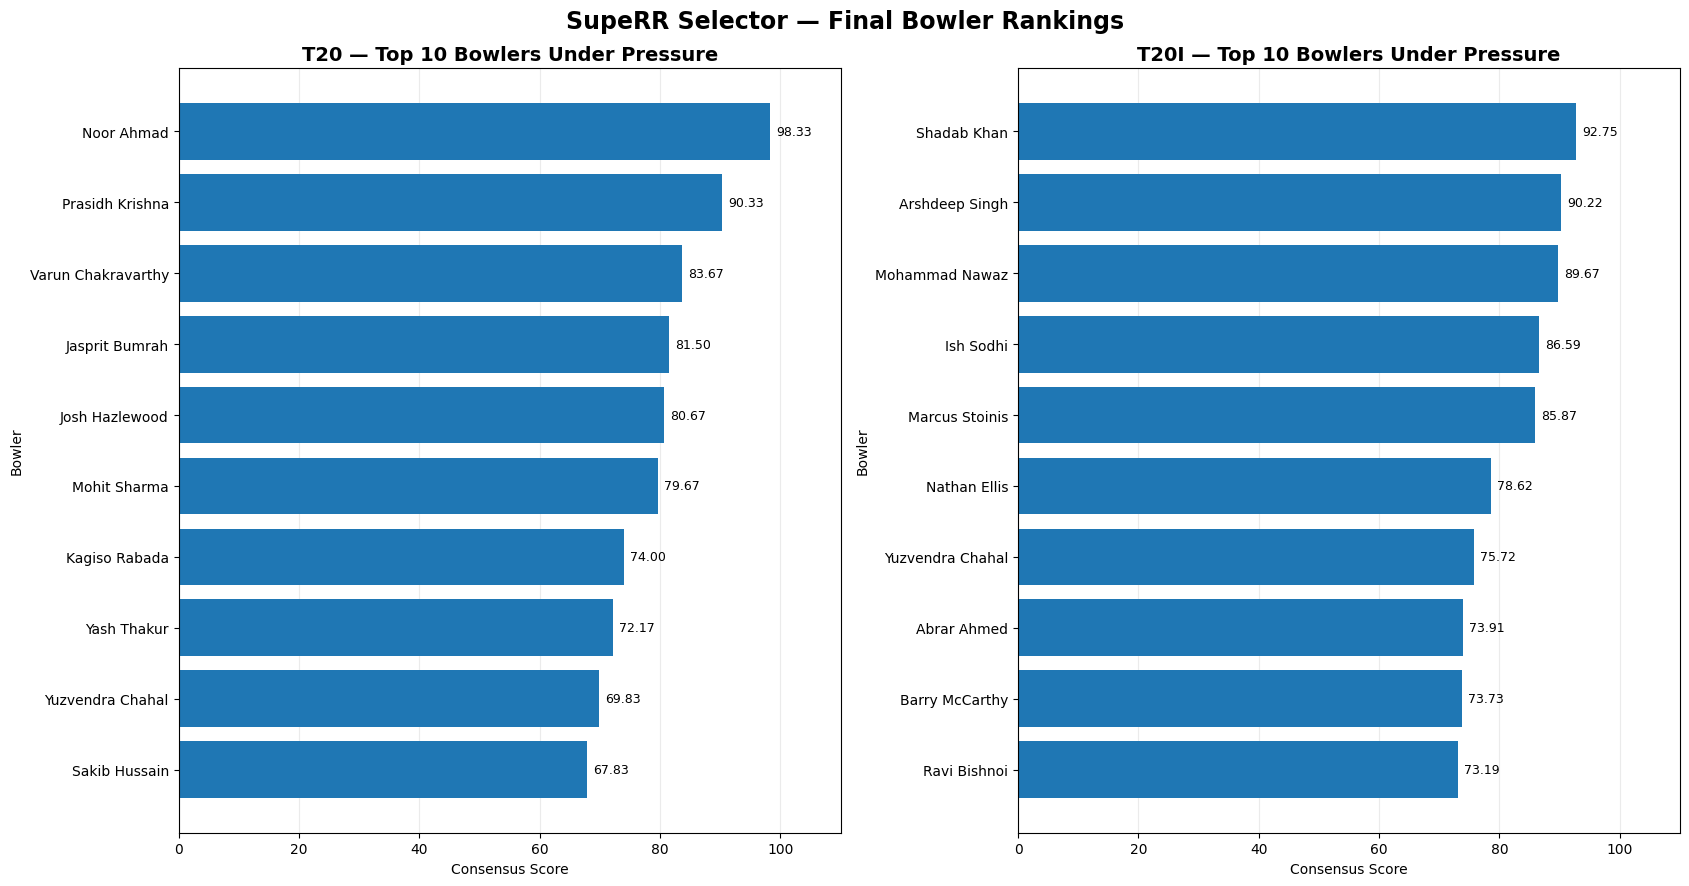

In [60]:
# STEP 56: Visualize final T20 and T20I bowling leaderboards

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(17, 9))

formats = ["T20", "T20I"]

for ax, fmt in zip(axes, formats):

    plot_data = (
        final_top10_bowlers[
            final_top10_bowlers["Format"] == fmt
        ]
        .sort_values("Consensus Score", ascending=True)
    )

    bars = ax.barh(
        plot_data["Bowler"],
        plot_data["Consensus Score"]
    )

    ax.set_title(
        f"{fmt} — Top 10 Bowlers Under Pressure",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Consensus Score")
    ax.set_ylabel("Bowler")
    ax.set_xlim(0, 110)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    # Add score labels
    for bar, score in zip(bars, plot_data["Consensus Score"]):

        ax.text(
            score + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{score:.2f}",
            va="center",
            fontsize=9
        )

plt.suptitle(
    "SupeRR Selector — Final Bowler Rankings",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

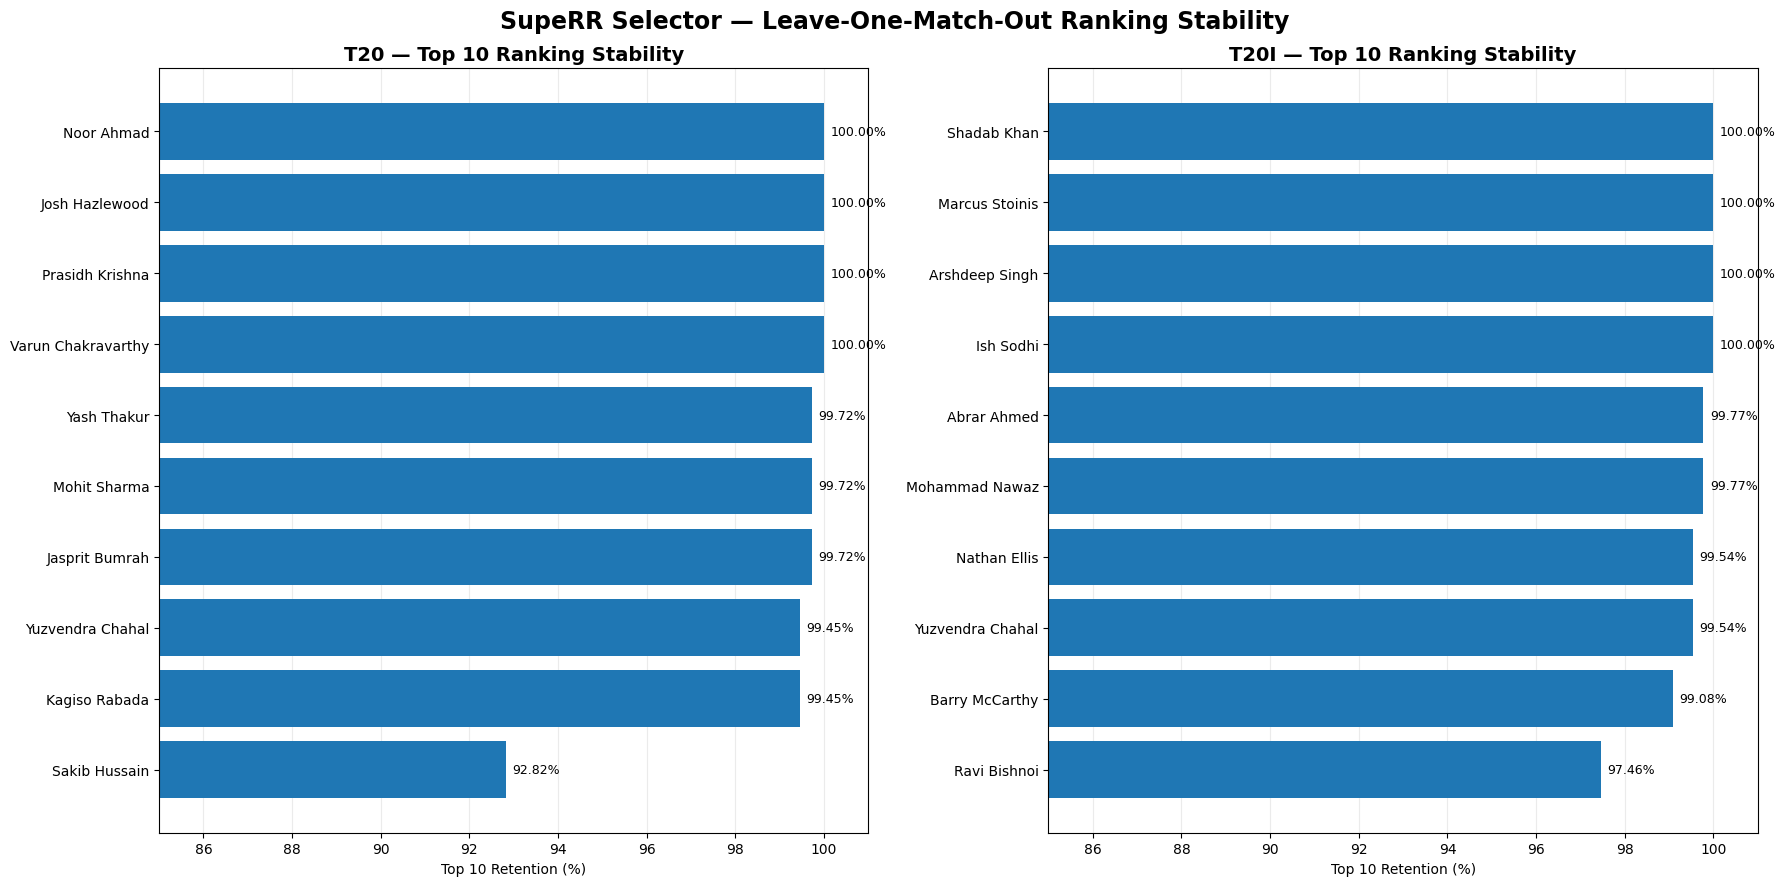

In [61]:
# STEP 57: Visualize leave-one-match-out ranking stability

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

for ax, fmt in zip(axes, ["T20", "T20I"]):

    plot_data = (
        final_top10_bowlers[
            final_top10_bowlers["Format"] == fmt
        ]
        .sort_values("Top 10 Retention (%)", ascending=True)
    )

    bars = ax.barh(
        plot_data["Bowler"],
        plot_data["Top 10 Retention (%)"]
    )

    ax.set_title(
        f"{fmt} — Top 10 Ranking Stability",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Top 10 Retention (%)")
    ax.set_xlim(85, 101)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    for bar, value in zip(
        bars,
        plot_data["Top 10 Retention (%)"]
    ):
        ax.text(
            value + 0.15,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}%",
            va="center",
            fontsize=9
        )

plt.suptitle(
    "SupeRR Selector — Leave-One-Match-Out Ranking Stability",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

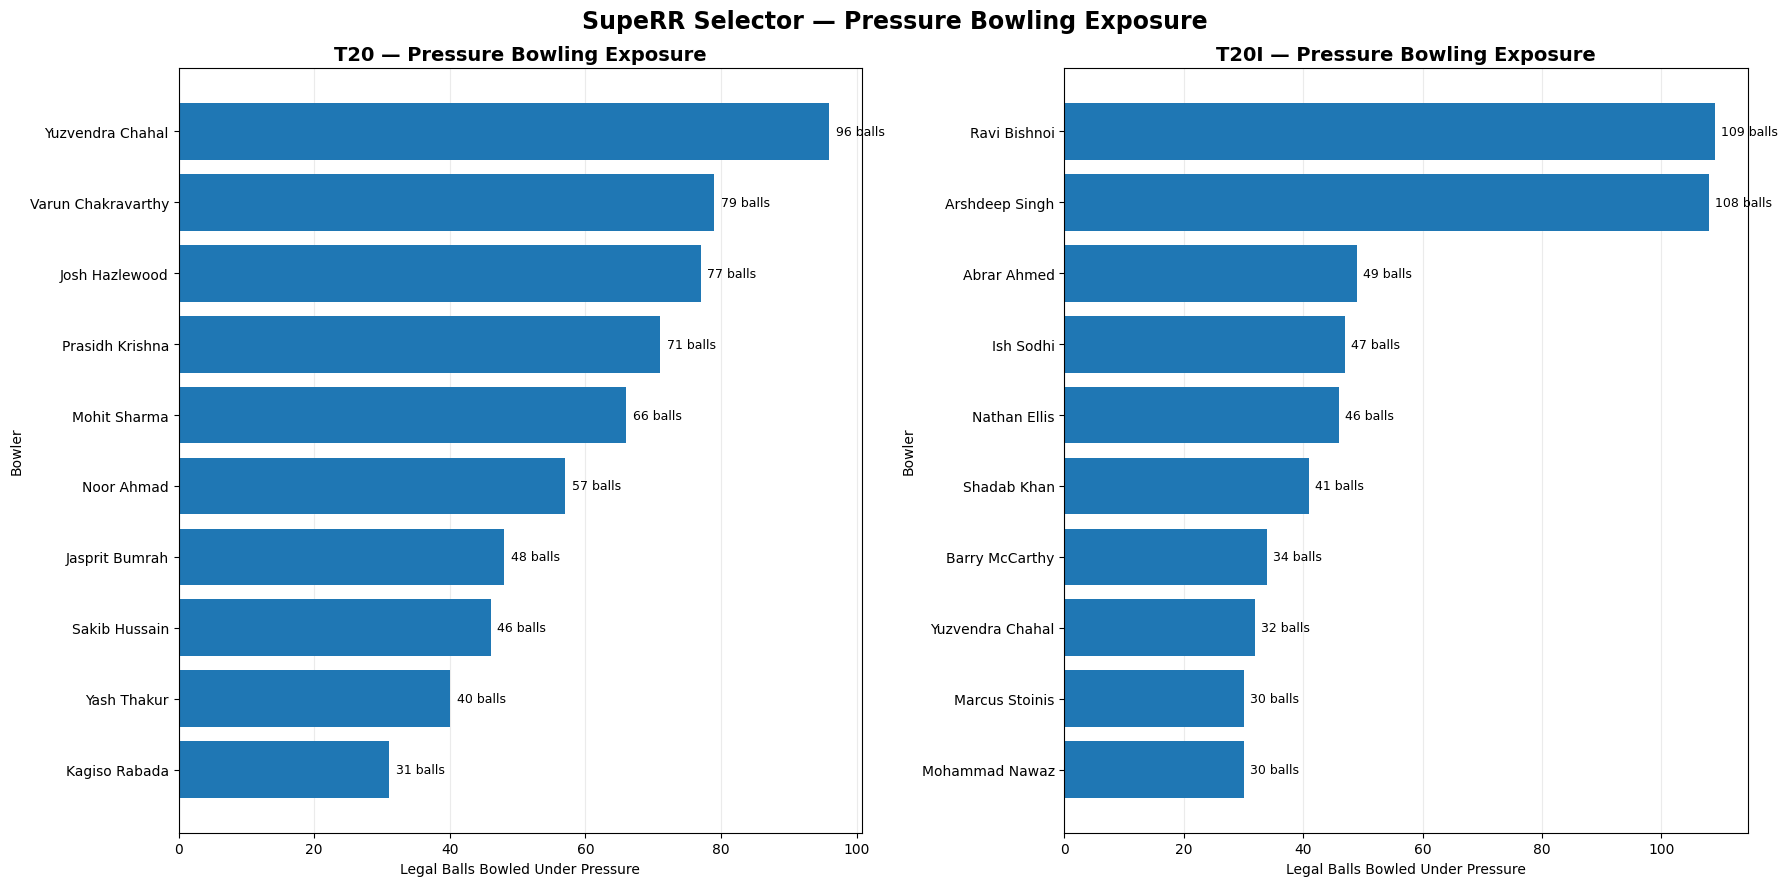

In [62]:
# STEP 58: Compare pressure exposure across final Top 10 bowlers

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

for ax, fmt in zip(axes, ["T20", "T20I"]):

    plot_data = (
        final_top10_bowlers[
            final_top10_bowlers["Format"] == fmt
        ]
        .sort_values("Pressure Legal Balls", ascending=True)
    )

    bars = ax.barh(
        plot_data["Bowler"],
        plot_data["Pressure Legal Balls"]
    )

    ax.set_title(
        f"{fmt} — Pressure Bowling Exposure",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Legal Balls Bowled Under Pressure")
    ax.set_ylabel("Bowler")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    for bar, balls in zip(
        bars,
        plot_data["Pressure Legal Balls"]
    ):
        ax.text(
            balls + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{int(balls)} balls",
            va="center",
            fontsize=9
        )

plt.suptitle(
    "SupeRR Selector — Pressure Bowling Exposure",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

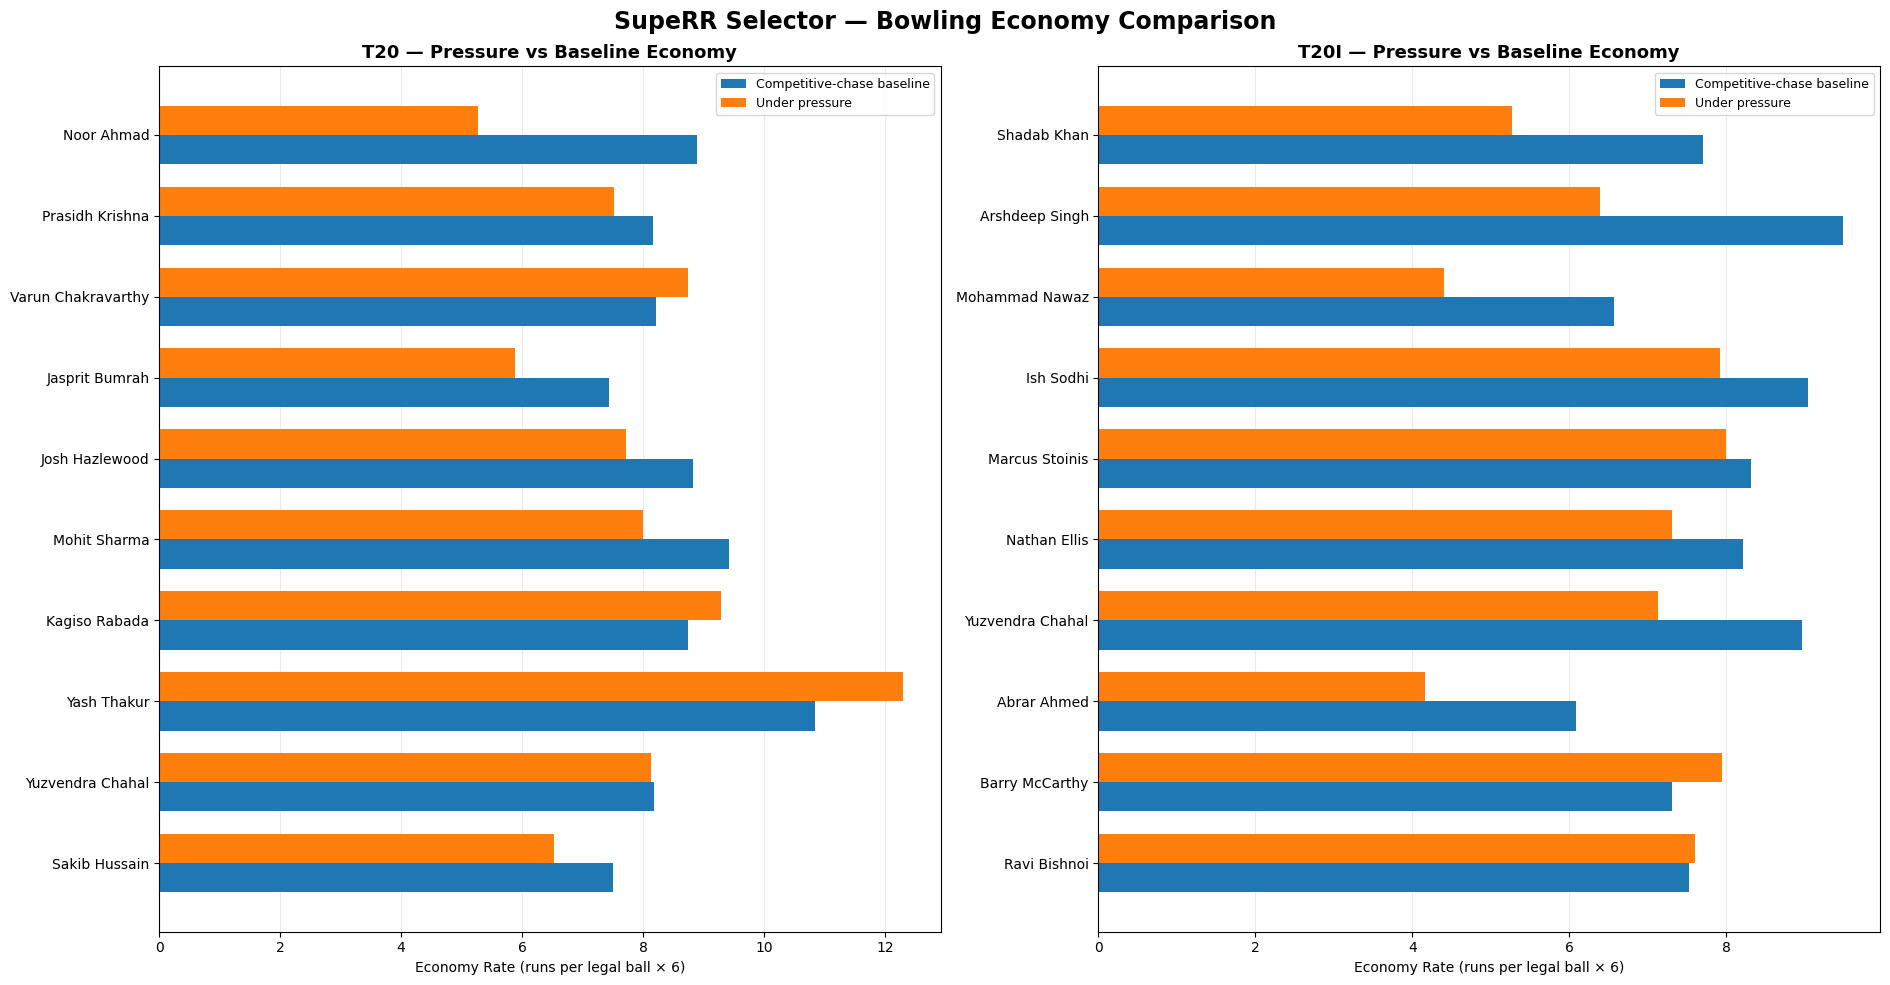


ECONOMY COMPARISON SUMMARY


KeyError: 'original_rank'

In [63]:
# STEP 59: Compare pressure economy against competitive-chase baseline

import matplotlib.pyplot as plt
import numpy as np

# Select the original Top 10 bowlers
top10_ids = final_bowler_robustness[
    final_bowler_robustness["original_rank"] <= 10
][
    ["analysis_format", "bowler_id", "bowler_name", "original_rank"]
].copy()

# Attach pressure and baseline economy metrics
economy_comparison = top10_ids.merge(
    performance_comparison[
        [
            "analysis_format",
            "bowler_id",
            "pressure_economy_lower",
            "baseline_economy_lower"
        ]
    ],
    on=["analysis_format", "bowler_id"],
    how="left",
    validate="one_to_one"
)

economy_comparison["economy_difference"] = (
    economy_comparison["pressure_economy_lower"] -
    economy_comparison["baseline_economy_lower"]
)

fig, axes = plt.subplots(1, 2, figsize=(19, 10))

for ax, fmt in zip(axes, ["T20", "T20I"]):

    plot_data = (
        economy_comparison[
            economy_comparison["analysis_format"] == fmt
        ]
        .sort_values("original_rank", ascending=False)
    )

    y = np.arange(len(plot_data))
    bar_height = 0.36

    ax.barh(
        y - bar_height / 2,
        plot_data["baseline_economy_lower"],
        height=bar_height,
        label="Competitive-chase baseline"
    )

    ax.barh(
        y + bar_height / 2,
        plot_data["pressure_economy_lower"],
        height=bar_height,
        label="Under pressure"
    )

    ax.set_yticks(y)
    ax.set_yticklabels(plot_data["bowler_name"])
    ax.set_xlabel("Economy Rate (runs per legal ball × 6)")
    ax.set_title(
        f"{fmt} — Pressure vs Baseline Economy",
        fontsize=13,
        fontweight="bold"
    )

    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)

plt.suptitle(
    "SupeRR Selector — Bowling Economy Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Numerical summary
print("\nECONOMY COMPARISON SUMMARY")
display(
    economy_comparison[
        [
            "analysis_format",
            "bowler_name",
            "baseline_economy_lower",
            "pressure_economy_lower",
            "economy_difference"
        ]
    ]
    .sort_values(["analysis_format", "original_rank"])
    .round(2)
    .reset_index(drop=True)
)

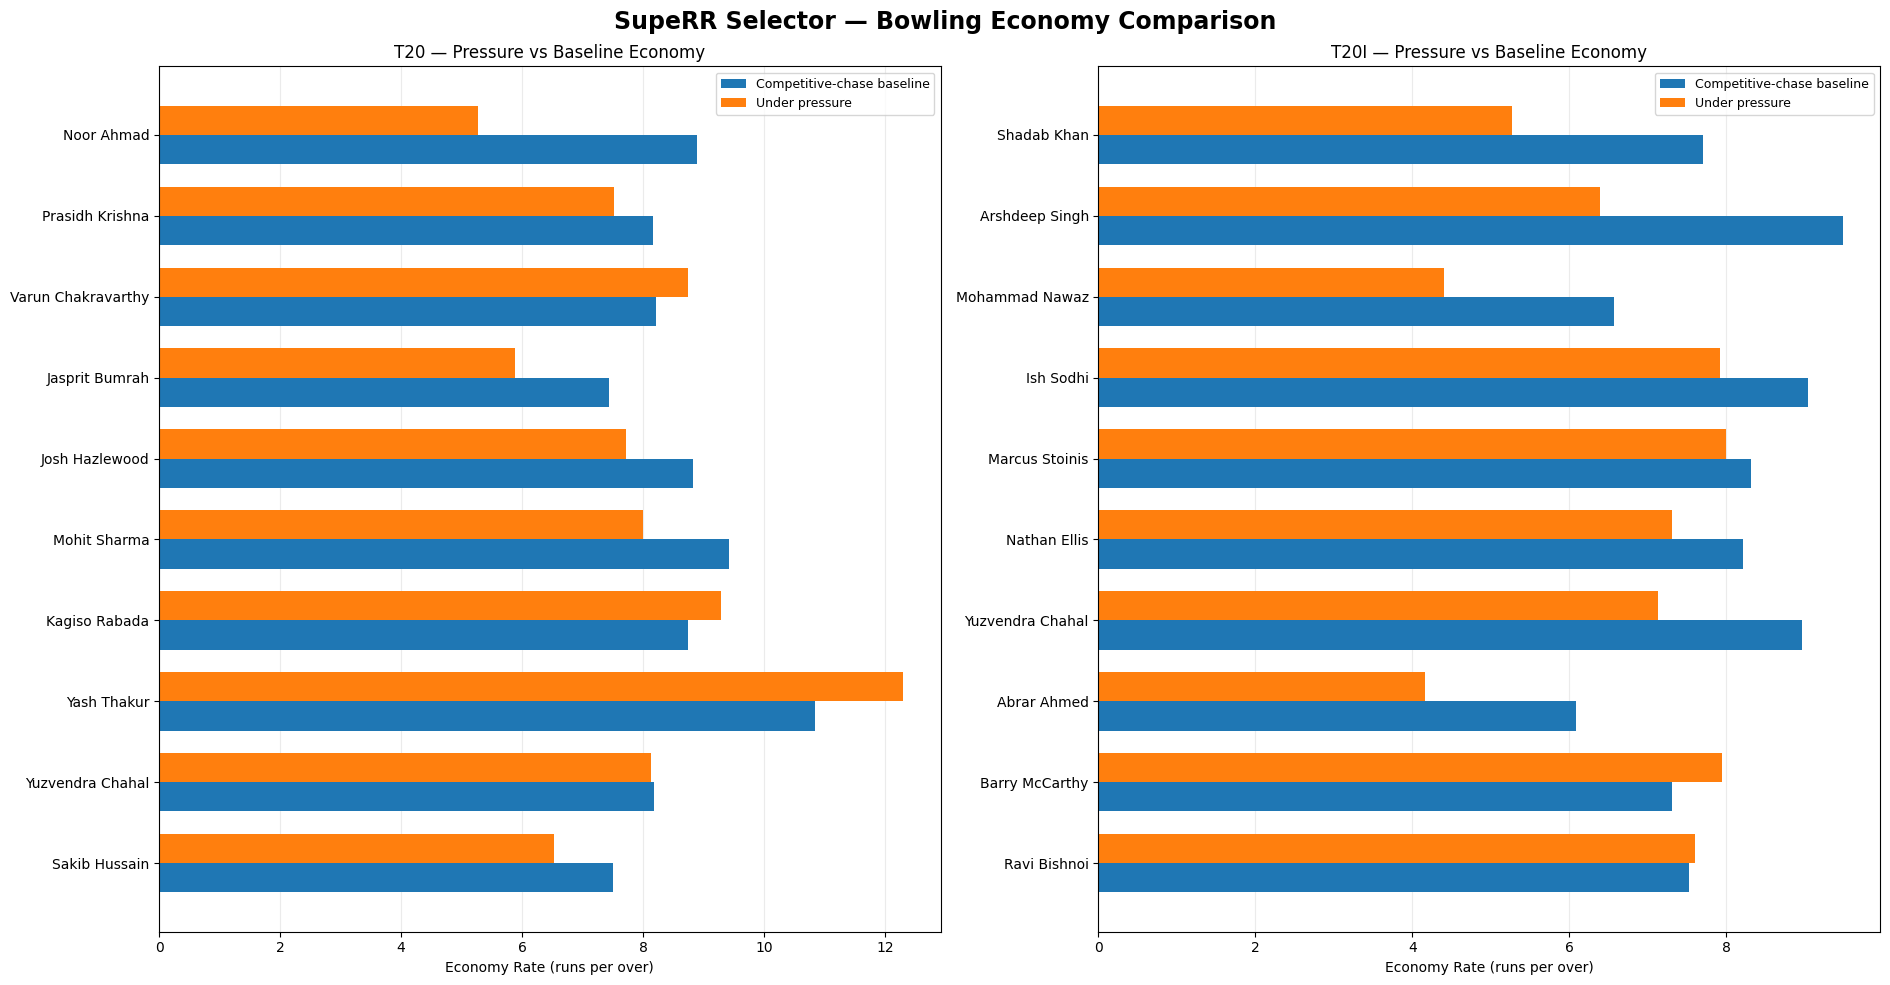


ECONOMY COMPARISON SUMMARY


,analysis_format,rank_order,bowler_name,baseline_economy_lower,pressure_economy_lower,economy_difference
0,T20,1.0,Noor Ahmad,8.89,5.26,-3.63
1,T20,2.0,Prasidh Krishna,8.17,7.52,-0.65
2,T20,3.0,Varun Chakravarthy,8.21,8.73,0.53
3,T20,4.0,Jasprit Bumrah,7.44,5.88,-1.56
4,T20,5.0,Josh Hazlewood,8.82,7.71,-1.11
5,T20,6.0,Mohit Sharma,9.42,8.00,-1.42
6,T20,7.0,Kagiso Rabada,8.74,9.29,0.55
7,T20,8.0,Yash Thakur,10.84,12.30,1.46
8,T20,9.0,Yuzvendra Chahal,8.18,8.12,-0.06
9,T20,10.0,Sakib Hussain,7.50,6.52,-0.98



SUCCESS: Economy comparison completed.


In [64]:
# STEP 59 FIX: Rebuild economy comparison and summary

import matplotlib.pyplot as plt
import numpy as np

# Select Top 10 bowlers and explicitly preserve their rank
top10_ids = (
    final_bowler_robustness[
        final_bowler_robustness["original_rank"] <= 10
    ][
        ["analysis_format", "bowler_id", "bowler_name", "original_rank"]
    ]
    .rename(columns={"original_rank": "rank_order"})
    .copy()
)

# Select only the required economy metrics
economy_metrics = performance_comparison[
    [
        "analysis_format",
        "bowler_id",
        "pressure_economy_lower",
        "baseline_economy_lower"
    ]
].copy()

# Merge without introducing rank-column collisions
economy_comparison = top10_ids.merge(
    economy_metrics,
    on=["analysis_format", "bowler_id"],
    how="left",
    validate="one_to_one"
)

# Calculate economy difference
economy_comparison["economy_difference"] = (
    economy_comparison["pressure_economy_lower"] -
    economy_comparison["baseline_economy_lower"]
)

# Check required values
assert len(economy_comparison) == 20
assert economy_comparison[
    ["pressure_economy_lower", "baseline_economy_lower"]
].notna().all().all()

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(19, 10))

for ax, fmt in zip(axes, ["T20", "T20I"]):

    plot_data = (
        economy_comparison[
            economy_comparison["analysis_format"] == fmt
        ]
        .sort_values("rank_order", ascending=False)
    )

    y = np.arange(len(plot_data))
    bar_height = 0.36

    ax.barh(
        y - bar_height / 2,
        plot_data["baseline_economy_lower"],
        height=bar_height,
        label="Competitive-chase baseline"
    )

    ax.barh(
        y + bar_height / 2,
        plot_data["pressure_economy_lower"],
        height=bar_height,
        label="Under pressure"
    )

    ax.set_yticks(y)
    ax.set_yticklabels(plot_data["bowler_name"])
    ax.set_xlabel("Economy Rate (runs per over)")
    ax.set_title(f"{fmt} — Pressure vs Baseline Economy")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)

plt.suptitle(
    "SupeRR Selector — Bowling Economy Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Display numerical comparison
print("\nECONOMY COMPARISON SUMMARY")

display(
    economy_comparison[
        [
            "analysis_format",
            "rank_order",
            "bowler_name",
            "baseline_economy_lower",
            "pressure_economy_lower",
            "economy_difference"
        ]
    ]
    .sort_values(["analysis_format", "rank_order"])
    .round(2)
    .reset_index(drop=True)
)

print("\nSUCCESS: Economy comparison completed.")

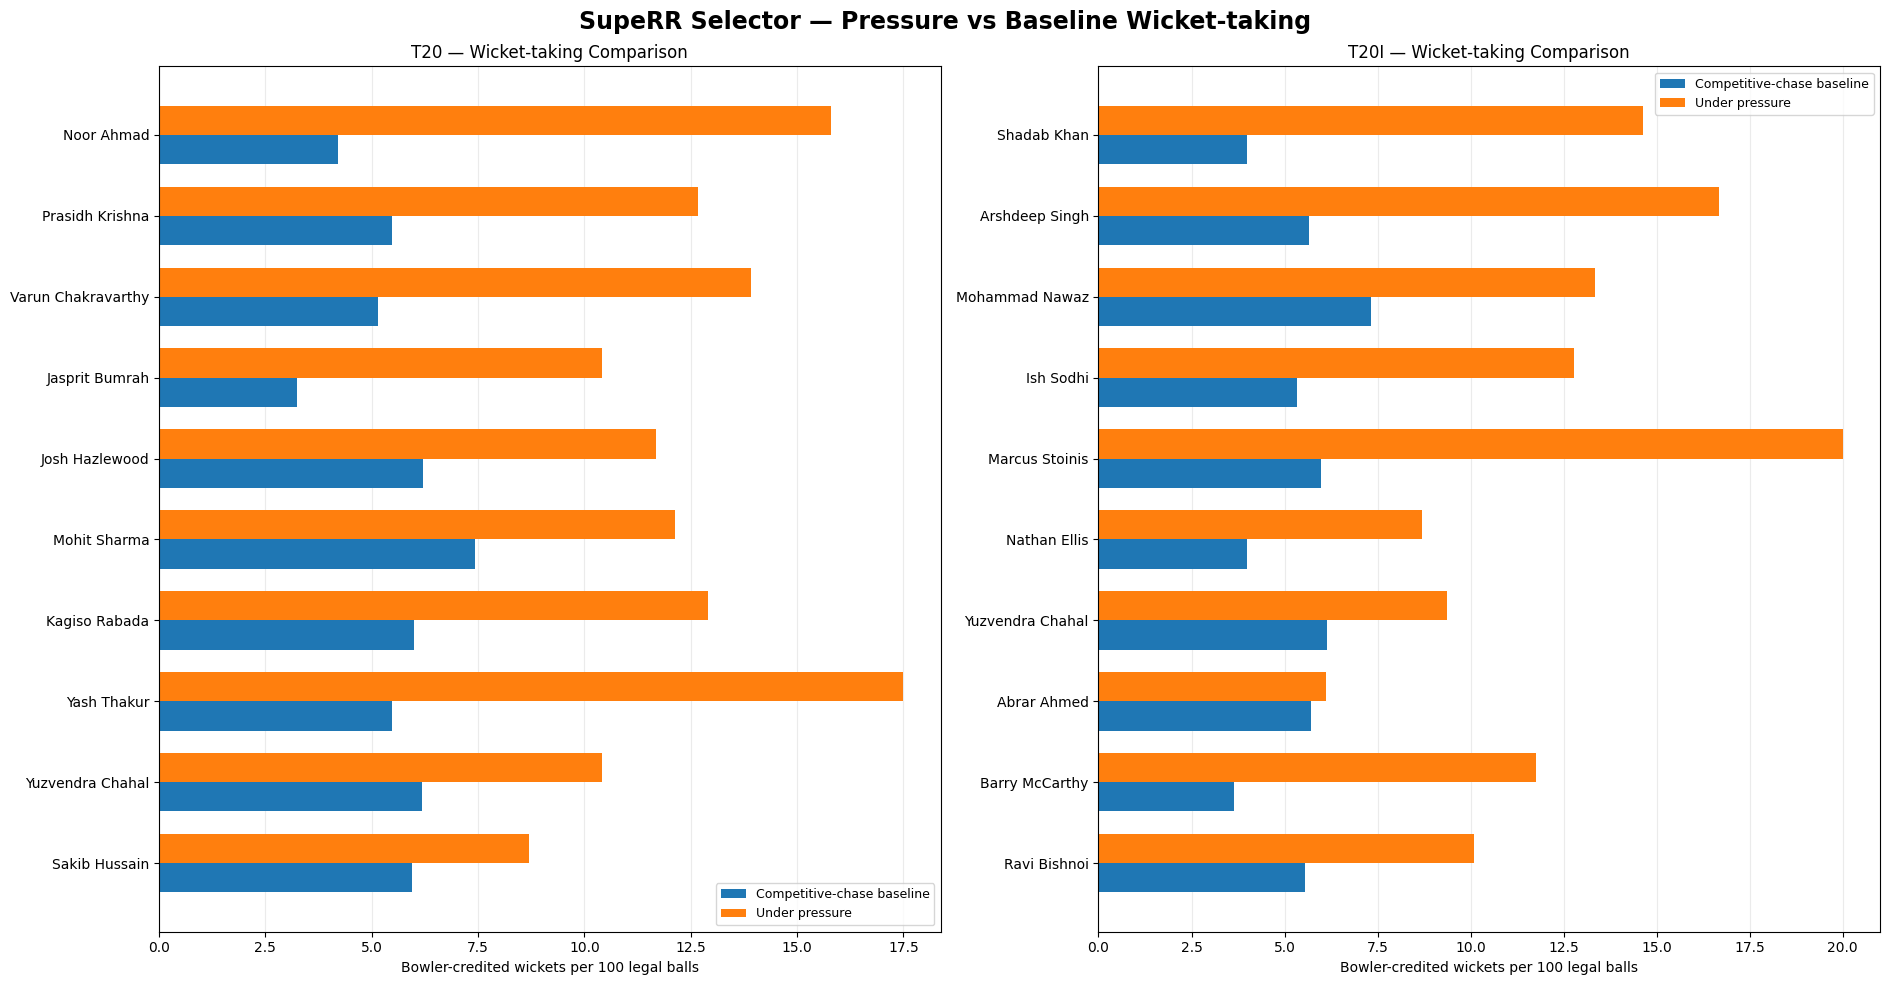


WICKET-TAKING COMPARISON


,analysis_format,rank_order,bowler_name,baseline_wickets_per_100,pressure_wickets_per_100,wicket_rate_difference
0,T20,1.0,Noor Ahmad,4.21,15.79,11.58
1,T20,2.0,Prasidh Krishna,5.47,12.68,7.21
2,T20,3.0,Varun Chakravarthy,5.14,13.92,8.78
3,T20,4.0,Jasprit Bumrah,3.23,10.42,7.18
4,T20,5.0,Josh Hazlewood,6.21,11.69,5.48
5,T20,6.0,Mohit Sharma,7.43,12.12,4.70
6,T20,7.0,Kagiso Rabada,5.99,12.90,6.92
7,T20,8.0,Yash Thakur,5.47,17.50,12.03
8,T20,9.0,Yuzvendra Chahal,6.19,10.42,4.23
9,T20,10.0,Sakib Hussain,5.95,8.70,2.74


In [65]:
# STEP 60: Pressure vs baseline wicket-taking comparison

import matplotlib.pyplot as plt
import numpy as np

# Select final Top 10 bowlers
top10_ids = (
    final_bowler_robustness[
        final_bowler_robustness["original_rank"] <= 10
    ][
        ["analysis_format", "bowler_id", "bowler_name", "original_rank"]
    ]
    .rename(columns={"original_rank": "rank_order"})
    .copy()
)

# Get wicket-taking metrics
wicket_metrics = performance_comparison[
    [
        "analysis_format",
        "bowler_id",
        "pressure_wickets_per_100",
        "baseline_wickets_per_100"
    ]
].copy()

wicket_comparison = top10_ids.merge(
    wicket_metrics,
    on=["analysis_format", "bowler_id"],
    how="left",
    validate="one_to_one"
)

wicket_comparison["wicket_rate_difference"] = (
    wicket_comparison["pressure_wickets_per_100"] -
    wicket_comparison["baseline_wickets_per_100"]
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(19, 10))

for ax, fmt in zip(axes, ["T20", "T20I"]):

    plot_data = (
        wicket_comparison[
            wicket_comparison["analysis_format"] == fmt
        ]
        .sort_values("rank_order", ascending=False)
    )

    y = np.arange(len(plot_data))
    height = 0.36

    ax.barh(
        y - height / 2,
        plot_data["baseline_wickets_per_100"],
        height=height,
        label="Competitive-chase baseline"
    )

    ax.barh(
        y + height / 2,
        plot_data["pressure_wickets_per_100"],
        height=height,
        label="Under pressure"
    )

    ax.set_yticks(y)
    ax.set_yticklabels(plot_data["bowler_name"])
    ax.set_xlabel("Bowler-credited wickets per 100 legal balls")
    ax.set_title(f"{fmt} — Wicket-taking Comparison")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)

plt.suptitle(
    "SupeRR Selector — Pressure vs Baseline Wicket-taking",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Numerical summary
print("\nWICKET-TAKING COMPARISON")

display(
    wicket_comparison[
        [
            "analysis_format",
            "rank_order",
            "bowler_name",
            "baseline_wickets_per_100",
            "pressure_wickets_per_100",
            "wicket_rate_difference"
        ]
    ]
    .sort_values(["analysis_format", "rank_order"])
    .round(2)
    .reset_index(drop=True)
)

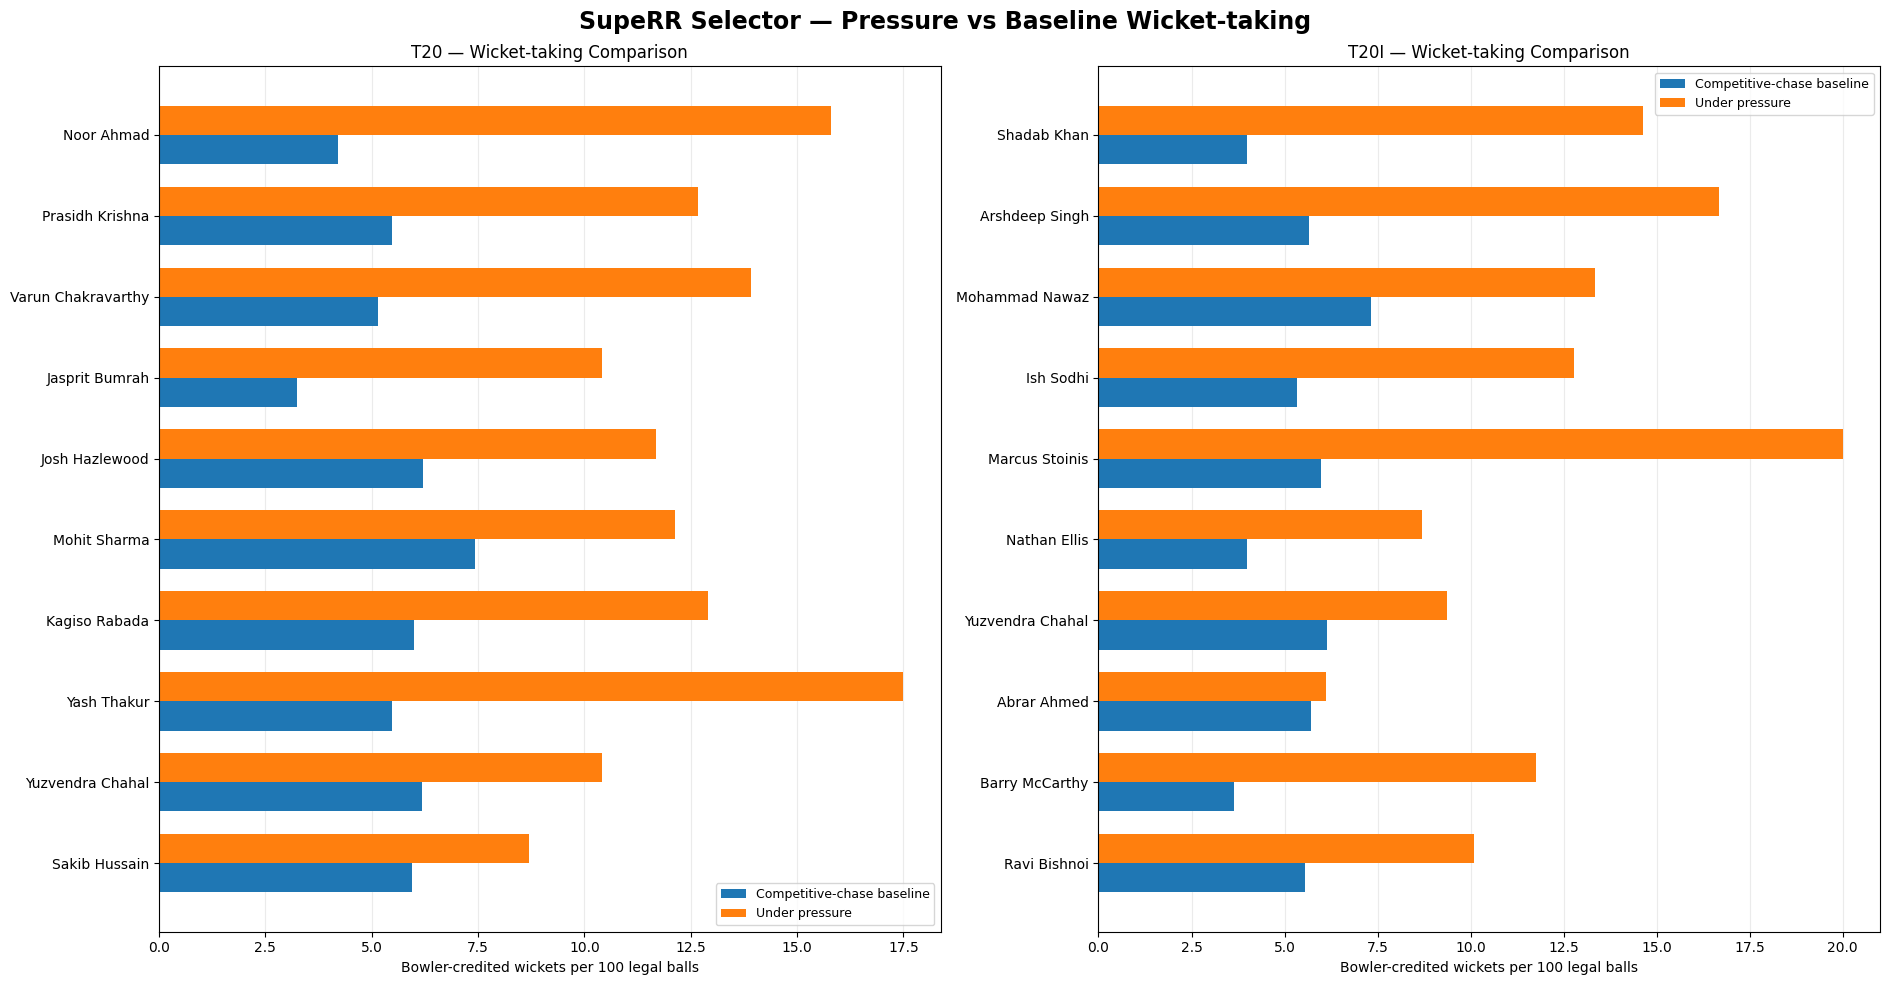


WICKET-TAKING COMPARISON


,analysis_format,rank_order,bowler_name,baseline_wickets_per_100,pressure_wickets_per_100,wicket_rate_difference
0,T20,1.0,Noor Ahmad,4.21,15.79,11.58
1,T20,2.0,Prasidh Krishna,5.47,12.68,7.21
2,T20,3.0,Varun Chakravarthy,5.14,13.92,8.78
3,T20,4.0,Jasprit Bumrah,3.23,10.42,7.18
4,T20,5.0,Josh Hazlewood,6.21,11.69,5.48
5,T20,6.0,Mohit Sharma,7.43,12.12,4.70
6,T20,7.0,Kagiso Rabada,5.99,12.90,6.92
7,T20,8.0,Yash Thakur,5.47,17.50,12.03
8,T20,9.0,Yuzvendra Chahal,6.19,10.42,4.23
9,T20,10.0,Sakib Hussain,5.95,8.70,2.74


In [66]:
# STEP 60: Pressure vs baseline wicket-taking comparison

import matplotlib.pyplot as plt
import numpy as np

# Select final Top 10 bowlers
top10_ids = (
    final_bowler_robustness[
        final_bowler_robustness["original_rank"] <= 10
    ][
        ["analysis_format", "bowler_id", "bowler_name", "original_rank"]
    ]
    .rename(columns={"original_rank": "rank_order"})
    .copy()
)

# Get wicket-taking metrics
wicket_metrics = performance_comparison[
    [
        "analysis_format",
        "bowler_id",
        "pressure_wickets_per_100",
        "baseline_wickets_per_100"
    ]
].copy()

wicket_comparison = top10_ids.merge(
    wicket_metrics,
    on=["analysis_format", "bowler_id"],
    how="left",
    validate="one_to_one"
)

wicket_comparison["wicket_rate_difference"] = (
    wicket_comparison["pressure_wickets_per_100"] -
    wicket_comparison["baseline_wickets_per_100"]
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(19, 10))

for ax, fmt in zip(axes, ["T20", "T20I"]):

    plot_data = (
        wicket_comparison[
            wicket_comparison["analysis_format"] == fmt
        ]
        .sort_values("rank_order", ascending=False)
    )

    y = np.arange(len(plot_data))
    height = 0.36

    ax.barh(
        y - height / 2,
        plot_data["baseline_wickets_per_100"],
        height=height,
        label="Competitive-chase baseline"
    )

    ax.barh(
        y + height / 2,
        plot_data["pressure_wickets_per_100"],
        height=height,
        label="Under pressure"
    )

    ax.set_yticks(y)
    ax.set_yticklabels(plot_data["bowler_name"])
    ax.set_xlabel("Bowler-credited wickets per 100 legal balls")
    ax.set_title(f"{fmt} — Wicket-taking Comparison")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)

plt.suptitle(
    "SupeRR Selector — Pressure vs Baseline Wicket-taking",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Numerical summary
print("\nWICKET-TAKING COMPARISON")

display(
    wicket_comparison[
        [
            "analysis_format",
            "rank_order",
            "bowler_name",
            "baseline_wickets_per_100",
            "pressure_wickets_per_100",
            "wicket_rate_difference"
        ]
    ]
    .sort_values(["analysis_format", "rank_order"])
    .round(2)
    .reset_index(drop=True)
)